In [1]:
# Cell 1: definitions only. Arrays of states have shape (n_samples, n_dofs).
# Implements the BCKE representation and decoder-aware predictor in bcke_revised.tex.
# Prediction candidates include the original shared Gaussian as an exact baseline.
# Requires Python 3.10+, NumPy, pandas, PyTorch 2+, matplotlib, and IPython.
# No neural-network layers or neural-network optimizer are used.
import json
import math
import time
import warnings
from dataclasses import dataclass, asdict, replace
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display


@dataclass(frozen=True)
class BCKEConfig:
    p: int = 8
    d: int = 4
    max_total_dimension: int = 12  # fixed admissible budget p+d <= m_max
    k_start: int = 15
    n_folds: int = 5
    virtual_fractions: tuple = (0.25, 0.50, 0.75)
    lambda_phi: float = 1e-3
    lambda_lambda: float = 1e-3
    sigma_phi_factor: float = 1.0
    sigma_lambda_factor: float = 1.0
    eta_a: float = 1.0
    alpha_x: float = 1.0
    alpha_z: float = 1.0
    beta_f: float = 1.0
    beta_b: float = 1.0
    omega_delta: float = 1.0
    gamma_diff: float = 0.0  # 0: core BCKE; positive: separate BCKE-D variant.
    allow_ablation: bool = False
    distance_quantile: float = 0.5
    affinity_factors: tuple = (1.0, 1.0, 1.0, 1.0)  # X, hat Z, V, Lambda V
    bandwidth_fallback: float = 1.0  # declared positive length if all distances vanish
    eps_scale: float = 1e-12
    degree_safe: float = 1e-14
    bandwidth_degree_floor: float = 1e-10
    bandwidth_growth: float = 1.5
    max_bandwidth_expansions: int = 60
    rank_eigenvalue_rtol: float = 1e-12
    residual_zero_rtol: float = 0.0  # exact-zero branch; >0 is a reported numerical approximation
    armijo_c: float = 1e-4
    armijo_rho: float = 0.5
    initial_step: float = 1.0
    grad_tol: float = 1e-7
    max_backtracks: int = 40
    verbose_every: int = 5
    diff_chunk_size: int = 64
    seed: int = 42
    device: str = "cpu"


@dataclass(frozen=True)
class KernelBlockConfig:
    family: str = "gaussian"       # "gaussian" or "matern52"
    sigma_factor: float = 1.0       # multiplier of a FIT-ONLY distance quantile
    ridge: float = 1e-4             # lambda for the sum-of-squares KRR objective
    axis_factors: tuple = ()        # () = isotropic; positive factors per input column


@dataclass(frozen=True)
class ParameterCandidate:
    name: str
    a: KernelBlockConfig
    z: KernelBlockConfig
    centered: bool = True
    correction_nu: object = None   # None: B=0; a positive number: decoder correction
    shared_baseline: bool = False


@dataclass(frozen=True)
class PredictionConfig:
    # Exact old shared-Gaussian, zero-mean predictor remains in the candidate set.
    sigma_factors: tuple = (0.5, 1.0, 2.0, 4.0)
    ridges: tuple = (1e-8, 1e-6, 1e-4, 1e-2)
    block_pairs: tuple = (
        (KernelBlockConfig("gaussian", 1.0, 1e-4), KernelBlockConfig("gaussian", 0.5, 1e-6)),
        (KernelBlockConfig("gaussian", 2.0, 1e-4), KernelBlockConfig("matern52", 1.0, 1e-4)),
        (KernelBlockConfig("matern52", 1.0, 1e-4), KernelBlockConfig("matern52", 0.5, 1e-4)),
    )
    correction_nus: tuple = (0.1, 1.0)
    correction_max_iterations: int = 200
    correction_grad_tol: float = 1e-7
    correction_initial_step: float = 1.0
    correction_armijo_c: float = 1e-4
    correction_armijo_rho: float = 0.5
    correction_max_backtracks: int = 40
    correction_verbose_every: int = 0
    distance_quantile: float = 0.5
    bandwidth_fallback: float = 1.0


def validate_prediction_config(cfg):
    if not (0 <= cfg.distance_quantile <= 1 and np.isfinite(cfg.bandwidth_fallback)
            and cfg.bandwidth_fallback > 0):
        raise ValueError("Invalid prediction bandwidth rule.")
    for name in ("correction_max_iterations", "correction_max_backtracks", "correction_verbose_every"):
        v = getattr(cfg, name)
        if not isinstance(v, (int, np.integer)) or v < 0:
            raise ValueError(f"{name} must be a nonnegative integer.")
    if not (0 < cfg.correction_armijo_c < 1 and 0 < cfg.correction_armijo_rho < 1):
        raise ValueError("Correction Armijo constants must lie in (0,1).")
    for v in (cfg.correction_grad_tol, cfg.correction_initial_step):
        if not np.isfinite(v) or v <= 0:
            raise ValueError("Correction step and tolerance must be positive.")
    for v in candidate_values(cfg.sigma_factors) + candidate_values(cfg.ridges):
        if not np.isfinite(v) or v <= 0:
            raise ValueError("Baseline bandwidth multipliers and ridges must be positive.")
    for nu in cfg.correction_nus:
        if not np.isfinite(nu) or nu <= 0:
            raise ValueError("Use a positive correction_nu; the uncorrected candidate is added automatically.")
    for pair in cfg.block_pairs:
        if len(pair) != 2 or not all(isinstance(b, KernelBlockConfig) for b in pair):
            raise ValueError("Each block_pairs entry must be a pair of KernelBlockConfig objects.")


def parameter_kernel(X, Y, lengths, family):
    lengths = np.asarray(lengths, dtype=np.float64)
    if X.shape[1] != Y.shape[1] or len(lengths) != X.shape[1]:
        raise ValueError("Kernel input dimensions and length vector must agree.")
    if not np.isfinite(lengths).all() or np.any(lengths <= 0):
        raise ValueError("All active parameter length scales must be finite and positive.")
    d2 = pair_sq_np(X/lengths, Y/lengths)
    if family == "gaussian":
        return np.exp(-d2)
    if family == "matern52":
        t = np.sqrt(5.0*d2)
        return (1.0+t+t*t/3.0)*np.exp(-t)
    raise ValueError("Parameter kernel family must be 'gaussian' or 'matern52'.")


def prediction_candidates(cfg, problem):
    """Fixed finite candidate list; never built from validation/test targets."""
    validate_prediction_config(cfg)
    candidates = []
    for factor, ridge in product(candidate_values(cfg.sigma_factors), candidate_values(cfg.ridges)):
        block = KernelBlockConfig("gaussian", float(factor), float(ridge))
        candidates.append(ParameterCandidate(f"shared_gaussian_s{factor:g}_r{ridge:g}",
                                             block, block, False, None, True))
    for index, (a, z) in enumerate(cfg.block_pairs):
        base = ParameterCandidate(f"block_{index}_uncorrected", a, z)
        candidates.append(base)
        if problem.d:
            candidates.extend(replace(base, name=f"block_{index}_nu{nu:g}", correction_nu=float(nu))
                              for nu in cfg.correction_nus)
    # The a block is absent for p=0; the z block is absent for d=0.
    # Do not repeat identical active models just because an absent block differs.
    unique, seen = [], set()
    for spec in candidates:
        key = json.dumps(dict(a=asdict(spec.a) if problem.p else None,
                              z=asdict(spec.z) if problem.d else None,
                              centered=spec.centered if problem.p+problem.d else False,
                              correction_nu=spec.correction_nu if problem.d else None), sort_keys=True)
        if key not in seen:
            unique.append(spec)
            seen.add(key)
    return unique


class DecoderAwareParameterApproximation:
    """Fit-only block KRR and optional decoder-aware correction; no online solve.

    State rows: (n_samples, n_dofs). Coordinate columns: (p+d, n_queries).
    No representation variable is changed during this predictor fitting.
    """
    def __init__(self, problem, spec, cfg):
        validate_prediction_config(cfg)
        self.problem, self.spec, self.cfg = problem, spec, cfg
        self.mean_mu = problem.mu.mean(axis=0)
        self.active = np.ptp(problem.mu, axis=0) > 0
        self.std_mu = problem.mu.std(axis=0)[self.active]
        if np.any(self.std_mu <= 0):
            raise ValueError("Nonconstant parameter component has unresolved standard deviation.")
        self.X = self.transform(problem.mu)
        self.Y = problem.fitting_coordinates()  # [A; hat Z], never decoder centers Z
        self.a_block = self._fit_block(self.Y[:problem.p], spec.a) if problem.p else None
        self.z_block = self._fit_block(self.Y[problem.p:], spec.z) if problem.d else None
        self.B = np.zeros((problem.d, problem.n), dtype=np.float64)
        self.correction_history = pd.DataFrame()
        self.correction_status = "not requested" if problem.d else "no nonlinear block"
        self.correction_initial_error = np.nan
        self.correction_final_error = np.nan
        self.feature_norm_max = np.nan
        if problem.d:
            block = self.z_block
            self.features = np.linalg.solve(block["cholesky"], block["K"])
            self.z0_training = block["mean"][:, None]+block["coefficients"]@block["K"]
            self.feature_norm_max = float(np.linalg.norm(self.features, axis=0).max())
            if self.feature_norm_max > 1.0+1e-7:
                raise FloatingPointError("Whitened parameter features violate the kernel Schur bound.")
            self.correction_initial_error = self._correction_value_gradient(self.B, gradient=False)[1]
            self.correction_final_error = self.correction_initial_error
            if spec.correction_nu is not None:
                if not np.isfinite(spec.correction_nu) or spec.correction_nu <= 0:
                    raise ValueError("correction_nu must be positive or None.")
                self._fit_correction()
            # B @ L^{-1}, computed by the transposed triangular system.
            block["online_coefficients"] = block["coefficients"] + np.linalg.solve(
                block["cholesky"].T, self.B.T).T

    def transform(self, parameters):
        mu = parameter_array(parameters)
        if mu.shape[1] != self.mean_mu.size:
            raise ValueError("Query parameter dimension differs from fitting parameters.")
        return (mu[:, self.active]-self.mean_mu[self.active])/self.std_mu

    def _fit_block(self, targets, config):
        if config.family not in ("gaussian", "matern52"):
            raise ValueError("Unknown block kernel family.")
        if not all(np.isfinite(v) and v > 0 for v in (config.sigma_factor, config.ridge)):
            raise ValueError("Block bandwidth factors and ridges must be positive.")
        q = self.X.shape[1]
        axes = np.asarray(config.axis_factors, dtype=float)
        if axes.size == 0:
            axes = np.ones(q)
        elif axes.ndim != 1 or axes.size not in (q, self.mean_mu.size):
            raise ValueError("axis_factors must have one entry per original or active parameter column.")
        else:
            if not np.isfinite(axes).all() or np.any(axes <= 0):
                raise ValueError("axis_factors must be positive and finite.")
            if axes.size == self.mean_mu.size:
                axes = axes[self.active]
        scale = positive_length(pair_sq_np(self.X)[np.triu_indices(self.problem.n, 1)],
                                self.cfg.distance_quantile, config.sigma_factor,
                                self.cfg.bandwidth_fallback)
        lengths = scale*axes
        K = parameter_kernel(self.X, self.X, lengths, config.family)
        L = np.linalg.cholesky((K+K.T)/2+config.ridge*np.eye(self.problem.n))
        mean = targets.mean(axis=1) if self.spec.centered else np.zeros(targets.shape[0])
        coefficients = np.linalg.solve(L.T, np.linalg.solve(L, (targets-mean[:, None]).T)).T
        if not np.isfinite(coefficients).all():
            raise FloatingPointError("Nonfinite parameter regression coefficients.")
        return dict(family=config.family, lengths=lengths, mean=mean, K=K, cholesky=L,
                    coefficients=coefficients, online_coefficients=coefficients.copy())

    def _correction_value_gradient(self, B, gradient=True):
        """Exact sample-space objective/analytic gradient from revised eqs. (prediction_*)."""
        P = self.problem
        q = self.z0_training+B@self.features
        K = np.exp(-pair_sq_np(P.Z_np.T, q.T)/P.sigma_lambda**2)
        coefficients = P.C_lambda_np@K
        error_coefficients = np.eye(P.n)-coefficients
        GRerror = P.GR_np@error_coefficients
        error = float(np.sum(error_coefficients*GRerror)/P.residual_energy)
        # This quadratic form can be slightly negative only from cancellation.
        if error < -1e-10 or not np.isfinite(error):
            raise FloatingPointError("Residual correction loss is numerically unresolved.")
        error = max(error, 0.0)
        nu = 0.0 if self.spec.correction_nu is None else float(self.spec.correction_nu)
        objective = error+nu/2*float(np.sum(B*B))
        if not gradient:
            return objective, error
        V = P.C_lambda_np.T@GRerror
        # gamma_i^T V_i = -2/sigma^2 * (q_i sum_j k_ji V_ji - Z(k_i * V_i)).
        KV = K*V
        inner = (-2/P.sigma_lambda**2)*(q*KV.sum(axis=0)[None, :]-P.Z_np@KV)
        grad = (-2/P.residual_energy)*inner@self.features.T+nu*B
        if not np.isfinite(objective) or not np.isfinite(grad).all():
            raise FloatingPointError("Nonfinite decoder correction objective or gradient.")
        return objective, error, grad

    def _fit_correction(self):
        cfg, B = self.cfg, self.B.copy()
        rows, norm0 = [], None
        begin = time.perf_counter()
        for iteration in range(cfg.correction_max_iterations+1):
            objective, error, gradient = self._correction_value_gradient(B)
            norm = float(np.linalg.norm(gradient))
            norm0 = norm if norm0 is None else norm0
            record = dict(iteration=iteration, objective=objective, residual_error=error,
                          grad_norm=norm, correction_norm=float(np.linalg.norm(B)),
                          step=np.nan, backtracks=np.nan, elapsed_seconds=time.perf_counter()-begin)
            rows.append(record)
            if cfg.correction_verbose_every and iteration % cfg.correction_verbose_every == 0:
                print(f"    correction {iteration:4d}: F={objective:.6g}, E={error:.6g}, grad={norm:.3e}")
            if norm <= cfg.correction_grad_tol*max(1.0, norm0):
                self.correction_status = "gradient tolerance reached"
                break
            if iteration == cfg.correction_max_iterations:
                self.correction_status = "iteration limit (not a stationarity certificate)"
                break
            accepted = False
            for backtracks in range(cfg.correction_max_backtracks+1):
                step = cfg.correction_initial_step*cfg.correction_armijo_rho**backtracks
                trial = B-step*gradient
                try:
                    trial_value, _ = self._correction_value_gradient(trial, gradient=False)
                    if np.isfinite(trial_value) and trial_value <= objective-cfg.correction_armijo_c*step*norm**2:
                        B, accepted = trial, True
                        record.update(step=step, backtracks=backtracks)
                        break
                except FloatingPointError:
                    continue
            if not accepted:
                self.correction_status = "backtracking limit (numerical stop, not convergence)"
                break
        self.B = B
        self.correction_history = pd.DataFrame(rows)
        self.correction_final_error = self._correction_value_gradient(B, gradient=False)[1]
        tol = 1e-9*max(1., self.correction_initial_error)
        if self.correction_final_error > self.correction_initial_error+tol:
            raise FloatingPointError("Correction violated its training-descent safeguard.")

    def coordinates(self, parameters, corrected=True):
        Xq = self.transform(parameters)
        blocks = []
        for block in (self.a_block, self.z_block):
            if block is not None:
                coef = block["online_coefficients"] if corrected else block["coefficients"]
                K = parameter_kernel(self.X, Xq, block["lengths"], block["family"])
                blocks.append(block["mean"][:, None]+coef@K)
        return np.vstack(blocks) if blocks else np.empty((0, len(Xq)))

    def predict(self, parameters):
        return self.problem.states_from_coordinates(self.coordinates(parameters))

    def summary(self):
        result = dict(candidate=self.spec.name, specification=asdict(self.spec),
                      correction_status=self.correction_status,
                      correction_initial_error=self.correction_initial_error,
                      correction_final_error=self.correction_final_error,
                      correction_norm=float(np.linalg.norm(self.B)),
                      max_fitting_feature_norm=self.feature_norm_max)
        for name, block in (("a", self.a_block), ("z", self.z_block)):
            result[f"lengths_{name}"] = [] if block is None else block["lengths"].tolist()
        return result


def correction_derivative_check(predictor, h=1e-6, tolerance=5e-5, seed=42):
    """Analytic correction gradient versus PyTorch and a central difference."""
    P = predictor.problem
    if not P.d:
        return pd.DataFrame([dict(term="correction", status="not applicable: d=0", passed=True)])
    rng = np.random.default_rng(seed)
    B = predictor.B + 1e-3*rng.normal(size=predictor.B.shape)
    direction = rng.normal(size=B.shape)
    direction /= np.linalg.norm(direction)
    value, error, grad = predictor._correction_value_gradient(B)
    explicit = float(np.sum(grad*direction))
    fd = (predictor._correction_value_gradient(B+h*direction, False)[0]
          -predictor._correction_value_gradient(B-h*direction, False)[0])/(2*h)
    Bt = P.tensor(B).requires_grad_(True)
    q = P.tensor(predictor.z0_training)+Bt@P.tensor(predictor.features)
    kval = torch.exp(-pair_sq_t(P.tensor(P.Z_np), q)/P.sigma_lambda**2)
    delta = torch.eye(P.n, dtype=torch.float64, device=P.device)-P.tensor(P.C_lambda_np)@kval
    obj = (delta*(P.tensor(P.GR_np)@delta)).sum()/P.residual_energy
    if predictor.spec.correction_nu is not None:
        obj = obj+float(predictor.spec.correction_nu)/2*Bt.square().sum()
    ad, = torch.autograd.grad(obj, Bt)
    autodiff = float((ad*P.tensor(direction)).sum().detach())
    den = max(1., abs(explicit), abs(autodiff), abs(fd))
    aderr, fderr = abs(explicit-autodiff)/den, abs(explicit-fd)/den
    passed = aderr < tolerance and fderr < tolerance and abs(float(obj.detach())-value) < tolerance*max(1., abs(value))
    table = pd.DataFrame([dict(term="decoder-aware correction", explicit=explicit,
                              autodiff=autodiff, finite_difference=fd,
                              autodiff_discrepancy=aderr, fd_discrepancy=fderr, passed=passed)])
    if not passed:
        raise AssertionError("Prediction correction gradient audit failed:\n"+table.to_string(index=False))
    return table


def candidate_values(x):
    vals = (x,) if np.isscalar(x) else tuple(x)
    if not vals:
        raise ValueError("Candidate lists must not be empty.")
    return vals


def parameter_array(mu):
    mu = np.asarray(mu, dtype=np.float64)
    if mu.ndim == 1:
        mu = mu[:, None]
    if mu.ndim != 2 or len(mu) == 0 or not np.isfinite(mu).all():
        raise ValueError("Parameters must be a finite (n_samples, q) array.")
    return mu


def weight_apply(W, X):
    """W times a column-oriented state matrix; W may be diagonal or SPD."""
    return W[:, None] * X if W.ndim == 1 else W @ X


def weighted_norm_sq_rows(U, W):
    return np.sum(U * weight_apply(W, U.T).T, axis=1)


def pair_sq_np(X, Y=None):
    Y = X if Y is None else Y
    return np.maximum(np.sum(X*X, axis=1)[:, None]
                      + np.sum(Y*Y, axis=1)[None, :] - 2*X@Y.T, 0.0)


def pair_sq_t(X, Y=None):
    """Column-oriented coordinates. Clamp only roundoff-negative squared distances."""
    Y = X if Y is None else Y
    return (X.square().sum(0)[:, None] + Y.square().sum(0)[None, :]
            - 2*X.T@Y).clamp_min(0.0)


def chol_solve_np(A, B):
    L = np.linalg.cholesky((A + A.T)/2)
    return np.linalg.solve(L.T, np.linalg.solve(L, B))


def chol_t(A):
    # No adaptive jitter: the prescribed positive ridge is the regularization.
    return torch.linalg.cholesky((A + A.T)/2)


def polar_rows(Y):
    Y = np.asarray(Y, dtype=np.float64)
    if Y.shape[0] == 0:
        return Y.copy()
    Y = Y - Y.mean(axis=1, keepdims=True)
    lam, V = np.linalg.eigh(Y@Y.T)
    if lam[0] <= 0 or not np.isfinite(lam).all():
        raise FloatingPointError("Centered polar factor is numerically rank deficient.")
    return math.sqrt(Y.shape[1]) * ((V/np.sqrt(lam)[None, :])@V.T@Y)


def tangent_projection(Z, G):
    Gc = G - G.mean(axis=1, keepdims=True)
    B = Gc@Z.T
    return Gc - (B+B.T)@Z/(2*Z.shape[1])


def positive_length(squared_distances, quantile, factor, fallback):
    d = np.sqrt(np.maximum(np.asarray(squared_distances).ravel(), 0))
    d = d[np.isfinite(d) & (d > 0)]
    return float(factor * (np.quantile(d, quantile) if d.size else fallback))


def connected_reference(D2, k_start):
    """Deterministic union kNN; Floyd--Warshall preserves zero-length edges."""
    n = len(D2)
    if not 1 <= k_start < n:
        raise ValueError(f"k_start must be between 1 and N-1={n-1}.")
    order = [np.lexsort((np.arange(n), D2[i])) for i in range(n)]
    order = [a[a != i] for i, a in enumerate(order)]
    for k in range(k_start, n):
        adj = np.zeros((n, n), dtype=bool)
        for i in range(n):
            adj[i, order[i][:k]] = True
        adj |= adj.T
        seen, pending = {0}, [0]
        while pending:
            i = pending.pop()
            for j in np.flatnonzero(adj[i]):
                if int(j) not in seen:
                    seen.add(int(j))
                    pending.append(int(j))
        if len(seen) == n:
            break
    dist = np.where(adj, np.sqrt(np.maximum(D2, 0)), np.inf)
    np.fill_diagonal(dist, 0)
    for m in range(n):
        dist = np.minimum(dist, dist[:, m, None] + dist[None, m, :])
    return np.column_stack(np.where(np.triu(adj, 1))), dist, k


def indexed_subdivision(n, edges, fractions):
    """Distinct indices are retained even if two virtual point values coincide."""
    # if tuple(fractions) != (0.25, 0.50, 0.75):
    #     raise ValueError("The supplied LaTeX uses exactly (0.25, 0.50, 0.75).")
    columns, reverse = [], []
    for i, j in edges:
        chain = [int(i)]
        for tau in fractions:
            c = np.zeros(n)
            c[i], c[j] = 1-tau, tau
            chain.append(n + len(columns))
            columns.append(c)
        chain.append(int(j))
        reverse.extend(zip(chain[:-1], chain[1:]))
    return np.column_stack(columns), np.asarray(reverse, dtype=int)


def group_folds(groups, n_folds):
    # Fixed contiguous blocks of complete cases, in their supplied order.
    groups = np.asarray(groups)
    _, first = np.unique(groups, return_index=True)
    ordered = groups[np.sort(first)]
    if not 2 <= n_folds <= len(ordered):
        raise ValueError("n_folds must be between 2 and the fitting case count.")
    return [np.flatnonzero(np.isin(groups, block))
            for block in np.array_split(ordered, n_folds)]


def validate_bcke_config(c):
    for name in ("p", "d", "max_total_dimension", "k_start", "n_folds", "max_backtracks",
                 "max_bandwidth_expansions", "diff_chunk_size"):
        if not isinstance(getattr(c, name), (int, np.integer)):
            raise ValueError(f"{name} must be an integer.")
    if c.p < 0 or c.d < 0 or c.diff_chunk_size < 1 or c.max_backtracks < 0:
        raise ValueError("Invalid dimension, chunk size, or backtracking limit.")
    if c.max_total_dimension < 0 or c.p+c.d > c.max_total_dimension:
        raise ValueError("Requested p+d exceeds the prespecified total-dimension budget.")
    positive = (c.lambda_phi, c.lambda_lambda, c.sigma_phi_factor,
                c.sigma_lambda_factor, c.bandwidth_fallback, c.eps_scale,
                c.initial_step, c.grad_tol, *c.affinity_factors)
    if not all(np.isfinite(v) and v > 0 for v in positive):
        raise ValueError("Ridges, bandwidth rules, scales and tolerances must be positive.")
    weights = (c.eta_a, c.alpha_x, c.alpha_z, c.beta_f, c.beta_b, c.omega_delta)
    if any(v < 0 or not np.isfinite(v) for v in weights) or (
            not c.allow_ablation and any(v == 0 for v in weights)):
        raise ValueError("Core weights are positive; set allow_ablation=True for removals.")
    if c.gamma_diff < 0 or not np.isfinite(c.gamma_diff):
        raise ValueError("gamma_diff must be finite and nonnegative.")
    if not (0 < c.armijo_c < 1 and 0 < c.armijo_rho < 1
            and 0 <= c.distance_quantile <= 1 and c.bandwidth_growth > 1
            and 0 < c.degree_safe < c.bandwidth_degree_floor
            and 0 < c.rank_eigenvalue_rtol < 1 and 0 <= c.residual_zero_rtol < 1
            and len(c.affinity_factors) == 4):
        raise ValueError("Invalid numerical screening, rank, quantile or Armijo settings.")


class BCKEProblem:
    raw_names = ("L_a", "L_X_cf", "L_Z_Q", "L_f", "L_S", "L_Delta", "L_diff")

    def __init__(self, states, parameters, weights, cfg, case_ids=None):
        validate_bcke_config(cfg)
        self.cfg = cfg
        self.device = torch.device(cfg.device)
        self.U = np.asarray(states, dtype=np.float64)
        self.mu = parameter_array(parameters)
        if self.U.ndim != 2 or self.U.shape[0] != len(self.mu) or not np.isfinite(self.U).all():
            raise ValueError("states must be finite with shape (n_samples, n_dofs).")
        self.n, nh = self.U.shape
        if self.n < 3:
            raise ValueError("At least three fitting snapshots are required.")
        self.W = np.ones(nh) if weights is None else np.asarray(weights, dtype=float)
        if not np.isfinite(self.W).all():
            raise ValueError("Weights must be finite.")
        if self.W.ndim == 1:
            if self.W.shape != (nh,) or np.any(self.W <= 0):
                raise ValueError("Diagonal weights must be positive and match state size.")
        elif self.W.shape == (nh, nh) and np.allclose(self.W, self.W.T, rtol=1e-12, atol=1e-14):
            np.linalg.cholesky(self.W)
        else:
            raise ValueError("W must be a positive diagonal vector or a symmetric SPD matrix.")
        self.mean = self.U.mean(axis=0)
        Uc = (self.U-self.mean).T
        self.p = cfg.p
        if self.p == 0:
            # Pure nonlinear representation: no POD eigenvectors or linear projection.
            # Empty arrays preserve the common persistence interface, not a linear model.
            self.Psi = np.empty((nh, 0), dtype=np.float64)
            self.A = np.empty((0, self.n), dtype=np.float64)
            self.R = Uc
            self.centered_energy = float(np.sum(Uc*weight_apply(self.W, Uc)))
        else:
            Gu = Uc.T@weight_apply(self.W, Uc)
            eig, V = np.linalg.eigh((Gu+Gu.T)/2)
            order = np.argsort(eig)[::-1]
            eig, V = eig[order], V[:, order]
            self.centered_energy = float(np.trace(Gu))
            rank_u = int(np.sum(eig > max(eig[0], 0)*cfg.rank_eigenvalue_rtol))
            if cfg.p > rank_u:
                raise ValueError(f"p={cfg.p} exceeds numerical centered rank {rank_u}.")
            self.Psi = Uc@(V[:, :self.p]/np.sqrt(eig[:self.p])[None, :])
            self.A = self.Psi.T@weight_apply(self.W, Uc)
            self.R = Uc-self.Psi@self.A
        GR = self.R.T@weight_apply(self.W, self.R)
        self.GR_np = (GR+GR.T)/2
        self.residual_energy = float(np.trace(self.GR_np))
        residual_eigenvalues = np.linalg.eigvalsh(self.GR_np)
        self.residual_rank = int(np.sum(residual_eigenvalues >
            max(residual_eigenvalues[-1], 0)*cfg.rank_eigenvalue_rtol))
        self.zero_threshold = cfg.residual_zero_rtol**2 * self.centered_energy
        self.pure_pod = self.residual_energy == 0 or self.residual_energy <= self.zero_threshold
        self.zero_branch_reason = ("exact floating-point zero" if self.residual_energy == 0
                                  else "numerical residual tolerance" if self.pure_pod else "nonzero residual")
        self.d = 0 if self.pure_pod else cfg.d
        self.history = pd.DataFrame()
        self.status = "not optimized"
        self.bandwidth_report = {}
        self.Z0_np = np.empty((0, self.n))
        self.Z_np = self.Z0_np.copy()
        self.hatZ_np = self.Z0_np.copy()
        if self.pure_pod:
            self.status = "constant mean only (zero centered data)" if self.p == 0 else "pure POD"
            if self.residual_energy > 0:
                warnings.warn("Numerically zero unresolved component: using d=0; see residual_energy and zero_threshold.")
            return
        if not 1 <= self.d <= min(self.residual_rank, self.n-1):
            raise ValueError(f"Nonzero residual requires 1 <= d <= r_R={self.residual_rank}; got {self.d}.")
        self.GR = self.tensor(self.GR_np)
        self.eye = torch.eye(self.n, dtype=torch.float64, device=self.device)
        D2 = np.maximum(np.diag(GR)[:, None]+np.diag(GR)[None, :]-2*GR, 0)
        np.fill_diagonal(D2, 0)
        self.edges, dG, self.accepted_k = connected_reference(D2, cfg.k_start)
        self.BQ_np, self.reverse_edges = indexed_subdivision(self.n, self.edges, cfg.virtual_fractions)
        self.BV = self.tensor(np.column_stack((np.eye(self.n), self.BQ_np)))
        self.q = self.BQ_np.shape[1]
        self.m = self.n+self.q
        self.edge_i = torch.as_tensor(self.reverse_edges[:, 0], device=self.device)
        self.edge_j = torch.as_tensor(self.reverse_edges[:, 1], device=self.device)
        self.offdiag = 1-self.eye
        self.eps_x = self.screen(self.tensor(dG*dG), cfg.affinity_factors[0], "epsilon_X")
        GX = torch.exp(-self.tensor(dG*dG)/self.eps_x**2)*self.offdiag
        self.SX, degreeX = self.dense_normalize(GX)
        ev, vec = np.linalg.eigh((np.eye(self.n)+self.SX.cpu().numpy())/2)
        leading = np.argsort(ev)[::-1]
        # Largest eigenvector is the trivial sqrt(degree) mode.
        Y0 = (vec[:, leading[1:self.d+1]]/np.sqrt(degreeX.cpu().numpy())[:, None]).T
        self.Z0_np = polar_rows(Y0)
        self.sigma_phi = positive_length(D2[np.triu_indices(self.n, 1)], cfg.distance_quantile,
                                        cfg.sigma_phi_factor, cfg.bandwidth_fallback)
        self.Kphi = torch.exp(-self.tensor(D2)/self.sigma_phi**2)
        self.phi_factor = chol_t(self.Kphi+cfg.lambda_phi*self.eye)
        self.Cphi = torch.cholesky_solve(self.eye, self.phi_factor)
        self.Hphi = torch.cholesky_solve(self.Kphi, self.phi_factor)
        Z0 = self.tensor(self.Z0_np)
        self.sigma_lambda = positive_length(pair_sq_np(self.Z0_np.T)[np.triu_indices(self.n, 1)],
            cfg.distance_quantile, cfg.sigma_lambda_factor, cfg.bandwidth_fallback)
        # The forward affinity is screened on the ACTUAL coordinates, not the centers.
        self.eps_hat = self.screen(pair_sq_t(Z0@self.Hphi), cfg.affinity_factors[1], "epsilon_hatZ")
        V0 = Z0@self.BV
        self.eps_v = self.screen((V0[:, self.edge_i]-V0[:, self.edge_j]).square().sum(0),
                                 cfg.affinity_factors[2], "epsilon_V", sparse=True)
        C0 = self.lambda_coeff(Z0, V0)
        dc = C0[:, self.edge_i]-C0[:, self.edge_j]
        self.eps_lv = self.screen((dc*(self.GR@dc)).sum(0).clamp_min(0),
                                  cfg.affinity_factors[3], "epsilon_LambdaV", sparse=True)
        if case_ids is None:
            _, case_ids = np.unique(self.mu, axis=0, return_inverse=True)
        self.folds = group_folds(case_ids, cfg.n_folds)
        self.fold_data = []
        for held in self.folds:
            kept = np.setdiff1d(np.arange(self.n), held)
            T, F = torch.as_tensor(kept, device=self.device), torch.as_tensor(held, device=self.device)
            Ktt = self.Kphi[T][:, T]
            P = torch.cholesky_solve(self.Kphi[T][:, F],
                                    chol_t(Ktt+cfg.lambda_phi*torch.eye(len(kept), dtype=torch.float64, device=self.device)))
            self.fold_data.append((T, F, P))
        with torch.no_grad():
            raw, _ = self.raw_losses(Z0)
        self.scales = raw.clamp_min(cfg.eps_scale).detach()
        self.loss_weights = self.tensor([cfg.eta_a, cfg.alpha_x, cfg.alpha_z, cfg.beta_f,
                                        cfg.beta_b, cfg.beta_b*cfg.omega_delta, cfg.gamma_diff])
        self.set_solution(self.Z0_np)

    def tensor(self, x):
        return torch.as_tensor(x, dtype=torch.float64, device=self.device)

    def dense_normalize(self, G):
        degree = G.sum(1)
        if not bool(torch.isfinite(degree).all()) or float(degree.min().detach()) <= self.cfg.degree_safe:
            raise FloatingPointError("Dense affinity degree is numerically unresolved.")
        return G/torch.sqrt(degree[:, None]*degree[None, :]), degree

    def sparse_normalize(self, w):
        degree = torch.zeros(self.m, dtype=torch.float64, device=self.device)
        degree = degree.index_add(0, self.edge_i, w).index_add(0, self.edge_j, w)
        if not bool(torch.isfinite(degree).all()) or float(degree.min().detach()) <= self.cfg.degree_safe:
            raise FloatingPointError("Subdivision affinity degree is numerically unresolved.")
        return w/torch.sqrt(degree[self.edge_i]*degree[self.edge_j]), degree

    def screen(self, D2, factor, name, sparse=False):
        vals = D2.detach().cpu().numpy()
        if not sparse:
            vals = vals[np.triu_indices(len(vals), 1)]
        eps = positive_length(vals, self.cfg.distance_quantile, factor, self.cfg.bandwidth_fallback)
        initial = eps
        for count in range(self.cfg.max_bandwidth_expansions+1):
            w = torch.exp(-D2/eps**2)
            if sparse:
                degree = torch.zeros(self.m, dtype=torch.float64, device=self.device)
                degree = degree.index_add(0, self.edge_i, w).index_add(0, self.edge_j, w)
            else:
                degree = (w*self.offdiag).sum(1)
            min_degree = float(degree.min())
            if np.isfinite(min_degree) and min_degree >= self.cfg.bandwidth_degree_floor:
                self.bandwidth_report[name] = dict(initial=initial, accepted=eps,
                                                  expansions=count, min_degree=min_degree)
                return eps
            eps *= self.cfg.bandwidth_growth
        raise FloatingPointError(f"{name}: degree screening exhausted; review distances and bandwidth rule.")

    def lambda_factor(self, Z):
        K = torch.exp(-pair_sq_t(Z)/self.sigma_lambda**2)
        return chol_t(K+self.cfg.lambda_lambda*torch.eye(Z.shape[1], dtype=Z.dtype, device=Z.device))

    def lambda_coeff(self, Z, Y, factor=None):
        factor = self.lambda_factor(Z) if factor is None else factor
        return torch.cholesky_solve(torch.exp(-pair_sq_t(Z, Y)/self.sigma_lambda**2), factor)

    def phi_coeff_kernel(self, C):
        GC = self.GR@C
        sq = self.GR.diag()[:, None]+(C*GC).sum(0)[None, :]-2*GC
        return torch.exp(-sq.clamp_min(0)/self.sigma_phi**2)

    def raw_losses(self, Z):
        """All seven raw terms, evaluated in sample space; only Z is variable."""
        cfg, n, d = self.cfg, self.n, self.d
        factor = self.lambda_factor(Z)
        Zhat = Z@self.Hphi
        La = (Z-Zhat).square().sum()/(d*n)
        LX = Z.new_zeros(())
        for T, F, P in self.fold_data:
            Yf = Z[:, T]@P
            Cf = self.lambda_coeff(Z[:, T], Yf)
            err = self.eye[:, F]-self.eye[:, T]@Cf
            LX = LX+(err*(self.GR@err)).sum()/self.residual_energy
        V = Z@self.BV
        C = self.lambda_coeff(Z, V, factor)
        Q, Cq = V[:, n:], C[:, n:]
        Kpq = self.phi_coeff_kernel(Cq)
        Phiq = Z@torch.cholesky_solve(Kpq, self.phi_factor)
        LZ = (Q-Phiq).square().sum()/(d*self.q)
        Shat, dhat = self.dense_normalize(torch.exp(-pair_sq_t(Zhat)/self.eps_hat**2)*self.offdiag)
        Lf = (self.SX-Shat).square().sum()/n
        dv = V[:, self.edge_i]-V[:, self.edge_j]
        dc = C[:, self.edge_i]-C[:, self.edge_j]
        wv = torch.exp(-dv.square().sum(0)/self.eps_v**2)
        wl = torch.exp(-(dc*(self.GR@dc)).sum(0).clamp_min(0)/self.eps_lv**2)
        sv, degreev = self.sparse_normalize(wv)
        sl, degreel = self.sparse_normalize(wl)
        # Each undirected edge represents two entries of the symmetric operator.
        LS = 2*(sv-sl).square().sum()/self.m
        LDelta = (torch.log(degreev)-torch.log(degreel)).square().sum()/self.m
        Ldiff = Z.new_zeros(())
        if cfg.gamma_diff > 0:
            ZCp = Z@self.Cphi
            I = torch.eye(d, dtype=Z.dtype, device=Z.device)
            for start in range(0, self.q, cfg.diff_chunk_size):
                stop = min(start+cfg.diff_chunk_size, self.q)
                y, c, kp = Q[:, start:stop], Cq[:, start:stop], Kpq[:, start:stop]
                kl = torch.exp(-pair_sq_t(Z, y)/self.sigma_lambda**2)
                # Batch dimensions: b,N,N for Gamma_Phi(Rc)R; b,N,d for Gamma_Lambda.
                gpR = (-2/self.sigma_phi**2)*kp.T[:, :, None]*(
                    (self.GR@c).T[:, None, :]-self.GR[None, :, :])
                gl = (-2/self.sigma_lambda**2)*kl.T[:, :, None]*(y.T[:, None, :]-Z.T[None, :, :])
                clgl = torch.cholesky_solve(gl, factor)
                Fdiff = torch.matmul(ZCp[None, :, :], torch.matmul(gpR, clgl))-I
                Ldiff = Ldiff+Fdiff.square().sum()/(d*self.q)
        raw = torch.stack((La, LX, LZ, Lf, LS, LDelta, Ldiff))
        if not bool(torch.isfinite(raw).all()):
            raise FloatingPointError("Nonfinite objective term.")
        degree_min = torch.stack((dhat.min(), degreev.min(), degreel.min())).min()
        return raw, degree_min

    def objective(self, Z):
        raw, degrees = self.raw_losses(Z)
        return (self.loss_weights*raw/self.scales).sum(), raw, degrees

    def value_gradient(self, Z_np):
        Z = self.tensor(Z_np).clone().requires_grad_(True)
        value, raw, degrees = self.objective(Z)
        G, = torch.autograd.grad(value, Z)
        return (float(value.detach()), G.detach().cpu().numpy(),
                raw.detach().cpu().numpy(), float(degrees.detach()))

    def set_solution(self, Z_np):
        self.Z_np = np.asarray(Z_np).copy()
        if self.pure_pod:
            return
        with torch.no_grad():
            Z = self.tensor(self.Z_np)
            self.hatZ_np = (Z@self.Hphi).cpu().numpy()
            self.C_lambda_np = torch.cholesky_solve(self.eye, self.lambda_factor(Z)).cpu().numpy()
            self.phi_matrix_np = (Z@self.Cphi).cpu().numpy()
        self.RC_lambda = self.R@self.C_lambda_np

    def coordinates(self, states):
        U = np.asarray(states, dtype=float)
        X = (U-self.mean).T
        a = (np.empty((0, X.shape[1]), dtype=float) if self.p == 0
             else self.Psi.T@weight_apply(self.W, X))
        if self.pure_pod:
            return a
        r = X if self.p == 0 else X-self.Psi@a
        sq = (np.diag(self.GR_np)[:, None]
              + np.sum(r*weight_apply(self.W, r), axis=0)[None, :]
              - 2*self.R.T@weight_apply(self.W, r))
        z = self.phi_matrix_np@np.exp(-np.maximum(sq, 0)/self.sigma_phi**2)
        return z if self.p == 0 else np.vstack((a, z))

    def states_from_coordinates(self, Y):
        Y = np.asarray(Y, dtype=float)
        if Y.ndim != 2 or Y.shape[0] != self.p+self.d:
            raise ValueError("Coordinate matrix must have shape (p+d, n_queries).")
        U = (np.broadcast_to(self.mean[:, None], (self.mean.size, Y.shape[1])).copy()
             if self.p == 0 else self.mean[:, None]+self.Psi@Y[:self.p])
        if not self.pure_pod:
            K = np.exp(-pair_sq_np(self.Z_np.T, Y[self.p:].T)/self.sigma_lambda**2)
            U = U+self.RC_lambda@K
        return U.T

    def reconstruct(self, states):
        return self.states_from_coordinates(self.coordinates(states))

    def fitting_coordinates(self):
        if self.p == 0:
            return self.hatZ_np.copy()
        return self.A.copy() if self.pure_pod else np.vstack((self.A, self.hatZ_np))

    def summary(self):
        info = dict(N=self.n, p=self.p, d=self.d, total_dimension=self.p+self.d,
                    representation="pure nonlinear (no POD)" if self.p == 0 else "linear + nonlinear",
                    requested_d=self.cfg.d, max_total_dimension=self.cfg.max_total_dimension,
                    residual_rank=self.residual_rank,
                    residual_energy=self.residual_energy, zero_threshold=self.zero_threshold,
                    branch=self.zero_branch_reason, variant="BCKE-D" if self.cfg.gamma_diff > 0 else "BCKE",
                    status=self.status)
        if not self.pure_pod:
            info.update(k_start=self.cfg.k_start, accepted_k=self.accepted_k,
                        reference_edges=len(self.edges), virtual_points=self.q, subdivision_size=self.m,
                        sigma_phi=self.sigma_phi, sigma_lambda=self.sigma_lambda,
                        epsilon_X=self.eps_x, epsilon_hatZ=self.eps_hat,
                        epsilon_V=self.eps_v, epsilon_LambdaV=self.eps_lv,
                        center_error=float(np.linalg.norm(self.Z_np.mean(1))),
                        constraint_error=float(np.linalg.norm(self.Z_np@self.Z_np.T/self.n-np.eye(self.d))))
        return info


def optimize_bcke(problem, max_iterations):
    if problem.pure_pod:
        return problem
    if not isinstance(max_iterations, (int, np.integer)) or max_iterations < 0:
        raise ValueError("max_iterations must be a nonnegative integer.")
    cfg, Z = problem.cfg, problem.Z0_np.copy()
    history, start, norm0 = [], time.perf_counter(), None
    for iteration in range(max_iterations+1):
        J, G, raw, degree = problem.value_gradient(Z)
        g = tangent_projection(Z, G)
        norm = float(np.linalg.norm(g))
        norm0 = norm if norm0 is None else norm0
        record = dict(iteration=iteration, objective=J, grad_norm=norm, min_degree=degree,
                      elapsed_seconds=time.perf_counter()-start, step=np.nan, backtracks=np.nan)
        record.update(zip(problem.raw_names, raw))
        history.append(record)
        if cfg.verbose_every > 0 and iteration % cfg.verbose_every == 0:
            print(f"  iter {iteration:4d} | J={J:.7g} | grad={norm:.3e} | min degree={degree:.2e}")
        if norm <= cfg.grad_tol*max(1.0, norm0):
            problem.status = "gradient tolerance reached"
            break
        if iteration == max_iterations:
            problem.status = "iteration limit (not a stationarity certificate)"
            break
        accepted = False
        for backtrack in range(cfg.max_backtracks+1):
            step = cfg.initial_step*cfg.armijo_rho**backtrack
            try:
                trial = polar_rows(Z-step*g)
                with torch.no_grad():
                    J_trial = float(problem.objective(problem.tensor(trial))[0])
                if np.isfinite(J_trial) and J_trial <= J-cfg.armijo_c*step*norm**2:
                    Z, accepted = trial, True
                    record.update(step=step, backtracks=backtrack)
                    break
            except (FloatingPointError, np.linalg.LinAlgError, torch.linalg.LinAlgError):
                continue
        if not accepted:
            problem.status = "backtracking limit (numerical stop, not convergence)"
            warnings.warn(problem.status)
            break
    problem.set_solution(Z)
    problem.history = pd.DataFrame(history)
    return problem


def explicit_directional_losses(problem, Z, Xi):
    """Independent NumPy implementation of the LaTeX directional formulas.

    Uses dC = solve(A, dB-dA C), moving virtual points, normalized degrees,
    and (when enabled) both moving Gaussian Jacobians. No autodiff is used.
    """
    P, n, d = problem, problem.n, problem.d
    GR, sp, sl = P.GR_np, P.sigma_phi, P.sigma_lambda
    Cp, H = P.Cphi.cpu().numpy(), P.Hphi.cpu().numpy()
    eye = np.eye(n)

    def kernel_motion(z, dz, y, dy):
        diff, ddiff = y[:, None, :]-z[:, :, None], dy[:, None, :]-dz[:, :, None]
        K = np.exp(-np.sum(diff**2, axis=0)/sl**2)
        return K, -2/sl**2*K*np.sum(diff*ddiff, axis=0)

    def lam(z, dz, y, dy):
        K, dK = kernel_motion(z, dz, z, dz)
        A = K+P.cfg.lambda_lambda*np.eye(z.shape[1])
        k, dk = kernel_motion(z, dz, y, dy)
        C = chol_solve_np(A, k)
        dC = chol_solve_np(A, dk-dK@C)
        return C, dC, A, dK

    def phi(C, dC):
        GC, GdC = GR@C, GR@dC
        sq = GR.diagonal()[:, None]+np.sum(C*GC, axis=0)[None, :]-2*GC
        dsq = 2*np.sum(dC*GC, axis=0)[None, :]-2*GdC
        k = np.exp(-np.maximum(sq, 0)/sp**2)
        dk = -k*dsq/sp**2
        return Z@Cp@k, Xi@Cp@k+Z@Cp@dk, k, dk

    def dense_motion(z, dz, eps):
        diff, ddiff = z[:, :, None]-z[:, None, :], dz[:, :, None]-dz[:, None, :]
        G = np.exp(-np.sum(diff**2, axis=0)/eps**2)*(1-eye)
        dG = -2/eps**2*G*np.sum(diff*ddiff, axis=0)
        deg, ddeg = G.sum(1), dG.sum(1)
        denom = np.sqrt(deg[:, None]*deg[None, :])
        S = G/denom
        dS = dG/denom-0.5*S*((ddeg/deg)[:, None]+(ddeg/deg)[None, :])
        return S, dS

    def sparse_motion(sq, dsq, eps):
        i, j = P.reverse_edges.T
        w = np.exp(-np.maximum(sq, 0)/eps**2)
        dw = -w*dsq/eps**2
        deg, ddeg = np.zeros(P.m), np.zeros(P.m)
        np.add.at(deg, i, w)
        np.add.at(deg, j, w)
        np.add.at(ddeg, i, dw)
        np.add.at(ddeg, j, dw)
        denom = np.sqrt(deg[i]*deg[j])
        s = w/denom
        ds = dw/denom-0.5*s*(ddeg[i]/deg[i]+ddeg[j]/deg[j])
        return s, ds, deg, ddeg

    zh, dzh = Z@H, Xi@H
    err, derr = Z-zh, Xi-dzh
    La, dLa = np.sum(err**2)/(d*n), 2*np.sum(err*derr)/(d*n)
    LX = dLX = 0.0
    for held in P.folds:
        kept = np.setdiff1d(np.arange(n), held)
        Kphi = P.Kphi.cpu().numpy()
        F = chol_solve_np(Kphi[np.ix_(kept, kept)]+P.cfg.lambda_phi*np.eye(len(kept)),
                          Kphi[np.ix_(kept, held)])
        cf, dcf, _, _ = lam(Z[:, kept], Xi[:, kept], Z[:, kept]@F, Xi[:, kept]@F)
        e, de = eye[:, held]-eye[:, kept]@cf, -eye[:, kept]@dcf
        LX += np.sum(e*(GR@e))/P.residual_energy
        dLX += 2*np.sum(de*(GR@e))/P.residual_energy
    B = np.column_stack((eye, P.BQ_np))
    V, dV = Z@B, Xi@B
    C, dC, Al, dKl = lam(Z, Xi, V, dV)
    Q, dQ, Cq, dCq = V[:, n:], dV[:, n:], C[:, n:], dC[:, n:]
    hq, dhq, kp, dkp = phi(Cq, dCq)
    e, de = Q-hq, dQ-dhq
    LZ, dLZ = np.sum(e**2)/(d*P.q), 2*np.sum(e*de)/(d*P.q)
    Sh, dSh = dense_motion(zh, dzh, P.eps_hat)
    e = Sh-P.SX.cpu().numpy()
    Lf, dLf = np.sum(e**2)/n, 2*np.sum(e*dSh)/n
    i, j = P.reverse_edges.T
    dv, ddv = V[:, i]-V[:, j], dV[:, i]-dV[:, j]
    dc, ddc = C[:, i]-C[:, j], dC[:, i]-dC[:, j]
    sv, dsv, vdeg, dvdeg = sparse_motion(np.sum(dv**2, 0), 2*np.sum(dv*ddv, 0), P.eps_v)
    slv, dslv, ldeg, dldeg = sparse_motion(np.sum(dc*(GR@dc), 0), 2*np.sum(ddc*(GR@dc), 0), P.eps_lv)
    LS, dLS = 2*np.sum((sv-slv)**2)/P.m, 4*np.sum((sv-slv)*(dsv-dslv))/P.m
    e, de = np.log(vdeg)-np.log(ldeg), dvdeg/vdeg-dldeg/ldeg
    LD, dLD = np.sum(e**2)/P.m, 2*np.sum(e*de)/P.m
    Ldiff = dLdiff = 0.0
    if P.cfg.gamma_diff > 0:
        for a in range(P.q):
            y, dy, c, dc = Q[:, a], dQ[:, a], Cq[:, a], dCq[:, a]
            gpR = -2/sp**2*kp[:, a, None]*((GR@c)[None, :]-GR)
            dgpR = -2/sp**2*(dkp[:, a, None]*((GR@c)[None, :]-GR)
                             +kp[:, a, None]*(GR@dc)[None, :])
            kl, dkl = kernel_motion(Z, Xi, y[:, None], dy[:, None])
            diff, ddiff = y[None, :]-Z.T, dy[None, :]-Xi.T
            gl = -2/sl**2*kl*diff
            dgl = -2/sl**2*(dkl*diff+kl*ddiff)
            B = chol_solve_np(Al, gl)
            dB = chol_solve_np(Al, dgl-dKl@B)
            F = Z@Cp@gpR@B-np.eye(d)
            dF = Xi@Cp@gpR@B+Z@Cp@dgpR@B+Z@Cp@gpR@dB
            Ldiff += np.sum(F**2)/(d*P.q)
            dLdiff += 2*np.sum(F*dF)/(d*P.q)
    return (np.array([La, LX, LZ, Lf, LS, LD, Ldiff]),
            np.array([dLa, dLX, dLZ, dLf, dLS, dLD, dLdiff]))


def directional_derivative_check(problem, h=1e-6, tolerance=5e-4, seed=42):
    if problem.pure_pod:
        return pd.DataFrame([dict(term="pure POD: no outer variable", passed=True)])
    P, Z = problem, problem.Z0_np
    Xi = tangent_projection(Z, np.random.default_rng(seed).normal(size=Z.shape))
    Xi /= np.linalg.norm(Xi)
    raw_np, explicit = explicit_directional_losses(P, Z, Xi)
    Zt = P.tensor(Z).clone().requires_grad_(True)
    raw_t, _ = P.raw_losses(Zt)
    ad = []
    for index in range(7):
        if index == 6 and P.cfg.gamma_diff == 0:
            ad.append(0.0)
        else:
            G, = torch.autograd.grad(raw_t[index], Zt, retain_graph=True)
            ad.append(float((G*P.tensor(Xi)).sum()))
    with torch.no_grad():
        plus = P.raw_losses(P.tensor(Z+h*Xi))[0].cpu().numpy()
        minus = P.raw_losses(P.tensor(Z-h*Xi))[0].cpu().numpy()
    fd = (plus-minus)/(2*h)
    scale = P.loss_weights.cpu().numpy()/P.scales.cpu().numpy()
    # Check the scaled contributions, so a small raw loss is not silently ignored.
    exp_all = np.r_[explicit*scale, np.sum(explicit*scale)]
    ad_all = np.r_[np.array(ad)*scale, np.dot(ad, scale)]
    fd_all = np.r_[fd*scale, np.dot(fd, scale)]
    denom = np.maximum(1.0, np.maximum(np.abs(exp_all), np.abs(ad_all)))
    error_ad, error_fd = abs(exp_all-ad_all)/denom, abs(exp_all-fd_all)/denom
    raw_match = np.allclose(raw_np, raw_t.detach().cpu().numpy(), rtol=1e-7, atol=1e-10)
    result = pd.DataFrame(dict(term=list(P.raw_names)+["J (scaled sum)"],
                              explicit=exp_all, autodiff=ad_all, finite_difference=fd_all,
                              autodiff_discrepancy=error_ad, fd_discrepancy=error_fd,
                              passed=(error_ad<tolerance)&(error_fd<tolerance)&raw_match))
    if not result.passed.all():
        raise AssertionError("Independent derivative audit failed:\n"+result.to_string(index=False))
    return result


def state_error(states, estimates, mean, W):
    """LaTeX validation criterion; zero denominator switches to absolute mean-square error."""
    num = float(weighted_norm_sq_rows(states-estimates, W).sum())
    den = float(weighted_norm_sq_rows(states-mean, W).sum())
    score = num/den if den > 0 else num/len(states)
    physical = float(weighted_norm_sq_rows(states, W).sum())
    return dict(score=score, criterion="centered normalized squared error" if den > 0 else "absolute weighted MSE",
                weighted_RMSE=math.sqrt(max(num/len(states), 0)),
                relative_L2=math.sqrt(max(num/physical, 0)) if physical > 0 else np.nan)


class GaussianParameterApproximation:
    """Original shared Gaussian predictor, retained for baseline-equivalence checks."""
    def __init__(self, problem, sigma_factor, ridge, cfg):
        if not np.isfinite(sigma_factor) or not np.isfinite(ridge) or sigma_factor <= 0 or ridge <= 0:
            raise ValueError("Parameter-kernel bandwidth factor and ridge must be positive.")
        if not 0 <= cfg.distance_quantile <= 1 or cfg.bandwidth_fallback <= 0:
            raise ValueError("Invalid predictor quantile or fallback bandwidth.")
        self.problem, self.cfg = problem, cfg
        self.mean_mu = problem.mu.mean(axis=0)
        std = problem.mu.std(axis=0)
        self.active = np.ptp(problem.mu, axis=0) > 0
        self.std_mu = std[self.active]
        if np.any(self.std_mu == 0):
            raise ValueError("A nonconstant parameter component has unresolved numerical variance.")
        self.X = self.transform(problem.mu)
        self.sigma_factor, self.ridge = float(sigma_factor), float(ridge)
        self.sigma = positive_length(pair_sq_np(self.X)[np.triu_indices(problem.n, 1)],
                                    cfg.distance_quantile, sigma_factor, cfg.bandwidth_fallback)
        self.Y = problem.fitting_coordinates()  # [A; hat Z], NEVER [A; Z]
        K = np.exp(-pair_sq_np(self.X)/self.sigma**2)
        self.coefficients = chol_solve_np(K+ridge*np.eye(problem.n), self.Y.T).T

    def transform(self, mu):
        mu = parameter_array(mu)
        if mu.shape[1] != self.mean_mu.size:
            raise ValueError("Query parameter dimension differs from fitting parameters.")
        return (mu[:, self.active]-self.mean_mu[self.active])/self.std_mu

    def coordinates(self, mu):
        K = np.exp(-pair_sq_np(self.X, self.transform(mu))/self.sigma**2)
        return self.coefficients@K

    def predict(self, mu):
        return self.problem.states_from_coordinates(self.coordinates(mu))


def parameter_case_split(mu, n_train, n_final, n_total, mode="ordered", seed=42, case_ids=None):
    mu = parameter_array(mu)
    if case_ids is None:
        # Identical complete inputs stay in one case. For time-dependent data,
        # pass physical case IDs explicitly to keep all times of a case together.
        _, first, codes = np.unique(mu, axis=0, return_index=True, return_inverse=True)
        order = np.argsort(first)
        inverse = np.empty(len(order), dtype=int)
        inverse[order] = np.arange(len(order))
        groups = inverse[codes]
    else:
        if len(case_ids) != len(mu) or pd.isna(case_ids).any():
            raise ValueError("case_ids must be finite labels matching the snapshot count.")
        groups, _ = pd.factorize(case_ids, sort=False)
    unique = np.unique(groups)
    if len(unique) != n_total:
        raise ValueError(f"Expected {n_total} complete parameter cases, found {len(unique)}. Check parameter labels.")
    if not 0 < n_train < n_final < n_total:
        raise ValueError("Require 0 < n_train < n_final < n_total (nonempty fit/validation/test).")
    if mode == "random":
        unique = np.random.default_rng(seed).permutation(unique)
    elif mode != "ordered":
        raise ValueError("split mode must be 'ordered' (file order) or 'random'.")
    ids = [np.flatnonzero(np.isin(groups, g)) for g in
           (unique[:n_train], unique[n_train:n_final], unique[n_final:])]
    return (*ids, groups)


def run_bcke_experiment(states, parameters, weights, base_cfg, representation_grid, prediction_cfg,
                        n_train=80, n_final=90, n_total=100, split_mode="ordered",
                        refit=True, max_iterations=1000, audit=True, audit_h=1e-6,
                        audit_tolerance=5e-4, case_ids=None):
    """Select a representation--predictor PAIR by full-state validation prediction error.

    All training, bandwidth rules, means, folds and correction stopping use fitting
    cases only. Reconstruction validation is diagnostic, never the preselection gate.
    """
    started = time.perf_counter()
    validate_prediction_config(prediction_cfg)
    U, mu = np.asarray(states, dtype=float), parameter_array(parameters)
    if U.ndim != 2 or len(U) != len(mu) or not np.isfinite(U).all():
        raise ValueError("Finite state rows and parameter rows must match.")
    W = np.ones(U.shape[1]) if weights is None else np.asarray(weights, dtype=float)
    train, val, test, groups = parameter_case_split(mu, n_train, n_final, n_total,
                                                   split_mode, base_cfg.seed, case_ids)
    allowed = {"p", "d", "lambda_phi", "lambda_lambda", "sigma_phi_factor", "sigma_lambda_factor"}
    if set(representation_grid)-allowed:
        raise ValueError("Representation grid is limited to the six LaTeX-selected parameters.")
    keys = list(representation_grid)
    candidates = list(product(*(candidate_values(representation_grid[k]) for k in keys)))
    rows, predictor_rows = [], []
    best, selected_cfg, selected_predictor, best_key = None, None, None, None
    print(f"Complete cases: train={n_train}, validation={n_final-n_train}, test={n_total-n_final}.")
    print(f"Representation candidates: {len(candidates)}; total-dimension budget: {base_cfg.max_total_dimension}.")
    print("Selection criterion: full-state PARAMETER-ONLY validation prediction error.")
    for candidate_id, vals in enumerate(candidates):
        overrides = dict(zip(keys, vals))
        cfg = replace(base_cfg, **overrides)
        record = dict(candidate=candidate_id, **overrides)
        begin = time.perf_counter()
        print(f"Representation candidate {candidate_id+1}/{len(candidates)}: {overrides}")
        try:
            problem = BCKEProblem(U[train], mu[train], W, cfg, groups[train])
            optimize_bcke(problem, max_iterations)
            reconstruction_metric = state_error(U[val], problem.reconstruct(U[val]), problem.mean, W)
            if not np.isfinite(reconstruction_metric["score"]):
                raise FloatingPointError("Nonfinite validation reconstruction diagnostic.")
            record.update(reconstruction_score=reconstruction_metric["score"],
                          reconstruction_relative_L2=reconstruction_metric["relative_L2"],
                          status=problem.status, effective_d=problem.d,
                          total_dimension=problem.p+problem.d,
                          construction_seconds=time.perf_counter()-begin)
            specs = prediction_candidates(prediction_cfg, problem)
            local_best = np.inf
            print(f"  Fitting {len(specs)} fixed prediction candidates; decoder remains frozen.")
            for pred_id, spec in enumerate(specs):
                pbegin = time.perf_counter()
                rec = dict(representation_candidate=candidate_id, candidate=pred_id,
                           name=spec.name, total_dimension=problem.p+problem.d,
                           kernel_a=spec.a.family if problem.p else "absent",
                           kernel_z=spec.z.family if problem.d else "absent",
                           sigma_factor_a=spec.a.sigma_factor if problem.p else np.nan,
                           sigma_factor_z=spec.z.sigma_factor if problem.d else np.nan,
                           ridge_a=spec.a.ridge if problem.p else np.nan,
                           ridge_z=spec.z.ridge if problem.d else np.nan,
                           correction_nu=spec.correction_nu,
                           specification=json.dumps(asdict(spec), sort_keys=True))
                try:
                    pred = DecoderAwareParameterApproximation(problem, spec, prediction_cfg)
                    metric = state_error(U[val], pred.predict(mu[val]), problem.mean, W)
                    if not np.isfinite(metric["score"]):
                        raise FloatingPointError("Nonfinite validation prediction score.")
                    key = (metric["score"], problem.p+problem.d, candidate_id, pred_id)
                    rec.update(metric, status="valid", correction_status=pred.correction_status,
                               fitting_residual_error_before=pred.correction_initial_error,
                               fitting_residual_error_after=pred.correction_final_error,
                               seconds=time.perf_counter()-pbegin)
                    local_best = min(local_best, metric["score"])
                    if best_key is None or key < best_key:
                        best, selected_cfg, selected_predictor, best_key = problem, cfg, pred, key
                except (ValueError, FloatingPointError, np.linalg.LinAlgError, torch.linalg.LinAlgError) as exc:
                    rec.update(score=np.inf, status=f"rejected: {exc}", seconds=time.perf_counter()-pbegin)
                predictor_rows.append(rec)
            record["best_prediction_score"] = local_best
        except (ValueError, FloatingPointError, np.linalg.LinAlgError, torch.linalg.LinAlgError) as exc:
            record.update(best_prediction_score=np.inf, status=f"rejected: {exc}",
                          construction_seconds=time.perf_counter()-begin)
            print(record["status"])
        rows.append(record)
    representation_table, predictor_table = pd.DataFrame(rows), pd.DataFrame(predictor_rows)
    if best is None:
        raise RuntimeError("All representation--predictor pairs failed.\nRepresentation table:\n"
                           +representation_table.to_string(index=False)+"\nPrediction table:\n"
                           +predictor_table.to_string(index=False))
    representation_table["selected"] = representation_table.candidate == best_key[2]
    predictor_table["selected"] = ((predictor_table.representation_candidate == best_key[2])
                                   & (predictor_table.candidate == best_key[3]))
    print("Selected pair:", best_key[2], selected_predictor.spec.name, "validation score:", best_key[0])
    derivative_audit = directional_derivative_check(best, audit_h, audit_tolerance, base_cfg.seed) if audit else pd.DataFrame()
    prediction_audit = correction_derivative_check(selected_predictor, audit_h, audit_tolerance, base_cfg.seed) if audit else pd.DataFrame()
    prefit_metrics = []
    for label, ids in (("train", train), ("validation (selection only)", val)):
        for kind, estimate in (("reconstruction", best.reconstruct(U[ids])),
                               ("parameter-only prediction", selected_predictor.predict(mu[ids]))):
            prefit_metrics.append(dict(stage="before refit", split=label, mode=kind,
                                       **state_error(U[ids], estimate, best.mean, W)))
    selection_seconds = time.perf_counter()-started
    refit_seconds = 0.0
    fit_ids = np.sort(np.r_[train, val]) if refit else train
    if refit:
        print("Refitting chosen rules on train + validation; rebuilding all maps and correction from zero.")
        begin = time.perf_counter()
        final_problem = BCKEProblem(U[fit_ids], mu[fit_ids], W, selected_cfg, groups[fit_ids])
        optimize_bcke(final_problem, max_iterations)
        final_predictor = DecoderAwareParameterApproximation(final_problem, selected_predictor.spec, prediction_cfg)
        refit_seconds = time.perf_counter()-begin
    else:
        final_problem, final_predictor = best, selected_predictor
    print("All choices are frozen. Evaluating the untouched test cases.")
    begin = time.perf_counter()
    reconstruction_all = final_problem.reconstruct(U)
    reconstruction_seconds = time.perf_counter()-begin
    begin = time.perf_counter()
    prediction_all = final_predictor.predict(mu)
    prediction_seconds = time.perf_counter()-begin
    metrics = list(prefit_metrics)
    for label, ids in (("final fitting set", fit_ids), ("test (untouched)", test)):
        for kind, estimate in (("reconstruction", reconstruction_all[ids]),
                               ("parameter-only prediction", prediction_all[ids])):
            metrics.append(dict(stage="final", split=label, mode=kind,
                                **state_error(U[ids], estimate, final_problem.mean, W)))
    assignment = np.full(len(U), "test", dtype=object)
    assignment[train], assignment[val] = "train", "validation"
    per_case = pd.DataFrame({"snapshot_index": np.arange(len(U)), "case_id": groups,
                             "original_split": assignment,
                             "used_in_final_fit": np.isin(np.arange(len(U)), fit_ids)})
    for j in range(mu.shape[1]):
        per_case[f"parameter_{j}"] = mu[:, j]
    for label, estimated in (("reconstruction", reconstruction_all), ("prediction", prediction_all)):
        per_case[f"{label}_weighted_error"] = np.sqrt(np.maximum(weighted_norm_sq_rows(U-estimated, W), 0))
    print("Validation is selection data; training correction descent is not a test-accuracy guarantee.")
    return dict(problem=final_problem, predictor=final_predictor, selected_problem=best,
                selected_prediction=selected_predictor, representation_candidates=representation_table,
                prediction_candidates=predictor_table, metrics=pd.DataFrame(metrics),
                per_case_errors=per_case, derivative_audit=derivative_audit,
                prediction_derivative_audit=prediction_audit,
                train_indices=train, validation_indices=val, test_indices=test, final_fit_indices=fit_ids,
                reconstruction_all=reconstruction_all, prediction_all=prediction_all,
                parameters=mu, selected_reconstruction_cfg=selected_cfg,
                protocol=dict(n_train=n_train, n_final=n_final, n_total=n_total,
                              split_mode=split_mode, refit=refit, max_iterations=max_iterations,
                              max_total_dimension=base_cfg.max_total_dimension,
                              selection="joint representation--predictor validation prediction error",
                              representation_grid=representation_grid,
                              prediction_cfg=asdict(prediction_cfg), seed=base_cfg.seed),
                timings=dict(total_seconds=time.perf_counter()-started, selection_seconds=selection_seconds,
                             refit_seconds=refit_seconds, reconstruction_all_seconds=reconstruction_seconds,
                             prediction_all_seconds=prediction_seconds))


def load_ppmd_states(component="u", module_directory=None):
    """Preserves the old PPMD loader; expects columns [u_0,v_0,u_1,v_1,...]."""
    if module_directory is not None:
        import sys
        location = str(Path(module_directory).resolve())
        if location not in sys.path:
            sys.path.insert(0, location)
    from Diffusion import get_vtu_parametric_flow
    matrix = get_vtu_parametric_flow()
    if torch.is_tensor(matrix):
        matrix = matrix.detach().cpu().numpy()
    matrix = np.asarray(matrix, dtype=float)
    if matrix.ndim != 2 or matrix.shape[1] % 2:
        raise ValueError("PPMD loader must return a matrix with interleaved u/v snapshot columns.")
    u, v = matrix[:, 0::2].T, matrix[:, 1::2].T
    if component == "u":
        return u
    if component == "v":
        return v
    if component == "uv":
        return np.concatenate((u, v), axis=1)
    raise ValueError("component must be 'u', 'v', or 'uv'.")


def synthetic_bcke_data(n=24, nh=14, seed=42):
    """Small deterministic smoke-test data; not a cylinder-flow experiment."""
    rng = np.random.default_rng(seed)
    mu = np.linspace(-1, 1, n)[:, None]
    x = mu[:, 0]
    features = np.column_stack((x, x*x, np.sin(2*x), np.cos(3*x),
                                np.sin(5*x), x**3, np.cos(7*x), np.sin(9*x)))
    mixing = rng.normal(size=(8, nh))
    states = 0.2+rng.normal(size=(1, nh))+features@mixing
    return states, mu, np.linspace(0.8, 1.2, nh)


def save_bcke_results(result, output_root):
    """Save versioned blockwise predictor, correction history, and original report formats."""
    import tempfile
    root = Path(output_root)
    root.mkdir(parents=True, exist_ok=True)
    out = Path(tempfile.mkdtemp(prefix=time.strftime("run_%Y%m%d_%H%M%S_"), dir=root))
    for key in ("representation_candidates", "prediction_candidates", "metrics", "per_case_errors",
                "derivative_audit", "prediction_derivative_audit"):
        result[key].to_csv(out/f"{key}.csv", index=False)
    P, pred = result["problem"], result["predictor"]
    P.history.to_csv(out/"final_optimization_history.csv", index=False)
    result["selected_problem"].history.to_csv(out/"selection_optimization_history.csv", index=False)
    pred.correction_history.to_csv(out/"final_correction_history.csv", index=False)
    result["selected_prediction"].correction_history.to_csv(out/"selection_correction_history.csv", index=False)
    metadata = dict(model_format="bcke_decoder_aware_v1",
                    reconstruction_cfg=asdict(result["selected_reconstruction_cfg"]),
                    protocol=result["protocol"], summary=P.summary(), bandwidth_screen=P.bandwidth_report,
                    selected_predictor=pred.summary(), timings=result["timings"],
                    scales={} if P.pure_pod else dict(zip(P.raw_names, P.scales.cpu().numpy().tolist())),
                    software=dict(numpy=np.__version__, torch=torch.__version__),
                    note="Parameters-only prediction. Validation is selection data. Correction descent applies to training only.")
    (out/"settings_and_summary.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False,
        default=lambda x: x.item() if isinstance(x, np.generic) else str(x)), encoding="utf-8")
    np.savez_compressed(out/"state_estimates.npz", reconstruction=result["reconstruction_all"],
                         prediction=result["prediction_all"], parameters=result["parameters"],
                         train=result["train_indices"], validation=result["validation_indices"],
                         test=result["test_indices"], final_fit=result["final_fit_indices"])
    arrays = dict(model_format=np.array("bcke_decoder_aware_v1"), mean=P.mean, Psi=P.Psi, Z=P.Z_np,
                  R_C_lambda=np.empty((len(P.mean), 0)) if P.pure_pod else P.RC_lambda,
                  sigma_lambda=np.nan if P.pure_pod else P.sigma_lambda,
                  parameter_mean=pred.mean_mu, parameter_active=pred.active,
                  parameter_std=pred.std_mu, X=pred.X, p=P.p, d=P.d,
                  correction_B=pred.B, specification=np.array(json.dumps(asdict(pred.spec))))
    for name, block in (("a", pred.a_block), ("z", pred.z_block)):
        arrays[f"kernel_{name}"] = np.array("gaussian" if block is None else block["family"])
        arrays[f"lengths_{name}"] = np.ones(pred.X.shape[1]) if block is None else block["lengths"]
        arrays[f"mean_{name}"] = np.empty(0) if block is None else block["mean"]
        arrays[f"coefficients_{name}"] = np.empty((0, P.n)) if block is None else block["online_coefficients"]
    np.savez_compressed(out/"parameter_model.npz", **arrays)
    return out


def predict_saved_bcke(model_path, parameters):
    """Load current format or the earlier unified-Gaussian NPZ; no pickle required."""
    with np.load(model_path, allow_pickle=False) as model:
        mu = parameter_array(parameters)
        if mu.shape[1] != len(model["parameter_mean"]):
            raise ValueError("Query parameter dimension differs from the saved model.")
        active = model["parameter_active"]
        Xq = (mu[:, active]-model["parameter_mean"][active])/model["parameter_std"]
        if "model_format" in model:
            if str(model["model_format"].item()) != "bcke_decoder_aware_v1":
                raise ValueError("Unsupported saved model format.")
            blocks = []
            for name in ("a", "z"):
                K = parameter_kernel(model["X"], Xq, model[f"lengths_{name}"],
                                     str(model[f"kernel_{name}"].item()))
                blocks.append(model[f"mean_{name}"][:, None]+model[f"coefficients_{name}"]@K)
            Y = np.vstack(blocks)
        else:
            Y = model["coefficients"]@np.exp(-pair_sq_np(model["X"], Xq)/float(model["sigma_P"])**2)
        p, d = int(model["p"]), int(model["d"])
        U = model["mean"][:, None]+model["Psi"]@Y[:p]
        if d:
            U += model["R_C_lambda"]@np.exp(-pair_sq_np(model["Z"].T, Y[p:].T)/float(model["sigma_lambda"])**2)
    return U.T


def plot_bcke_results(result, output_directory=None, dpi=180, method_label="BCKE"):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for label, P in (("selection fit", result["selected_problem"]), ("final fit", result["problem"])):
        if not P.history.empty:
            axes[0].plot(P.history.iteration, P.history.objective, label=label)
            axes[1].semilogy(P.history.iteration, np.maximum(P.history.grad_norm, 1e-300), label=label)
    axes[0].set(xlabel="Iteration", ylabel="Scaled objective J")
    axes[1].set(xlabel="Iteration", ylabel="Riemannian gradient norm")
    table = result["per_case_errors"]
    for mode, marker in (("reconstruction", "o"), ("prediction", "s")):
        mask = table.original_split == "test"
        axes[2].plot(table.loc[mask, "snapshot_index"], table.loc[mask, f"{mode}_weighted_error"],
                     marker=marker, label=f"Test {mode}")
    axes[2].set(xlabel="Original snapshot index", ylabel="Weighted state error")
    for ax in axes:
        ax.grid(alpha=0.25)
        if ax.get_legend_handles_labels()[0]:
            ax.legend()
    if method_label != "BCKE":
        fig.suptitle(method_label)
    fig.tight_layout(rect=(0, 0, 1, 0.94) if method_label != "BCKE" else (0, 0, 1, 1))
    if output_directory is not None:
        fig.savefig(Path(output_directory)/"training_and_test_errors.png", dpi=dpi, bbox_inches="tight")
    plt.show()
    return fig


# Additional per-snapshot relative errors and parameter-axis figures.
def add_bcke_relative_errors(result, states):
    """Postprocessing only: ||u_i-u_hat_i||_W / ||u_i||_W, without centering.

    Zero reference norms have undefined relative error (NaN), never an
    arbitrary epsilon-normalized value. No model or selection is changed.
    """
    U = np.asarray(states, dtype=np.float64)
    if U.ndim != 2 or len(U) != len(result["parameters"]) or not np.isfinite(U).all():
        raise ValueError("Finite state rows must match the experiment's snapshot order.")
    table = result["per_case_errors"]
    if not np.array_equal(table["snapshot_index"].to_numpy(), np.arange(len(U))):
        raise ValueError("per_case_errors must retain the original snapshot order.")
    W = result["problem"].W
    reference_norm = np.sqrt(np.maximum(weighted_norm_sq_rows(U, W), 0.0))
    defined = np.isfinite(reference_norm) & (reference_norm > 0)
    table["reference_weighted_norm"] = reference_norm
    table["relative_error_defined"] = defined
    for name, key in (("reconstruction", "reconstruction_all"), ("prediction", "prediction_all")):
        estimate = np.asarray(result[key], dtype=np.float64)
        if estimate.shape != U.shape:
            raise ValueError(f"{key} shape does not match the reference states.")
        absolute_error = np.sqrt(np.maximum(weighted_norm_sq_rows(U-estimate, W), 0.0))
        relative_error = np.full(len(U), np.nan)
        np.divide(absolute_error, reference_norm, out=relative_error, where=defined)
        table[f"{name}_relative_L2"] = relative_error
    if not defined.all():
        warnings.warn(f"{np.count_nonzero(~defined)} snapshots have zero or nonfinite reference norms; "
                      "their relative errors are undefined and saved as NaN.")
    return table


def plot_bcke_parameter_errors(result, output_directory=None, dpi=180,
                               parameter_axis=0, parameter_label=r"parameter $\mu$",
                               method_label="BCKE"):
    """Log-y reconstruction and linear-y test prediction with per-point values.

    Curves are sorted by the displayed parameter without changing fitting or
    sample assignment. In multiple input dimensions this is only a projection;
    use unconnected markers and do not infer extrapolation from one component.
    """
    mu = parameter_array(result["parameters"])
    if not isinstance(parameter_axis, (int, np.integer)) or not 0 <= parameter_axis < mu.shape[1]:
        raise ValueError(f"parameter_axis must be in [0, {mu.shape[1]-1}].")
    table = result["per_case_errors"]
    needed = ("reconstruction_relative_L2", "prediction_relative_L2")
    if any(name not in table for name in needed):
        raise ValueError("Call add_bcke_relative_errors(results, fields_all) before plotting relative errors.")
    fit_ids = np.asarray(result["final_fit_indices"], dtype=int)
    test_ids = np.asarray(result["test_indices"], dtype=int)
    x = mu[:, parameter_axis]
    extrapolation = False
    if mu.shape[1] == 1:
        extrapolation = bool(np.all((x[test_ids] < x[fit_ids].min()) |
                                   (x[test_ids] > x[fit_ids].max())))
    right_title = f"{method_label} parameter extrapolation" if extrapolation else f"{method_label} parameter prediction"
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.1))
    specifications = (
        (fit_ids, needed[0], "tab:blue", f"{method_label} training reconstruction"),
        (test_ids, needed[1], "tab:red", right_title),
    )
    for ax, (ids, column, color, title) in zip(axes, specifications):
        ids = ids[np.argsort(x[ids], kind="stable")]
        y = table[column].to_numpy(dtype=float)[ids]
        visible = np.isfinite(y) & ((y > 0) if column == needed[0] else (y >= 0))
        plot_y = np.where(visible, y, np.nan)
        # NaNs break the line rather than joining across unplottable values.
        ax.plot(x[ids], plot_y, marker="o", color=color, linewidth=1.3,
                markersize=3.5 if column == needed[0] else 5.5,
                linestyle="-" if mu.shape[1] == 1 else "none")
        ax.set_yscale("log" if column == needed[0] else "linear")
        ax.set(xlabel=parameter_label, ylabel=r"relative weighted $L^2$ error", title=title)
        ax.ticklabel_format(axis="x", style="plain", useOffset=False)
        ax.grid(True, which="both", alpha=0.25)
        if len(ids):
            width = float(np.ptp(x[ids]))
            margin = 0.04*width if width > 0 else 0.04*max(abs(float(x[ids][0])), 1e-8)
            ax.set_xlim(float(x[ids].min())-margin, float(x[ids].max())+margin)
        if not visible.any():
            ax.set_ylim((1e-16, 1.0) if column == needed[0] else (0.0, 1.0))
            message = ("No positive finite relative errors\non the logarithmic axis"
                       if column == needed[0] else "No finite nonnegative relative errors")
            ax.text(0.5, 0.5, message, transform=ax.transAxes,
                    ha="center", va="center", fontsize=9)
        elif column == needed[0] and not visible.all():
            zeros = int(np.count_nonzero(y == 0))
            undefined = int(np.count_nonzero(~np.isfinite(y)))
            ax.text(0.02, 0.03, f"Not shown on log axis: {zeros} zero; {undefined} undefined/nonfinite",
                    transform=ax.transAxes, fontsize=8, va="bottom")
        if column == needed[1] and visible.any():
            from matplotlib.ticker import FormatStrFormatter
            top = max(1e-3, 1.22*float(np.max(y[visible])))
            ax.set_ylim(0.0, top)
            ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
            if mu.shape[1] == 1:
                for xi, yi in zip(x[ids][visible], y[visible]):
                    ax.annotate(f"{yi:.4f}", (xi, yi), xytext=(0, 6),
                                textcoords="offset points", ha="center", va="bottom",
                                fontsize=7, rotation=45)
    fit_label = "train + validation" if result["protocol"]["refit"] else "train only"
    note = (f"Left: final fitting set ({fit_label}, n={len(fit_ids)}).  "
            f"Right: untouched test set (n={len(test_ids)}).")
    if mu.shape[1] > 1:
        note += f"  Parameter-component projection: column {parameter_axis}; points are not connected."
    fig.text(0.5, 0.012, note, ha="center", va="bottom", fontsize=8)
    fig.tight_layout(rect=(0, 0.055, 1, 1))
    if output_directory is not None:
        output_directory = Path(output_directory)
        output_directory.mkdir(parents=True, exist_ok=True)
        for suffix in ("png", "pdf"):
            fig.savefig(output_directory/f"parameter_relative_errors.{suffix}",
                        dpi=dpi, bbox_inches="tight")
    plt.show()
    return fig


# ============================================================================
# Optional parameter extrapolation for the hybrid model (used by Cell 3).
# This adds no changes to the BCKE representation or its original predictor.
# ============================================================================
class LocalAffineDMDExtrapolator:
    """Keep the fitted BCKE predictor inside its parameter range.

    On the right only, continue the linear POD coordinates by a local affine
    recurrence fitted to the final ``window`` training coordinate snapshots.
    The nonlinear coordinates, correction B, and BCKE decoder are untouched.
    This is a parameter-index DMD-like recurrence, not standard time DMD.
    Queries between consecutive parameter-grid points use linear interpolation
    of the discrete recurrence; grid points use the recurrence exactly.
    """

    def __init__(self, base_predictor, window=8, ridge=1e-4, max_steps=1000):
        self.base = base_predictor
        self.problem = base_predictor.problem
        self.p = int(self.problem.p)
        if self.p <= 0:
            raise ValueError("Local linear-coordinate DMD needs a hybrid BCKE model with p > 0.")
        if not isinstance(window, (int, np.integer)) or window < 3:
            raise ValueError("window must be an integer of at least 3 fitting states.")
        if not np.isfinite(ridge) or ridge <= 0:
            raise ValueError("ridge must be finite and strictly positive.")
        if not isinstance(max_steps, (int, np.integer)) or max_steps < 1:
            raise ValueError("max_steps must be a positive integer.")

        fit_mu = parameter_array(self.problem.mu)
        if fit_mu.shape[1] != 1:
            raise ValueError("The local parameter-index recurrence currently needs one parameter.")
        order = np.argsort(fit_mu[:, 0], kind="stable")
        mu_sorted = fit_mu[order, 0]
        if len(mu_sorted) < window:
            raise ValueError("window exceeds the number of fitting parameter states.")
        spacing = np.diff(mu_sorted)
        if not np.all(spacing > 0):
            raise ValueError("Fitting parameter values must be distinct.")
        step = float(np.median(spacing))
        if not np.allclose(spacing, step, rtol=1e-7, atol=1e-12 * max(1.0, abs(step))):
            raise ValueError("The discrete DMD-style rollout requires an approximately uniform parameter grid.")

        # Fitting targets are A (POD coordinates), not true future states and
        # not the nonlinear BCKE coordinates. Sorting matches the parameter grid.
        a_sorted = np.asarray(base_predictor.Y[:self.p, order].T, dtype=np.float64)
        x = a_sorted[-window:-1].T
        increments = (a_sorted[-window + 1:] - a_sorted[-window:-1]).T
        x_mean = x.mean(axis=1, keepdims=True)
        inc_mean = increments.mean(axis=1, keepdims=True)
        x_centered = x - x_mean
        inc_centered = increments - inc_mean
        gram = x_centered @ x_centered.T
        scale = max(float(np.trace(gram)) / self.p, 1e-30)
        # Fit a_{j+1} = (I + G) a_j + c. Ridge penalizes G = F - I,
        # leaving constant-velocity continuation as the strong-ridge limit.
        regularized = gram + float(ridge) * scale * np.eye(self.p)
        G = np.linalg.solve(regularized, (inc_centered @ x_centered.T).T).T
        self.F = np.eye(self.p) + G
        self.c = (inc_mean - G @ x_mean)[:, 0]
        self.window = int(window)
        self.ridge = float(ridge)
        self.max_steps = int(max_steps)
        self.grid_step = step
        self.mu_min = float(mu_sorted[0])
        self.mu_boundary = float(mu_sorted[-1])
        self.a_fit_boundary = a_sorted[-1].copy()
        self.a_krr_boundary = base_predictor.coordinates([[self.mu_boundary]])[:self.p, 0].copy()
        self.anchor_shift = self.a_krr_boundary - self.a_fit_boundary

    def coordinates(self, parameters):
        mu = parameter_array(parameters)
        if mu.shape[1] != 1:
            raise ValueError("Query parameters must have one column.")
        if np.any(mu[:, 0] < self.mu_min - 1e-12 * max(1.0, abs(self.mu_min))):
            raise ValueError("Left-side extrapolation is not fitted; query the fitting interval or its right side.")
        coordinates = self.base.coordinates(mu).copy()
        outside = mu[:, 0] > self.mu_boundary
        if not np.any(outside):
            return coordinates

        location = (mu[outside, 0] - self.mu_boundary) / self.grid_step
        steps = int(np.ceil(float(np.max(location))))
        if steps > self.max_steps:
            raise ValueError(f"Requested horizon {steps} exceeds max_steps={self.max_steps}.")
        path = np.empty((steps + 1, self.p), dtype=np.float64)
        path[0] = self.a_fit_boundary
        for h in range(1, steps + 1):
            path[h] = self.F @ path[h - 1] + self.c
        path += self.anchor_shift[None, :]
        if not np.isfinite(path).all():
            raise FloatingPointError("The local affine DMD rollout produced nonfinite coordinates.")

        left = np.floor(location).astype(int)
        right = np.minimum(left + 1, steps)
        fraction = (location - left)[:, None]
        coordinates[:self.p, outside] = ((1 - fraction) * path[left]
                                          + fraction * path[right]).T
        return coordinates

    def predict(self, parameters):
        return self.problem.states_from_coordinates(self.coordinates(parameters))

    def summary(self):
        return dict(method="local affine parameter-index DMD-like continuation",
                    window=self.window, ridge=self.ridge, grid_step=self.grid_step,
                    mu_boundary=self.mu_boundary,
                    spectral_radius=float(np.max(np.abs(np.linalg.eigvals(self.F)))),
                    anchor_shift_norm=float(np.linalg.norm(self.anchor_shift)),
                    nonlinear_coordinates="unchanged original BCKE predictor",
                    decoder="unchanged original BCKE Gaussian decoder")

# Linear varying-M functions for Cell 4.
class LinearCoordinateVaryingM:
    """Parameter-index varying-M recurrence for the linear POD coordinates.

    The nonlinear coordinates are always obtained from the original BCKE
    parameter predictor. Only a is replaced for mu beyond the fitting range.

    With a_* the last known POD coordinate, fit the adjacent increments by
        a_{j+1}-a_j = G0(a_j-a_*) + c0 + s_j G1(a_j-a_*),
    where s_j runs from -(window-2)/(window-1) to zero. The future step h
    uses s_h=h/(window-1), hence M(s)=I+G0+s G1.
    """

    def __init__(self, base_predictor, *, window=10, ridge=1e-3,
                 variation_ridge=1e-2, max_steps=2000):
        self.base = base_predictor
        self.problem = base_predictor.problem
        self.p, self.d = int(self.problem.p), int(self.problem.d)
        if self.p <= 0:
            raise ValueError("A varying-M linear recurrence needs p > 0.")
        if not isinstance(window, (int, np.integer)) or window < 3:
            raise ValueError("window must be an integer >= 3.")
        if not np.isfinite(ridge) or ridge <= 0:
            raise ValueError("ridge must be finite and positive.")
        if not np.isfinite(variation_ridge) or variation_ridge <= 0:
            raise ValueError("variation_ridge must be finite and positive.")
        if not isinstance(max_steps, (int, np.integer)) or max_steps < 1:
            raise ValueError("max_steps must be a positive integer.")

        fit_mu = parameter_array(self.problem.mu)
        if fit_mu.shape[1] != 1:
            raise ValueError("This parameter-index recurrence needs one parameter.")
        order = np.argsort(fit_mu[:, 0], kind="stable")
        mu_sorted = fit_mu[order, 0]
        if len(order) < window:
            raise ValueError("window exceeds the number of fitting snapshots.")
        spacing = np.diff(mu_sorted)
        if not np.all(spacing > 0):
            raise ValueError("Fitting parameter values must be distinct.")
        step = float(np.median(spacing))
        if not np.allclose(spacing, step, rtol=1e-7,
                           atol=1e-12*max(1.0, abs(step))):
            raise ValueError("The varying-M rollout needs an approximately uniform parameter grid.")

        a_fit = np.asarray(self.base.Y[:self.p, order].T, dtype=np.float64)
        if a_fit.shape != (len(order), self.p) or not np.isfinite(a_fit).all():
            raise ValueError("Invalid fitted POD coordinates.")
        self.a_reference = a_fit[-1].copy()
        x = a_fit[-window:-1]-self.a_reference
        increments = np.diff(a_fit[-window:], axis=0)
        n_pairs = window-1
        s_train = (np.arange(n_pairs, dtype=float)-(n_pairs-1))/n_pairs
        design = np.concatenate((x, np.ones((n_pairs, 1)),
                                 s_train[:, None]*x), axis=1)
        rms = np.sqrt(np.mean(design**2, axis=0))
        rms[self.p] = 1.0
        rms = np.maximum(rms, 1e-12)
        scaled = design/rms
        penalties = np.array([ridge]*self.p+[0.0]+[variation_ridge]*self.p)
        coefficients = np.linalg.solve(
            scaled.T@scaled+n_pairs*np.diag(penalties), scaled.T@increments)
        self.G0 = (coefficients[:self.p]/rms[:self.p, None]).T
        self.c0 = coefficients[self.p]/rms[self.p]
        self.G1 = (coefficients[self.p+1:]/rms[self.p+1:, None]).T
        self.M0 = np.eye(self.p)+self.G0
        self.M1 = self.G1
        if not all(np.isfinite(v).all() for v in (self.G0, self.G1, self.c0)):
            raise FloatingPointError("The varying-M linear fit is nonfinite.")

        self.window = int(window)
        self.n_pairs = n_pairs
        self.ridge = float(ridge)
        self.variation_ridge = float(variation_ridge)
        self.max_steps = int(max_steps)
        self.grid_step = step
        self.mu_min = float(mu_sorted[0])
        self.mu_boundary = float(mu_sorted[-1])
        self.training_s = s_train.copy()
        self.anchor_shift = (self.base.coordinates([[self.mu_boundary]])[:self.p, 0]
                             -self.a_reference)

    def matrix_at(self, transition_step):
        h = float(transition_step)
        if not np.isfinite(h) or h < 1:
            raise ValueError("transition_step must be finite and >= 1.")
        return np.eye(self.p)+self.G0+(h/self.n_pairs)*self.G1

    def coordinates(self, parameters):
        mu = parameter_array(parameters)
        if mu.shape[1] != 1:
            raise ValueError("Query parameters must have one column.")
        if np.any(mu[:, 0] < self.mu_min-1e-12*max(1.0, abs(self.mu_min))):
            raise ValueError("Left extrapolation is not fitted.")
        y = self.base.coordinates(mu).copy()
        outside = mu[:, 0] > self.mu_boundary
        if not np.any(outside):
            return y
        location = (mu[outside, 0]-self.mu_boundary)/self.grid_step
        steps = int(np.ceil(float(np.max(location))))
        if steps > self.max_steps:
            raise ValueError(f"Requested horizon {steps} exceeds max_steps={self.max_steps}.")
        path = np.empty((steps+1, self.p), dtype=np.float64)
        path[0] = self.a_reference
        for h in range(1, steps+1):
            s_h = h/self.n_pairs
            path[h] = (path[h-1]+(self.G0+s_h*self.G1)
                       @(path[h-1]-self.a_reference)+self.c0)
        path += self.anchor_shift[None, :]
        if not np.isfinite(path).all():
            raise FloatingPointError("The varying-M linear rollout is nonfinite.")
        left = np.floor(location).astype(int)
        right = np.minimum(left+1, steps)
        fraction = (location-left)[:, None]
        y[:self.p, outside] = ((1-fraction)*path[left]+fraction*path[right]).T
        return y

    def predict(self, parameters):
        return self.problem.states_from_coordinates(self.coordinates(parameters))

    def summary(self):
        return dict(mode="varying M(mu) for linear a only",
                    window=self.window, observed_pairs=self.n_pairs,
                    observed_s_start=float(self.training_s[0]),
                    observed_s_end=float(self.training_s[-1]),
                    first_future_s=1/self.n_pairs,
                    ridge=self.ridge, variation_ridge=self.variation_ridge,
                    mu_boundary=self.mu_boundary, grid_step=self.grid_step,
                    spectral_radius_M0=float(np.max(np.abs(np.linalg.eigvals(self.M0)))),
                    M1_frobenius=float(np.linalg.norm(self.M1)),
                    a_anchor_shift_norm=float(np.linalg.norm(self.anchor_shift)),
                    fit_target="known POD coordinates A",
                    nonlinear_coordinates="unchanged direct BCKE parameter fit",
                    decoder="unchanged BCKE Gaussian decoder")


def relative_weighted_l2_rows(states, prediction, weights):
    """Per-case relative weighted L2 error; undefined zero norms become NaN."""
    states = np.asarray(states, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    if states.shape != prediction.shape:
        raise ValueError("states and prediction must have the same shape.")
    reference = np.sqrt(np.maximum(weighted_norm_sq_rows(states, weights), 0.0))
    absolute = np.sqrt(np.maximum(weighted_norm_sq_rows(states-prediction, weights), 0.0))
    result = np.full(len(reference), np.nan)
    np.divide(absolute, reference, out=result,
              where=np.isfinite(reference) & (reference > 0))
    return result


# Local nonlinear decoder functions for Cell 5.
class LocalLatentDecoderContinuation:
    """Continue the nonlinear decoder using only the predicted low-dimensional z.

    The interior uses the original BCKE decoder exactly. For right-side
    extrapolation, fit one local decoder Jacobian from the final known
    (z_i, residual_i) pairs and use a boundary-anchored affine chart.
    No unknown state or high-dimensional derivative is used online.
    """

    def __init__(self, linear_predictor, *, window=5, ridge=1e-4,
                 max_horizon_steps=10):
        self.linear = linear_predictor
        self.base = linear_predictor.base
        self.problem = linear_predictor.problem
        self.p = int(self.problem.p)
        self.d = int(self.problem.d)
        if self.p < 1 or self.d < 1:
            raise ValueError("The local nonlinear decoder requires p>0 and d>0.")
        if not isinstance(window, (int, np.integer)) or window < 3:
            raise ValueError("window must be an integer of at least 3.")
        if not np.isfinite(ridge) or ridge <= 0:
            raise ValueError("ridge must be finite and positive.")
        if not isinstance(max_horizon_steps, (int, np.integer)) or max_horizon_steps < 1:
            raise ValueError("max_horizon_steps must be a positive integer.")

        mu = parameter_array(self.problem.mu)
        if mu.shape[1] != 1 or len(mu) < window:
            raise ValueError("Use one parameter and at least window fitting cases.")
        order = np.argsort(mu[:, 0], kind="stable")
        mu_sorted = mu[order, 0]
        if np.any(np.diff(mu_sorted) <= 0):
            raise ValueError("Fitting parameter values must be distinct.")
        self.mu_boundary = float(mu_sorted[-1])
        if not np.isclose(self.mu_boundary, linear_predictor.mu_boundary):
            raise ValueError("Linear and nonlinear boundaries disagree.")

        z = np.asarray(self.base.Y[self.p:, order], dtype=np.float64)
        r = np.asarray(self.problem.R[:, order], dtype=np.float64)
        if z.shape != (self.d, len(order)) or r.shape[1] != len(order):
            raise ValueError("Fitted z and residual arrays have inconsistent shapes.")
        dz = z[:, -window:] - z[:, -1:]
        dr = r[:, -window:] - r[:, -1:]
        gram = dz @ dz.T
        scale = max(float(np.trace(gram))/self.d, 1e-30)
        self.J = np.linalg.solve(gram+float(ridge)*scale*np.eye(self.d),
                                 (dr@dz.T).T).T
        self.window = int(window)
        self.ridge = float(ridge)
        self.max_horizon_steps = int(max_horizon_steps)
        self.z_boundary = self.base.coordinates([[self.mu_boundary]])[self.p:, 0]
        kb = np.exp(-pair_sq_np(self.problem.Z_np.T,
                                self.z_boundary[None, :])/self.problem.sigma_lambda**2)
        self.residual_boundary = (self.problem.RC_lambda@kb)[:, 0]
        if not (np.isfinite(self.J).all() and np.isfinite(self.residual_boundary).all()):
            raise FloatingPointError("The local decoder chart is not finite.")

    def coordinates(self, parameters):
        """All online coordinates are exactly those of Cell 3."""
        return self.linear.coordinates(parameters)

    def predict(self, parameters):
        mu = parameter_array(parameters)
        y = self.coordinates(mu)
        states = self.problem.states_from_coordinates(y)
        outside = mu[:, 0] > self.mu_boundary
        if not np.any(outside):
            return states
        steps = (mu[outside, 0]-self.mu_boundary)/self.linear.grid_step
        if np.max(steps) > self.max_horizon_steps+1e-7:
            raise ValueError("Query is beyond the tested local-chart horizon.")
        z = y[self.p:, outside]
        a = y[:self.p, outside]
        residual = self.residual_boundary[:, None]+self.J@(z-self.z_boundary[:, None])
        states[outside] = (self.problem.mean[:, None]+self.problem.Psi@a+residual).T
        if not np.isfinite(states).all():
            raise FloatingPointError("The local decoder produced a nonfinite state.")
        return states

    def summary(self):
        linear_info = self.linear.summary()
        return dict(method="boundary-continuous local latent decoder chart",
                    z_predictor="original BCKE direct parameter fit",
                    a_predictor=linear_info.get("mode", linear_info.get("method", "linear-coordinate predictor")),
                    window=self.window, ridge=self.ridge,
                    max_horizon_steps=self.max_horizon_steps,
                    mu_boundary=self.mu_boundary,
                    J_shape=self.J.shape, J_frobenius=float(np.linalg.norm(self.J)),
                    decoder="original inside; local chart on the right")

# Direct trend + kernel residual functions for Cell 6.
class TrendKernelResidualZRegressor:
    """Direct one-parameter map z(mu) = polynomial trend + Matérn-5/2 KRR residual.

    All targets are low-dimensional fitted BCKE coordinates. The parameter is
    scaled to the fitting interval; length_scale is in that dimensionless unit.
    """

    def __init__(self, parameters, z_targets, *, degree=1, trend_window=25,
                 length_scale=0.3, kernel_ridge=1e-4, trend_ridge=1e-8):
        mu = parameter_array(parameters)
        z = np.asarray(z_targets, dtype=np.float64)
        if mu.shape[1] != 1 or z.ndim != 2 or z.shape[0] != len(mu):
            raise ValueError("Expected one parameter and z_targets with shape (n_fit, d).")
        if len(mu) < 5 or z.shape[1] == 0 or not np.isfinite(z).all():
            raise ValueError("Need at least five finite fitting parameter/coordinate pairs.")
        if degree not in (1, 2):
            raise ValueError("The trend degree must be 1 or 2.")
        if trend_window is not None and (
                not isinstance(trend_window, (int, np.integer))
                or trend_window < degree + 2 or trend_window > len(mu)):
            raise ValueError("trend_window must cover at least degree+2 fitting rows.")
        for name, value in (("length_scale", length_scale),
                            ("kernel_ridge", kernel_ridge),
                            ("trend_ridge", trend_ridge)):
            if not np.isfinite(value) or value <= 0:
                raise ValueError(f"{name} must be finite and positive.")

        order = np.argsort(mu[:, 0], kind="stable")
        x = mu[order, 0]
        z = z[order]
        if np.any(np.diff(x) <= 0):
            raise ValueError("Fitting parameters must be distinct.")
        self.mu_min = float(x[0])
        self.mu_boundary = float(x[-1])
        self.mu_span = self.mu_boundary - self.mu_min
        self.d = z.shape[1]
        self.degree = int(degree)
        self.trend_window = None if trend_window is None else int(trend_window)
        self.length_scale = float(length_scale)
        self.kernel_ridge = float(kernel_ridge)
        self.trend_ridge = float(trend_ridge)
        self.t_fit = ((x - self.mu_min) / self.mu_span)[:, None]

        # Center the polynomial at the right boundary: t=1 there.
        start = 0 if trend_window is None else len(x) - trend_window
        V = self._design(self.t_fit[start:, 0])
        penalty = np.diag([0.0] + [self.trend_ridge] * self.degree)
        self.trend_coefficients = np.linalg.solve(
            V.T @ V + len(V) * penalty, V.T @ z[start:])
        residual = z - self._design(self.t_fit[:, 0]) @ self.trend_coefficients
        self.kernel_matrix = parameter_kernel(
            self.t_fit, self.t_fit, np.array([self.length_scale]), "matern52")
        L = np.linalg.cholesky(
            (self.kernel_matrix + self.kernel_matrix.T) / 2
            + self.kernel_ridge * np.eye(len(x)))
        self.kernel_coefficients = np.linalg.solve(
            L.T, np.linalg.solve(L, residual))
        if not (np.isfinite(self.trend_coefficients).all()
                and np.isfinite(self.kernel_coefficients).all()):
            raise FloatingPointError("The trend + kernel residual fit is nonfinite.")

    def _design(self, t):
        q = np.asarray(t, dtype=np.float64).reshape(-1) - 1.0
        return np.stack([q**j for j in range(self.degree + 1)], axis=1)

    def predict(self, parameters):
        mu = parameter_array(parameters)
        if mu.shape[1] != 1:
            raise ValueError("Query parameters must have one column.")
        tq = ((mu[:, 0] - self.mu_min) / self.mu_span)[:, None]
        K = parameter_kernel(self.t_fit, tq,
                             np.array([self.length_scale]), "matern52")
        z = self._design(tq[:, 0]) @ self.trend_coefficients
        z += K.T @ self.kernel_coefficients
        if not np.isfinite(z).all():
            raise FloatingPointError("The trend + kernel residual forecast is nonfinite.")
        return z


def select_trend_kernel_z(parameters, z_targets, *, origins=(50, 60, 70, 80),
                          horizon=10, degrees=(1, 2),
                          trend_windows=(20, 40, None),
                          length_scales=(0.15, 0.3, 0.6, 1.2),
                          kernel_ridges=(1e-6, 1e-4, 1e-2),
                          trend_ridge=1e-8, terminal_weight=1.0):
    """Choose direct-map hyperparameters using fitting rows only.

    At each origin, forecast the next ``horizon`` known fitting coordinates.
    Every forecast is anchored at that origin's last known z, as at final use.
    The BCKE representation remains frozen, so this is predictor-only CV, not
    a fully nested validation of the representation-learning pipeline.
    """
    mu = parameter_array(parameters)
    z = np.asarray(z_targets, dtype=np.float64)
    if mu.shape[1] != 1 or z.ndim != 2 or z.shape[0] != len(mu):
        raise ValueError("Parameter and z target rows must agree.")
    if not isinstance(horizon, (int, np.integer)) or horizon < 1:
        raise ValueError("horizon must be a positive integer.")
    if not np.isfinite(terminal_weight) or terminal_weight < 0:
        raise ValueError("terminal_weight must be finite and nonnegative.")
    order = np.argsort(mu[:, 0], kind="stable")
    mu, z = mu[order], z[order]
    if np.any(np.diff(mu[:, 0]) <= 0):
        raise ValueError("Fitting parameters must be distinct.")
    origins = tuple(int(v) for v in origins)
    if not origins or len(set(origins)) != len(origins):
        raise ValueError("At least one distinct validation origin is needed.")
    if any(v < 5 or v + horizon > len(mu) for v in origins):
        raise ValueError("Every origin must have fitting rows and a complete future block.")
    if not degrees or not trend_windows or not length_scales or not kernel_ridges:
        raise ValueError("All candidate grids must be nonempty.")

    records = []
    for degree, window, length, ridge in product(
            degrees, trend_windows, length_scales, kernel_ridges):
        if window is not None and window > min(origins):
            continue
        mse, terminal_mse = [], []
        for origin in origins:
            model = TrendKernelResidualZRegressor(
                mu[:origin], z[:origin], degree=degree, trend_window=window,
                length_scale=length, kernel_ridge=ridge,
                trend_ridge=trend_ridge)
            future = model.predict(mu[origin:origin + horizon])
            # Match the known boundary coordinate before right extrapolation.
            future += z[origin - 1] - model.predict(mu[origin - 1:origin])[0]
            sq = np.sum((future - z[origin:origin + horizon])**2, axis=1)
            mse.append(float(np.mean(sq)))
            terminal_mse.append(float(sq[-1]))
        mean_mse = float(np.mean(mse))
        last_mse = float(np.mean(terminal_mse))
        records.append(dict(degree=int(degree), trend_window=window,
                            length_scale=float(length), kernel_ridge=float(ridge),
                            mean_z_mse=mean_mse, terminal_z_mse=last_mse,
                            cv_score=mean_mse + terminal_weight * last_mse))
    if not records:
        raise ValueError("No trend + kernel candidate is valid for the CV origins.")
    table = pd.DataFrame(records).sort_values(
        ["cv_score", "terminal_z_mse", "mean_z_mse"], kind="stable").reset_index(drop=True)
    best = table.iloc[0]
    spec = dict(degree=int(best["degree"]),
                trend_window=None if pd.isna(best["trend_window"])
                else int(best["trend_window"]),
                length_scale=float(best["length_scale"]),
                kernel_ridge=float(best["kernel_ridge"]),
                trend_ridge=float(trend_ridge))
    return spec, table


class TrendKernelResidualZContinuation:
    """Cell 5 linear recurrence/decoder with a new direct z(mu) forecast only."""

    def __init__(self, local_decoder, *, origins=(50, 60, 70, 80), horizon=10,
                 degrees=(1, 2), trend_windows=(20, 40, None),
                 length_scales=(0.15, 0.3, 0.6, 1.2),
                 kernel_ridges=(1e-6, 1e-4, 1e-2),
                 trend_ridge=1e-8, terminal_weight=1.0):
        self.decoder = local_decoder
        self.linear = local_decoder.linear
        self.base = local_decoder.base
        self.problem = local_decoder.problem
        self.p, self.d = int(self.problem.p), int(self.problem.d)
        if self.p < 1 or self.d < 1:
            raise ValueError("The hybrid continuation requires p>0 and d>0.")
        mu = parameter_array(self.problem.mu)
        order = np.argsort(mu[:, 0], kind="stable")
        mu = mu[order]
        # Only known fitting coordinates enter this direct low-dimensional map.
        z_fit = np.asarray(self.base.Y[self.p:, order].T, dtype=np.float64)
        self.spec, self.cv_results = select_trend_kernel_z(
            mu, z_fit, origins=origins, horizon=horizon, degrees=degrees,
            trend_windows=trend_windows, length_scales=length_scales,
            kernel_ridges=kernel_ridges, trend_ridge=trend_ridge,
            terminal_weight=terminal_weight)
        self.z_model = TrendKernelResidualZRegressor(mu, z_fit, **self.spec)
        self.origins = tuple(int(v) for v in origins)
        self.horizon = int(horizon)
        self.terminal_weight = float(terminal_weight)
        self.mu_boundary = float(local_decoder.mu_boundary)
        if not np.isclose(self.mu_boundary, self.z_model.mu_boundary):
            raise ValueError("Nonlinear predictor and decoder boundaries disagree.")
        self.z_anchor = np.asarray(local_decoder.z_boundary, dtype=np.float64)
        self.z_model_boundary = self.z_model.predict([[self.mu_boundary]])[0]
        self.anchor_shift = self.z_anchor - self.z_model_boundary

    def coordinates(self, parameters):
        mu = parameter_array(parameters)
        y = self.decoder.coordinates(mu).copy()
        outside = mu[:, 0] > self.mu_boundary
        if np.any(outside):
            y[self.p:, outside] = (
                self.z_model.predict(mu[outside]) + self.anchor_shift).T
        return y

    def nonlinear_coordinates(self, parameters):
        return self.coordinates(parameters)[self.p:]

    def predict(self, parameters):
        mu = parameter_array(parameters)
        y_old = self.decoder.coordinates(mu)
        y_new = self.coordinates(mu)
        # The Cell 5 chart is affine in z, so this changes exactly its z term.
        states = self.decoder.predict(mu)
        outside = mu[:, 0] > self.mu_boundary
        if np.any(outside):
            states[outside] += (self.decoder.J @
                                (y_new[self.p:, outside]
                                 - y_old[self.p:, outside])).T
        if not np.isfinite(states).all():
            raise FloatingPointError("The trend + kernel forecast produced nonfinite states.")
        return states

    def summary(self):
        return dict(method="direct trend + Matern-5/2 kernel residual for z(mu)",
                    linear_predictor="unchanged Cell 5 varying-M DMD-like a",
                    decoder="unchanged Cell 5 local latent chart",
                    fit_target="known BCKE fitting coordinates hat Z",
                    polynomial_degree=self.spec["degree"],
                    trend_window=self.spec["trend_window"],
                    normalized_kernel_length=self.spec["length_scale"],
                    kernel_ridge=self.spec["kernel_ridge"],
                    trend_ridge=self.spec["trend_ridge"],
                    validation_origins=list(self.origins),
                    validation_horizon=self.horizon,
                    terminal_weight=self.terminal_weight,
                    selected_cv_score=float(self.cv_results.iloc[0]["cv_score"]),
                    anchor_shift_norm=float(np.linalg.norm(self.anchor_shift)),
                    right_boundary=self.mu_boundary,
                    caveat="predictor-only CV with frozen BCKE representation; no test labels in selection")

# Global and local direct polynomial z(mu) functions for Cell 7.
class DirectPolynomialZRegressor:
    """Direct polynomial map from one parameter to fitted nonlinear BCKE z.

    ``window=None`` gives a global polynomial regression. A finite window
    keeps the final fitting rows and fits a tricube-weighted local polynomial
    at the right boundary. The query never uses unknown states or derivatives.
    """

    def __init__(self, parameters, z_targets, *, degree=2, window=None,
                 ridge=1e-6):
        mu = parameter_array(parameters)
        z = np.asarray(z_targets, dtype=np.float64)
        if mu.shape[1] != 1 or z.ndim != 2 or z.shape[0] != len(mu):
            raise ValueError("Expected one parameter and z_targets of shape (n_fit, d).")
        if len(mu) < 5 or z.shape[1] < 1 or not np.isfinite(z).all():
            raise ValueError("Need at least five finite parameter/coordinate pairs.")
        if not isinstance(degree, (int, np.integer)) or degree not in (1, 2, 3):
            raise ValueError("degree must be 1, 2, or 3.")
        if window is not None and (
                not isinstance(window, (int, np.integer))
                or window < degree+3 or window > len(mu)):
            raise ValueError("A local window needs at least degree+3 fitting rows.")
        if not np.isfinite(ridge) or ridge < 0:
            raise ValueError("ridge must be finite and nonnegative.")

        order = np.argsort(mu[:, 0], kind="stable")
        x = mu[order, 0]
        z = z[order]
        if np.any(np.diff(x) <= 0):
            raise ValueError("Fitting parameter values must be distinct.")
        self.degree = int(degree)
        self.window = None if window is None else int(window)
        self.ridge = float(ridge)
        self.mu_boundary = float(x[-1])
        start = 0 if window is None else len(x)-window
        self.mu_scale = float(x[-1]-x[start])
        if self.mu_scale <= 0:
            raise ValueError("The selected fitting parameter span must be positive.")

        # The boundary is t=0; known selected points lie in [-1,0].
        t = (x[start:]-self.mu_boundary)/self.mu_scale
        V = self._design(t)
        if window is None:
            weights = np.ones(len(t))
        else:
            distance = np.clip(-t, 0.0, 1.0)
            weights = (1.0-distance**3)**3  # tricube, zero at the far window edge
        weighted_design = V*np.sqrt(weights)[:, None]
        weighted_targets = z[start:]*np.sqrt(weights)[:, None]
        penalty = np.diag([0.0]+[np.sqrt(len(t)*self.ridge)]*self.degree)
        augmented_design = np.vstack([weighted_design, penalty])
        augmented_targets = np.vstack([weighted_targets,
                                       np.zeros((self.degree+1, z.shape[1]))])
        self.coefficients = np.linalg.lstsq(
            augmented_design, augmented_targets, rcond=None)[0]
        if not np.isfinite(self.coefficients).all():
            raise FloatingPointError("The polynomial z fit is nonfinite.")

    def _design(self, t):
        q = np.asarray(t, dtype=np.float64).reshape(-1)
        return np.stack([q**j for j in range(self.degree+1)], axis=1)

    def predict(self, parameters):
        mu = parameter_array(parameters)
        if mu.shape[1] != 1:
            raise ValueError("Query parameters must have one column.")
        t = (mu[:, 0]-self.mu_boundary)/self.mu_scale
        result = self._design(t)@self.coefficients
        if not np.isfinite(result).all():
            raise FloatingPointError("The polynomial z forecast is nonfinite.")
        return result


def select_direct_polynomial_z(parameters, z_targets, *, mode,
                               origins=(50, 60, 70, 80), horizon=10,
                               degrees=(1, 2, 3), windows=(10, 20, 40),
                               ridges=(0.0, 1e-8, 1e-6, 1e-4, 1e-2),
                               terminal_weight=1.0):
    """Predictor-only ordered CV on known fitting coordinates.

    Global mode tests only window=None; local mode tests finite right-edge
    windows. Each validation forecast is anchored to the last known z, exactly
    as the final out-of-range forecast is anchored to the Cell 5 boundary z.
    The frozen BCKE representation is not re-fitted at each origin.
    """
    if mode not in ("global", "local"):
        raise ValueError("mode must be 'global' or 'local'.")
    mu = parameter_array(parameters)
    z = np.asarray(z_targets, dtype=np.float64)
    if mu.shape[1] != 1 or z.ndim != 2 or len(z) != len(mu):
        raise ValueError("Parameter and nonlinear-coordinate rows must agree.")
    if not isinstance(horizon, (int, np.integer)) or horizon < 1:
        raise ValueError("horizon must be a positive integer.")
    if not np.isfinite(terminal_weight) or terminal_weight < 0:
        raise ValueError("terminal_weight must be finite and nonnegative.")
    order = np.argsort(mu[:, 0], kind="stable")
    mu, z = mu[order], z[order]
    if np.any(np.diff(mu[:, 0]) <= 0):
        raise ValueError("Fitting parameters must be distinct.")
    origins = tuple(int(value) for value in origins)
    if not origins or len(set(origins)) != len(origins):
        raise ValueError("At least one distinct CV origin is required.")
    if any(origin < 5 or origin+horizon > len(mu) for origin in origins):
        raise ValueError("Every origin needs fitting rows and a complete future block.")
    if not degrees or not ridges or (mode == "local" and not windows):
        raise ValueError("The candidate grids must be nonempty.")

    candidate_windows = (None,) if mode == "global" else tuple(windows)
    rows = []
    for degree, window, ridge in product(degrees, candidate_windows, ridges):
        if window is not None and (window > min(origins) or window < degree+3):
            continue
        fold_mean_sq, fold_last_sq = [], []
        for origin in origins:
            regressor = DirectPolynomialZRegressor(
                mu[:origin], z[:origin], degree=degree,
                window=window, ridge=ridge)
            forecast = regressor.predict(mu[origin:origin+horizon])
            forecast += (z[origin-1]
                         - regressor.predict(mu[origin-1:origin])[0])
            squared = np.sum((forecast-z[origin:origin+horizon])**2, axis=1)
            fold_mean_sq.append(float(np.mean(squared)))
            fold_last_sq.append(float(squared[-1]))
        mean_sq = float(np.mean(fold_mean_sq))
        last_sq = float(np.mean(fold_last_sq))
        rows.append(dict(mode=mode, degree=int(degree), window=window,
                         ridge=float(ridge), mean_z_mse=mean_sq,
                         terminal_z_mse=last_sq,
                         cv_score=mean_sq+terminal_weight*last_sq))
    if not rows:
        raise ValueError("No valid polynomial candidate remains for these CV origins.")
    table = pd.DataFrame(rows).sort_values(
        ["cv_score", "terminal_z_mse", "mean_z_mse"],
        kind="stable").reset_index(drop=True)
    best = table.iloc[0]
    spec = dict(degree=int(best["degree"]),
                window=None if pd.isna(best["window"]) else int(best["window"]),
                ridge=float(best["ridge"]))
    return spec, table


class DirectPolynomialZContinuation(TrendKernelResidualZContinuation):
    """Reuse Cell 5's linear forecast/chart; replace only right-side z(mu)."""

    def __init__(self, local_decoder, *, mode, origins=(50, 60, 70, 80),
                 horizon=10, degrees=(1, 2, 3), windows=(10, 20, 40),
                 ridges=(0.0, 1e-8, 1e-6, 1e-4, 1e-2),
                 terminal_weight=1.0):
        self.decoder = local_decoder
        self.linear = local_decoder.linear
        self.base = local_decoder.base
        self.problem = local_decoder.problem
        self.p, self.d = int(self.problem.p), int(self.problem.d)
        if self.p < 1 or self.d < 1:
            raise ValueError("The hybrid polynomial continuation needs p>0 and d>0.")
        mu = parameter_array(self.problem.mu)
        order = np.argsort(mu[:, 0], kind="stable")
        mu = mu[order]
        z_fit = np.asarray(self.base.Y[self.p:, order].T, dtype=np.float64)
        self.mode = mode
        self.spec, self.cv_results = select_direct_polynomial_z(
            mu, z_fit, mode=mode, origins=origins, horizon=horizon,
            degrees=degrees, windows=windows, ridges=ridges,
            terminal_weight=terminal_weight)
        self.z_model = DirectPolynomialZRegressor(mu, z_fit, **self.spec)
        self.origins = tuple(int(value) for value in origins)
        self.horizon = int(horizon)
        self.terminal_weight = float(terminal_weight)
        self.mu_boundary = float(local_decoder.mu_boundary)
        if not np.isclose(self.mu_boundary, self.z_model.mu_boundary):
            raise ValueError("Polynomial predictor and local decoder boundaries disagree.")
        self.z_anchor = np.asarray(local_decoder.z_boundary, dtype=np.float64)
        self.z_model_boundary = self.z_model.predict([[self.mu_boundary]])[0]
        self.anchor_shift = self.z_anchor-self.z_model_boundary

    def summary(self):
        return dict(method=f"direct {self.mode} polynomial regression for z(mu)",
                    linear_predictor="unchanged Cell 5 varying-M DMD-like a",
                    decoder="unchanged Cell 5 local latent chart",
                    fit_target="known BCKE fitting coordinates hat Z",
                    polynomial_degree=self.spec["degree"],
                    local_window=self.spec["window"],
                    weighting="uniform" if self.mode == "global" else "tricube near the right boundary",
                    polynomial_ridge=self.spec["ridge"],
                    validation_origins=list(self.origins),
                    validation_horizon=self.horizon,
                    terminal_weight=self.terminal_weight,
                    selected_cv_score=float(self.cv_results.iloc[0]["cv_score"]),
                    anchor_shift_norm=float(np.linalg.norm(self.anchor_shift)),
                    right_boundary=self.mu_boundary,
                    caveat="predictor-only CV with frozen BCKE representation; no test labels in selection")

# ============================================================================
# Independent POD+RBF and PPMD references, plus comparison and field figures.
# Definitions belong to Cell 1. Both references fit only final_fit_indices.
# The references require SciPy, scikit-learn, and pydiffmap. VTU plotting
# additionally requires meshio in the active Jupyter kernel.
# ============================================================================
def _validate_ordered_scalar_comparison(parameters, fit_indices, test_indices):
    mu = parameter_array(parameters)
    fit = np.asarray(fit_indices, dtype=int)
    test = np.asarray(test_indices, dtype=int)
    if mu.shape[1] != 1:
        raise ValueError("The supplied PPMD recurrence requires one scalar parameter.")
    if not np.array_equal(fit, np.arange(len(fit))) or not np.array_equal(
            test, np.arange(len(fit), len(mu))):
        raise ValueError("PPMD comparison requires an ordered fitting prefix and the following test block.")
    steps = np.diff(mu[:, 0])
    if np.any(steps <= 0) or not np.allclose(steps, steps[0], rtol=1e-6, atol=1e-12):
        raise ValueError("The supplied PPMD recurrence requires an increasing, uniform parameter grid.")
    if len(test) > 10:
        raise ValueError("The supplied PPMD schedules define at most ten forecast steps.")
    return mu, fit, test


def fit_pod_rbf_reference(states, parameters, fit_indices, dimension, weights,
                          *, alphas=(1e-8, 1e-6, 1e-4, 1e-2, 1.0),
                          gammas=(1e-2, 1e-1, 1.0, 10.0, 100.0),
                          cv_folds=5, seed=42):
    """Weighted POD of fitting states and Gaussian RBF kernel ridge regression."""
    from sklearn.kernel_ridge import KernelRidge
    from sklearn.model_selection import GridSearchCV, KFold
    from sklearn.preprocessing import StandardScaler

    U = np.asarray(states, dtype=np.float64)
    mu = parameter_array(parameters)
    fit = np.asarray(fit_indices, dtype=int)
    if U.ndim != 2 or len(U) != len(mu) or len(fit) < 3:
        raise ValueError("State and parameter rows must agree, with at least three fitting rows.")
    if not 2 <= cv_folds <= len(fit):
        raise ValueError("The POD+RBF CV fold count must lie between 2 and the fitting count.")
    mean = U[fit].mean(axis=0)
    centered = (U[fit]-mean).T
    gram = centered.T @ weight_apply(weights, centered)
    eig, vectors = np.linalg.eigh((gram+gram.T)/2)
    order = np.argsort(eig)[::-1]
    eig, vectors = eig[order], vectors[:, order]
    rank = int(np.count_nonzero(eig > max(float(eig[0]), 0.0)*1e-12))
    if not 1 <= dimension <= rank:
        raise ValueError(f"POD+RBF dimension {dimension} exceeds the fitting rank {rank}.")
    basis = centered @ (vectors[:, :dimension]/np.sqrt(eig[:dimension])[None, :])
    coordinates = (basis.T @ weight_apply(weights, centered)).T
    scaler = StandardScaler().fit(mu[fit])
    folds = KFold(n_splits=cv_folds, shuffle=True, random_state=seed)
    search = GridSearchCV(
        KernelRidge(kernel="rbf"),
        {"alpha": list(alphas), "gamma": list(gammas)},
        cv=folds, scoring="neg_mean_squared_error", refit=True, n_jobs=1,
    )
    search.fit(scaler.transform(mu[fit]), coordinates)
    predicted_coordinates = search.predict(scaler.transform(mu))
    prediction = mean[None, :]+predicted_coordinates @ basis.T
    if prediction.shape != U.shape or not np.isfinite(prediction).all():
        raise FloatingPointError("POD+RBF produced invalid state predictions.")
    info = dict(dimension=int(dimension), fit_samples=len(fit),
                best_alpha=float(search.best_params_["alpha"]),
                best_gamma=float(search.best_params_["gamma"]),
                cv_mse=float(-search.best_score_), cv_folds=int(cv_folds),
                fitting_reconstruction=mean[None, :]+coordinates @ basis.T)
    remember_flow_reference_model("POD+RBF", states, mu, fit,
        dict(mean=mean, basis=basis, scaler=scaler, regressor=search.best_estimator_))
    return prediction, info


def _ppmd_recursive_polynomial_krr(coordinates, count, schedule):
    """The per-coordinate recursive polynomial KRR used in source PPMD Cell 4."""
    from sklearn.kernel_ridge import KernelRidge

    # Retain the source's (modes, samples) layout during the recursive fits.
    # Its large polynomial offsets make small roundoff changes consequential.
    support = np.asarray(coordinates, dtype=np.float64).T.copy()
    previous = support[:, -1].copy()
    for step in range(1, int(count)+1):
        settings = next((item for item in schedule if step <= item[0]), None)
        if settings is None:
            raise ValueError(f"No PPMD polynomial-KRR setting for step {step}.")
        _, degree, alpha, coef0 = settings
        x_train, y_train = support[:, :-1].T, support[:, 1:].T
        following = np.zeros(support.shape[0], dtype=np.float64)
        for mode in range(support.shape[0]):
            model = KernelRidge(kernel="polynomial", degree=degree,
                                alpha=alpha, coef0=coef0)
            model.fit(x_train, y_train[:, mode])
            following[mode] = model.predict(previous.reshape(1, -1))[0]
        if not np.isfinite(following).all():
            raise FloatingPointError(f"PPMD polynomial KRR failed at step {step}.")
        support = np.concatenate((support, following.reshape(-1, 1)), axis=1)
        previous = following
    return support.T



def _ppmd_cell4_pchip(coordinate, coefficient_matrix):
    """Source Cell 4's strict PCHIP, with coefficients as (modes, samples)."""
    from scipy.interpolate import PchipInterpolator

    coordinate = np.asarray(coordinate, dtype=np.float64)
    coefficient_matrix = np.asarray(coefficient_matrix, dtype=np.float64)
    order = np.argsort(coordinate)
    x_sorted = coordinate[order]
    if np.any(np.diff(x_sorted) <= 0.0):
        raise ValueError("PCHIP requires unique, strictly ordered parameter coordinates.")
    interpolators = [
        PchipInterpolator(x_sorted, coefficient_matrix[mode, order], extrapolate=True)
        for mode in range(coefficient_matrix.shape[0])
    ]
    fitted = np.vstack([interpolator(coordinate) for interpolator in interpolators])
    if not np.allclose(fitted, coefficient_matrix, rtol=1e-12, atol=1e-12):
        raise RuntimeError("PPMD PCHIP failed the strict training-point interpolation check.")
    return fitted



def _ppmd_cell4_fit_direct_residual(parameter_fit, highdim_residual_fit,
                                     trend_degree, trend_alpha,
                                     residual_alpha, residual_gamma):
    """Copy the trend and RBF residual fits from source PPMD Cell 4."""
    from sklearn.preprocessing import StandardScaler, PolynomialFeatures
    from sklearn.pipeline import Pipeline
    from sklearn.linear_model import Ridge
    from sklearn.kernel_ridge import KernelRidge

    parameter_fit = np.asarray(parameter_fit, dtype=np.float64).reshape(-1, 1)
    highdim_residual_fit = np.asarray(highdim_residual_fit, dtype=np.float64)
    highdim_scaler = StandardScaler().fit(highdim_residual_fit)
    highdim_fit_scaled = highdim_scaler.transform(highdim_residual_fit)
    trend_model = Pipeline([
        ("parameter_scaler", StandardScaler()),
        ("trend_features", PolynomialFeatures(degree=int(trend_degree), include_bias=False)),
        ("trend_ridge", Ridge(alpha=float(trend_alpha))),
    ])
    trend_model.fit(parameter_fit, highdim_fit_scaled)
    trend_fit_scaled = trend_model.predict(parameter_fit)
    residual_model = Pipeline([
        ("parameter_scaler", StandardScaler()),
        ("residual_krr", KernelRidge(kernel="rbf", alpha=float(residual_alpha),
                                   gamma=float(residual_gamma))),
    ])
    residual_model.fit(parameter_fit, highdim_fit_scaled-trend_fit_scaled)
    return highdim_scaler, trend_model, residual_model



def _ppmd_cell4_predict_direct_residual(parameter_evaluate, highdim_scaler,
                                         trend_model, residual_model):
    parameter_evaluate = np.asarray(parameter_evaluate, dtype=np.float64).reshape(-1, 1)
    prediction_scaled = (trend_model.predict(parameter_evaluate)
                         + residual_model.predict(parameter_evaluate))
    return highdim_scaler.inverse_transform(prediction_scaled)



def fit_ppmd_reference(states, parameters, fit_indices, *, linear_dimension=8,
                       nonlinear_dimension=4, residual_neighbors=15,
                       diffusion_k=22, diffusion_epsilon=100.0, diffusion_alpha=1.6,
                       lifting_grid=None, lifting_cv_folds=10,
                       linear_schedule=None, nonlinear_grid=None,
                       nonlinear_cv_origins=(50, 60, 70, 75, 80),
                       nonlinear_cv_horizon=10, n_jobs=-1, seed=42, return_model=False):
    """Reproduce the actual PPMD code in the supplied notebook's fourth cell.

    Training residuals use diffusion coordinates and polynomial KRR lifting.
    The linear forecast uses the fourth cell's recursive polynomial KRR.
    The nonlinear forecast directly fits parameter-to-state residuals with a
    polynomial trend and an RBF KRR correction, as in that fourth cell.
    """
    from itertools import product
    from scipy.interpolate import PchipInterpolator
    from sklearn.decomposition import PCA
    from sklearn.manifold import Isomap
    from sklearn.kernel_ridge import KernelRidge
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import PolynomialFeatures
    from sklearn.model_selection import GridSearchCV, KFold
    from pydiffmap import diffusion_map as dm

    U = np.asarray(states, dtype=np.float64)
    mu = np.asarray(parameters, dtype=np.float64)
    if mu.ndim == 1:
        mu = mu[:, None]
    fit = np.asarray(fit_indices, dtype=int)
    test = np.arange(len(fit), len(mu), dtype=int)
    _validate_ordered_scalar_comparison(mu, fit, test)
    n_fit, n_future = len(fit), len(test)
    if U.ndim != 2 or len(U) != len(mu) or n_fit <= max(linear_dimension, 3):
        raise ValueError("PPMD requires matched states and enough fitting rows.")
    if not 1 <= nonlinear_dimension < n_fit:
        raise ValueError("Invalid PPMD nonlinear dimension.")
    if not 2 <= lifting_cv_folds <= n_fit:
        raise ValueError("Invalid PPMD lifting CV fold count.")
    if lifting_grid is None:
        lifting_grid = {
            "poly_features__degree": [2], "krr__alpha": [1e-4],
            "krr__degree": [3], "krr__coef0": [10],
        }
    if linear_schedule is None:
        linear_schedule = (
            (3, 4, 4e-1, 55), (5, 3, 1e-2, 3), (7, 3, 8e-2, 10),
            (8, 3, 8e-2, 32000), (9, 4, 7, 22), (10, 3, 1e-6, 10),
        )
    if nonlinear_grid is None:
        nonlinear_grid = {
            "trend_degree": [3], "trend_alpha": [300],
            "residual_alpha": [1e-5], "residual_gamma": [7.8],
        }

    # Source Cell 4 resets NumPy's seed before the fitted representation.
    rng_state = np.random.get_state()
    try:
        np.random.seed(seed)
        pca = PCA(n_components=linear_dimension)
        snapshot_train = U[fit].T.copy()
        linear_known = pca.fit_transform(snapshot_train.T)
        residual_columns = snapshot_train-pca.inverse_transform(linear_known).T
        residual = residual_columns.T
        isomap = Isomap(n_neighbors=min(residual_neighbors, n_fit-1),
                        n_components=min(15, n_fit-1), path_method="auto",
                        neighbors_algorithm="auto")
        isomap.fit(residual)
        geodesics = np.asarray(isomap.dist_matrix_, dtype=np.float64)
        if geodesics.shape != (n_fit, n_fit) or not np.isfinite(geodesics).all():
            raise ValueError("The PPMD residual graph must have finite geodesic distances.")

        def geodesic_metric(x, y):
            i = int(np.argmin(np.linalg.norm(residual-x, axis=1)))
            j = int(np.argmin(np.linalg.norm(residual-y, axis=1)))
            return float(geodesics[i, j])

        diffusion = dm.DiffusionMap.from_sklearn(
            n_evecs=nonlinear_dimension, k=min(diffusion_k, n_fit-1),
            epsilon=diffusion_epsilon, alpha=diffusion_alpha,
            neighbor_params={"n_jobs": n_jobs, "algorithm": "ball_tree"},
            metric=geodesic_metric,
        )
        nonlinear_known = np.asarray(diffusion.fit_transform(residual), dtype=np.float64)
    finally:
        np.random.set_state(rng_state)
    if nonlinear_known.shape != (n_fit, nonlinear_dimension):
        raise ValueError("PPMD diffusion coordinates have an unexpected shape.")

    lifting_search = GridSearchCV(
        Pipeline([
            ("poly_features", PolynomialFeatures(include_bias=True)),
            ("krr", KernelRidge(kernel="poly")),
        ]),
        param_grid={key: list(values) for key, values in lifting_grid.items()},
        scoring="neg_mean_squared_error",
        cv=KFold(n_splits=lifting_cv_folds, shuffle=True, random_state=seed),
        n_jobs=n_jobs, refit=True,
    )
    lifting_search.fit(nonlinear_known, residual)
    lifting = lifting_search.best_estimator_

    # Both training coordinate blocks pass through their known samples.
    x_known, x_all = mu[fit, 0], mu[:, 0]
    linear_known = _ppmd_cell4_pchip(x_known, linear_known.T.copy()).T
    nonlinear_known = _ppmd_cell4_pchip(x_known, nonlinear_known.T.copy()).T
    linear_support = _ppmd_recursive_polynomial_krr(linear_known, n_future, linear_schedule)
    linear_all = _ppmd_cell4_pchip(x_all, linear_support.T).T
    residual_direct = residual.copy()

    splits = []
    for cutoff in nonlinear_cv_origins:
        cutoff = int(cutoff)
        if not 2 <= cutoff < n_fit:
            raise ValueError("PPMD nonlinear CV origins must lie inside the fitting prefix.")
        splits.append((np.arange(cutoff, dtype=int),
                       np.arange(cutoff, min(cutoff+nonlinear_cv_horizon, n_fit), dtype=int)))
    if not splits:
        raise ValueError("PPMD nonlinear CV needs at least one ordered fitting prefix.")
    keys = ("trend_degree", "trend_alpha", "residual_alpha", "residual_gamma")
    rows = []
    for values in product(*(nonlinear_grid[key] for key in keys)):
        candidate = dict(zip(keys, values))
        fold_errors = []
        for training, validation in splits:
            models = _ppmd_cell4_fit_direct_residual(
                x_known[training], residual_direct[training], **candidate)
            estimate = _ppmd_cell4_predict_direct_residual(x_known[validation], *models)
            errors = np.linalg.norm(estimate-residual_direct[validation], axis=1)/(
                np.linalg.norm(residual_direct[validation], axis=1)+np.finfo(np.float64).eps)
            fold_errors.append(float(np.mean(errors)))
        rows.append(dict(
            **candidate, walk_forward_highdim_relative_l2=float(np.mean(fold_errors)),
            walk_forward_highdim_relative_l2_std=float(np.std(fold_errors)),
        ))
    cv_results = pd.DataFrame(rows).sort_values(
        ["walk_forward_highdim_relative_l2", "walk_forward_highdim_relative_l2_std"],
        kind="stable").reset_index(drop=True)
    selected = {key: cv_results.loc[0, key] for key in keys}
    selected["trend_degree"] = int(selected["trend_degree"])
    for key in ("trend_alpha", "residual_alpha", "residual_gamma"):
        selected[key] = float(selected[key])
    models = _ppmd_cell4_fit_direct_residual(x_known, residual_direct, **selected)
    residual_future = _ppmd_cell4_predict_direct_residual(mu[test, 0], *models)
    residual_training = lifting.predict(nonlinear_known)
    residual_all = np.hstack((residual_training.T, residual_future.T))
    prediction = (pca.inverse_transform(linear_all).T+residual_all).T
    if prediction.shape != U.shape or not np.isfinite(prediction).all():
        raise FloatingPointError("PPMD produced invalid state predictions.")
    info = dict(
        source_notebook="PPMD_reconstruction_only_two_splines.ipynb",
        source_cell=4, variant="direct parameter-to-high-dimensional nonlinear residual",
        preprocessing_scope="fit_only", preprocessing_samples=n_fit,
        test_states_enter_preprocessing=False, forecast_steps=n_future,
        linear_prediction="recursive polynomial KRR followed by PCHIP",
        nonlinear_prediction="direct parameter-to-high-dimensional residual",
        coordinate_interpolation="PCHIP", nonlinear_latent_recurrence=False,
        linear_dimension=int(linear_dimension), nonlinear_dimension=int(nonlinear_dimension),
        total_dimension=int(linear_dimension+nonlinear_dimension), fit_samples=n_fit,
        parameter_coordinate="direct mu", residual_neighbors=min(residual_neighbors, n_fit-1),
        diffusion_k=min(diffusion_k, n_fit-1), diffusion_epsilon=float(diffusion_epsilon),
        diffusion_alpha=float(diffusion_alpha), lifting_cv_folds=int(lifting_cv_folds),
        lifting_best_params=dict(lifting_search.best_params_),
        lifting_cv_mse=float(-lifting_search.best_score_),
        linear_schedule=[list(item) for item in linear_schedule],
        nonlinear_best_params=selected, nonlinear_cv_origins=list(nonlinear_cv_origins),
        nonlinear_cv_horizon=int(nonlinear_cv_horizon),
        nonlinear_cv_results=cv_results.to_dict(orient="records"), seed=int(seed),
    )
    fitted_model = dict(
        pca=pca, diffusion=diffusion, lifting=lifting, residual_models=models,
        linear_interpolator=PchipInterpolator(x_all, linear_support, axis=0, extrapolate=False),
        nonlinear_interpolator=PchipInterpolator(x_known, nonlinear_known, axis=0, extrapolate=False),
        minimum=float(x_all[0]), maximum=float(x_all[-1]), boundary=float(x_known[-1]),
        linear_coordinates=linear_known.copy(), nonlinear_coordinates=nonlinear_known.copy(),
        fit_indices=fit.copy())
    remember_flow_reference_model("PPMD cell 4", states, mu, fit, fitted_model)
    output = np.asarray(prediction, dtype=np.float64)
    return (output, info, fitted_model) if return_model else (output, info)



def build_bcke_comparison_table(states, parameters, predictions, fit_indices,
                                test_indices, weights):
    U = np.asarray(states, dtype=np.float64)
    mu = parameter_array(parameters)
    fit = np.asarray(fit_indices, dtype=int)
    test = np.asarray(test_indices, dtype=int)
    if len(U) != len(mu):
        raise ValueError("The comparison state and parameter counts must match.")
    region = np.full(len(U), "outside", dtype=object)
    region[fit] = "fitting"
    region[test] = "test"
    frames = []
    for method, estimate in predictions.items():
        estimate = np.asarray(estimate, dtype=np.float64)
        if estimate.shape != U.shape:
            raise ValueError(f"{method} predictions must match the full state array.")
        frames.append(pd.DataFrame(dict(
            method=method, snapshot_index=np.arange(len(U)),
            parameter=mu[:, 0], region=region,
            relative_weighted_L2=relative_weighted_l2_rows(U, estimate, weights),
            absolute_weighted_L2=np.sqrt(np.maximum(
                weighted_norm_sq_rows(U-estimate, weights), 0.0)),
        )))
    return pd.concat(frames, ignore_index=True)


def plot_bcke_method_comparison(table, fit_indices, test_indices,
                                *, parameter_label=r"parameter $\mu$",
                                output_directory=None, dpi=220):
    """Two separate log-error figures in the style of source PPMD Cell 4."""
    fit = np.asarray(fit_indices, dtype=int)
    test = np.asarray(test_indices, dtype=int)
    styles = {
        "PPMD": dict(color="C0", marker="D"),
        "POD+RBF": dict(color="C1", marker="o"),
        "BCKE": dict(color="C2", marker="s"),
    }
    figures = []
    for region, expected, filename, title in (
        ("fitting", len(fit), "comparison_training_reconstruction.png", "Training reconstruction error"),
        ("test", len(test), "comparison_extrapolation_prediction.png", "Extrapolation prediction error"),
    ):
        region_rows = table.loc[table.region == region]
        counts = region_rows.groupby("method").size()
        if not expected or set(counts.index) != set(styles) or not (counts == expected).all():
            raise AssertionError(f"Unexpected {region} point counts: {counts.to_dict()}")
        fig, ax = plt.subplots(figsize=(10.8, 5.3), constrained_layout=True)
        for method in ("PPMD", "POD+RBF", "BCKE"):
            rows = region_rows.loc[region_rows.method == method].sort_values("parameter")
            ax.plot(rows.parameter, rows.relative_weighted_L2, label=method,
                    linewidth=1.8, markersize=3.5, markeredgewidth=0.0, **styles[method])
        ax.set_xlim(float(region_rows.parameter.min()), float(region_rows.parameter.max()))
        ax.ticklabel_format(axis="x", style="sci", scilimits=(-4, -4), useMathText=True)
        ax.set_xlabel(parameter_label)
        ax.set_ylabel(r"relative weighted $L^2$ state error")
        ax.set_yscale("log", nonpositive="clip")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend()
        ax.set_title(title)
        if output_directory is not None:
            destination = Path(output_directory)
            destination.mkdir(parents=True, exist_ok=True)
            fig.savefig(destination/filename, dpi=dpi, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        figures.append(fig)
    return tuple(figures)



def load_bcke_flow_mesh(mesh_path, n_dofs, *, reference_state=None, component="u"):
    """Read the source PPMD VTU mesh and verify its vertex order when possible."""
    import meshio

    path = Path(mesh_path)
    if not path.is_file():
        raise FileNotFoundError(f"Flow mesh was not found: {path}")
    mesh = meshio.read(path)
    coordinates = np.asarray(mesh.points, dtype=np.float64)[:, :2]
    triangles = np.asarray(mesh.get_cells_type("triangle"), dtype=int)
    n_vertices = len(coordinates)
    expected = 2*n_vertices if component == "uv" else n_vertices
    if n_dofs != expected or triangles.ndim != 2 or triangles.shape[1] != 3 or not len(triangles):
        raise ValueError("The VTU mesh and BCKE state size/triangles do not agree.")
    if triangles.min() < 0 or triangles.max() >= n_vertices:
        raise ValueError("VTU triangle indices fall outside the vertex array.")
    if reference_state is not None:
        velocity = np.asarray(mesh.point_data["Velocity"], dtype=np.float64)
        reference = np.asarray(reference_state, dtype=np.float64).reshape(-1)
        mesh_state = (np.concatenate((velocity[:, 0], velocity[:, 1]))
                      if component == "uv" else
                      velocity[:, 0 if component == "u" else 1])
        if not np.allclose(reference, mesh_state, rtol=1e-5, atol=1e-6):
            raise ValueError("The VTU mesh vertex order or snapshot does not match BCKE's first state.")
    return coordinates, triangles


def _bcke_flow_values(state, n_vertices, component):
    values = np.asarray(state, dtype=np.float64).reshape(-1)
    if component == "uv":
        if len(values) != 2*n_vertices:
            raise ValueError("A two-component flow state must have 2*n_vertices values.")
        return np.hypot(values[:n_vertices], values[n_vertices:])
    if len(values) != n_vertices:
        raise ValueError("A scalar flow state must have n_vertices values.")
    return values


def plot_bcke_flow_fields(states, predictions, parameters, test_indices,
                          coordinates, triangles, *, component="u",
                          selected_indices=None, output_directory=None, dpi=220):
    """Show true/predicted flow and pointwise absolute error on the real mesh."""
    from matplotlib.tri import Triangulation

    U = np.asarray(states, dtype=np.float64)
    estimates = np.asarray(predictions, dtype=np.float64)
    mu = parameter_array(parameters)
    test = np.asarray(test_indices, dtype=int)
    coords = np.asarray(coordinates, dtype=np.float64)
    faces = np.asarray(triangles, dtype=int)
    if U.shape != estimates.shape or len(U) != len(mu) or not len(test):
        raise ValueError("Flow states, predictions, parameters, and test rows must agree.")
    if selected_indices is None:
        selected = test[np.unique(np.linspace(0, len(test)-1,
                                            min(3, len(test)), dtype=int))]
    else:
        selected = np.asarray(selected_indices, dtype=int)
        if selected.ndim != 1 or not len(selected) or not np.isin(selected, test).all():
            raise ValueError("selected_indices must be a nonempty subset of test_indices.")
    n_vertices = len(coords)
    triangulation = Triangulation(coords[:, 0], coords[:, 1], faces)
    truth_fields, predicted_fields, error_fields = [], [], []
    for i in selected:
        truth = _bcke_flow_values(U[i], n_vertices, component)
        predicted = _bcke_flow_values(estimates[i], n_vertices, component)
        if component == "uv":
            error = np.hypot(estimates[i, :n_vertices]-U[i, :n_vertices],
                              estimates[i, n_vertices:]-U[i, n_vertices:])
        else:
            error = np.abs(estimates[i]-U[i])
        truth_fields.append(truth)
        predicted_fields.append(predicted)
        error_fields.append(error)
    if not all(np.isfinite(field).all() for field in
               truth_fields+predicted_fields+error_fields):
        raise ValueError("Flow fields and pointwise errors must be finite.")
    lower = min(float(v.min()) for v in truth_fields+predicted_fields)
    upper = max(float(v.max()) for v in truth_fields+predicted_fields)
    if upper <= lower:
        upper = lower+np.finfo(float).eps
    error_max = max(float(v.max()) for v in error_fields)
    if error_max <= 0:
        error_max = np.finfo(float).eps
    field_name = "speed" if component == "uv" else f"{component} velocity"
    error_name = ("velocity-vector error magnitude" if component == "uv"
                  else f"absolute {component} velocity error")

    field_figure, field_axes = plt.subplots(len(selected), 2,
        figsize=(11.5, 3.2*len(selected)), squeeze=False, constrained_layout=True)
    for row, i in enumerate(selected):
        for col, values in enumerate((truth_fields[row], predicted_fields[row])):
            artist = field_axes[row, col].tripcolor(
                triangulation, values, shading="gouraud", cmap="viridis",
                vmin=lower, vmax=upper, rasterized=True)
            field_axes[row, col].set_aspect("equal", adjustable="box")
            field_axes[row, col].set(xlabel="x", ylabel="y",
                title=("Reference" if col == 0 else "BCKE")+
                      f"  |  $\\mu$={mu[i, 0]:.5g}")
    field_figure.colorbar(artist, ax=field_axes.ravel().tolist(), label=field_name,
                          shrink=0.8)

    error_figure, error_axes = plt.subplots(len(selected), 1,
        figsize=(6.5, 3.2*len(selected)), squeeze=False, constrained_layout=True)
    for row, i in enumerate(selected):
        artist_error = error_axes[row, 0].tripcolor(
            triangulation, error_fields[row], shading="gouraud", cmap="magma",
            vmin=0.0, vmax=error_max, rasterized=True)
        error_axes[row, 0].set_aspect("equal", adjustable="box")
        error_axes[row, 0].set(xlabel="x", ylabel="y",
            title=f"BCKE pointwise absolute error  |  $\\mu$={mu[i, 0]:.5g}")
    error_figure.colorbar(artist_error, ax=error_axes.ravel().tolist(),
                          label=error_name, shrink=0.8)
    if output_directory is not None:
        destination = Path(output_directory)
        destination.mkdir(parents=True, exist_ok=True)
        field_figure.savefig(destination/"bcke_flow_fields.png", dpi=dpi,
                             bbox_inches="tight")
        error_figure.savefig(destination/"bcke_flow_absolute_errors.png", dpi=dpi,
                             bbox_inches="tight")
    plt.show()
    return field_figure, error_figure, selected


# Full-sample reconstruction experiment used by the added Cell 3.
# Existing BCKE definitions above retain their original reconstruction loss.
@dataclass(frozen=True)
class BCKEFullSampleConfig(BCKEConfig):
    n_folds: int = 0


class BCKEFullSampleProblem(BCKEProblem):
    """Use all fitting samples in both maps of the reconstruction term."""
    raw_names = ("L_a", "L_X", "L_Z_Q", "L_f", "L_S", "L_Delta", "L_diff")

    def __init__(self, states, parameters, weights, cfg, case_ids=None):
        validate_bcke_config(cfg)
        if cfg.n_folds != 0:
            raise ValueError("Full-sample BCKE requires n_folds=0.")
        self.cfg = cfg
        self.device = torch.device(cfg.device)
        self.U = np.asarray(states, dtype=np.float64)
        self.mu = parameter_array(parameters)
        if self.U.ndim != 2 or self.U.shape[0] != len(self.mu) or not np.isfinite(self.U).all():
            raise ValueError("states must be finite with shape (n_samples, n_dofs).")
        self.n, nh = self.U.shape
        if self.n < 3:
            raise ValueError("At least three fitting snapshots are required.")
        self.W = np.ones(nh) if weights is None else np.asarray(weights, dtype=float)
        if not np.isfinite(self.W).all():
            raise ValueError("Weights must be finite.")
        if self.W.ndim == 1:
            if self.W.shape != (nh,) or np.any(self.W <= 0):
                raise ValueError("Diagonal weights must be positive and match state size.")
        elif self.W.shape == (nh, nh) and np.allclose(self.W, self.W.T, rtol=1e-12, atol=1e-14):
            np.linalg.cholesky(self.W)
        else:
            raise ValueError("W must be a positive diagonal vector or a symmetric SPD matrix.")
        self.mean = self.U.mean(axis=0)
        Uc = (self.U-self.mean).T
        self.p = cfg.p
        if self.p == 0:
            # Pure nonlinear representation: no POD eigenvectors or linear projection.
            # Empty arrays preserve the common persistence interface, not a linear model.
            self.Psi = np.empty((nh, 0), dtype=np.float64)
            self.A = np.empty((0, self.n), dtype=np.float64)
            self.R = Uc
            self.centered_energy = float(np.sum(Uc*weight_apply(self.W, Uc)))
        else:
            Gu = Uc.T@weight_apply(self.W, Uc)
            eig, V = np.linalg.eigh((Gu+Gu.T)/2)
            order = np.argsort(eig)[::-1]
            eig, V = eig[order], V[:, order]
            self.centered_energy = float(np.trace(Gu))
            rank_u = int(np.sum(eig > max(eig[0], 0)*cfg.rank_eigenvalue_rtol))
            if cfg.p > rank_u:
                raise ValueError(f"p={cfg.p} exceeds numerical centered rank {rank_u}.")
            self.Psi = Uc@(V[:, :self.p]/np.sqrt(eig[:self.p])[None, :])
            self.A = self.Psi.T@weight_apply(self.W, Uc)
            self.R = Uc-self.Psi@self.A
        GR = self.R.T@weight_apply(self.W, self.R)
        self.GR_np = (GR+GR.T)/2
        self.residual_energy = float(np.trace(self.GR_np))
        residual_eigenvalues = np.linalg.eigvalsh(self.GR_np)
        self.residual_rank = int(np.sum(residual_eigenvalues >
            max(residual_eigenvalues[-1], 0)*cfg.rank_eigenvalue_rtol))
        self.zero_threshold = cfg.residual_zero_rtol**2 * self.centered_energy
        self.pure_pod = self.residual_energy == 0 or self.residual_energy <= self.zero_threshold
        self.zero_branch_reason = ("exact floating-point zero" if self.residual_energy == 0
                                  else "numerical residual tolerance" if self.pure_pod else "nonzero residual")
        self.d = 0 if self.pure_pod else cfg.d
        self.history = pd.DataFrame()
        self.status = "not optimized"
        self.bandwidth_report = {}
        self.Z0_np = np.empty((0, self.n))
        self.Z_np = self.Z0_np.copy()
        self.hatZ_np = self.Z0_np.copy()
        if self.pure_pod:
            self.status = "constant mean only (zero centered data)" if self.p == 0 else "pure POD"
            if self.residual_energy > 0:
                warnings.warn("Numerically zero unresolved component: using d=0; see residual_energy and zero_threshold.")
            return
        if not 1 <= self.d <= min(self.residual_rank, self.n-1):
            raise ValueError(f"Nonzero residual requires 1 <= d <= r_R={self.residual_rank}; got {self.d}.")
        self.GR = self.tensor(self.GR_np)
        self.eye = torch.eye(self.n, dtype=torch.float64, device=self.device)
        D2 = np.maximum(np.diag(GR)[:, None]+np.diag(GR)[None, :]-2*GR, 0)
        np.fill_diagonal(D2, 0)
        self.edges, dG, self.accepted_k = connected_reference(D2, cfg.k_start)
        self.BQ_np, self.reverse_edges = indexed_subdivision(self.n, self.edges, cfg.virtual_fractions)
        self.BV = self.tensor(np.column_stack((np.eye(self.n), self.BQ_np)))
        self.q = self.BQ_np.shape[1]
        self.m = self.n+self.q
        self.edge_i = torch.as_tensor(self.reverse_edges[:, 0], device=self.device)
        self.edge_j = torch.as_tensor(self.reverse_edges[:, 1], device=self.device)
        self.offdiag = 1-self.eye
        self.eps_x = self.screen(self.tensor(dG*dG), cfg.affinity_factors[0], "epsilon_X")
        GX = torch.exp(-self.tensor(dG*dG)/self.eps_x**2)*self.offdiag
        self.SX, degreeX = self.dense_normalize(GX)
        ev, vec = np.linalg.eigh((np.eye(self.n)+self.SX.cpu().numpy())/2)
        leading = np.argsort(ev)[::-1]
        # Largest eigenvector is the trivial sqrt(degree) mode.
        Y0 = (vec[:, leading[1:self.d+1]]/np.sqrt(degreeX.cpu().numpy())[:, None]).T
        self.Z0_np = polar_rows(Y0)
        self.sigma_phi = positive_length(D2[np.triu_indices(self.n, 1)], cfg.distance_quantile,
                                        cfg.sigma_phi_factor, cfg.bandwidth_fallback)
        self.Kphi = torch.exp(-self.tensor(D2)/self.sigma_phi**2)
        self.phi_factor = chol_t(self.Kphi+cfg.lambda_phi*self.eye)
        self.Cphi = torch.cholesky_solve(self.eye, self.phi_factor)
        self.Hphi = torch.cholesky_solve(self.Kphi, self.phi_factor)
        Z0 = self.tensor(self.Z0_np)
        self.sigma_lambda = positive_length(pair_sq_np(self.Z0_np.T)[np.triu_indices(self.n, 1)],
            cfg.distance_quantile, cfg.sigma_lambda_factor, cfg.bandwidth_fallback)
        # The forward affinity is screened on the ACTUAL coordinates, not the centers.
        self.eps_hat = self.screen(pair_sq_t(Z0@self.Hphi), cfg.affinity_factors[1], "epsilon_hatZ")
        V0 = Z0@self.BV
        self.eps_v = self.screen((V0[:, self.edge_i]-V0[:, self.edge_j]).square().sum(0),
                                 cfg.affinity_factors[2], "epsilon_V", sparse=True)
        C0 = self.lambda_coeff(Z0, V0)
        dc = C0[:, self.edge_i]-C0[:, self.edge_j]
        self.eps_lv = self.screen((dc*(self.GR@dc)).sum(0).clamp_min(0),
                                  cfg.affinity_factors[3], "epsilon_LambdaV", sparse=True)
        # This variant fits both maps on every fitting snapshot.
        self.folds = []
        self.fold_data = []
        with torch.no_grad():
            raw, _ = self.raw_losses(Z0)
        self.scales = raw.clamp_min(cfg.eps_scale).detach()
        self.loss_weights = self.tensor([cfg.eta_a, cfg.alpha_x, cfg.alpha_z, cfg.beta_f,
                                        cfg.beta_b, cfg.beta_b*cfg.omega_delta, cfg.gamma_diff])
        self.set_solution(self.Z0_np)

    def raw_losses(self, Z):
        """All seven raw terms, evaluated in sample space; only Z is variable."""
        cfg, n, d = self.cfg, self.n, self.d
        factor = self.lambda_factor(Z)
        Zhat = Z@self.Hphi
        La = (Z-Zhat).square().sum()/(d*n)
        # Phi_Z(r_i) is the induced coordinate Zhat[:, i].
        # Lambda_Z is fitted on all residuals and all centers in Z.
        CX = self.lambda_coeff(Z, Zhat, factor)
        err = self.eye-CX
        LX = (err*(self.GR@err)).sum()/self.residual_energy
        V = Z@self.BV
        C = self.lambda_coeff(Z, V, factor)
        Q, Cq = V[:, n:], C[:, n:]
        Kpq = self.phi_coeff_kernel(Cq)
        Phiq = Z@torch.cholesky_solve(Kpq, self.phi_factor)
        LZ = (Q-Phiq).square().sum()/(d*self.q)
        Shat, dhat = self.dense_normalize(torch.exp(-pair_sq_t(Zhat)/self.eps_hat**2)*self.offdiag)
        Lf = (self.SX-Shat).square().sum()/n
        dv = V[:, self.edge_i]-V[:, self.edge_j]
        dc = C[:, self.edge_i]-C[:, self.edge_j]
        wv = torch.exp(-dv.square().sum(0)/self.eps_v**2)
        wl = torch.exp(-(dc*(self.GR@dc)).sum(0).clamp_min(0)/self.eps_lv**2)
        sv, degreev = self.sparse_normalize(wv)
        sl, degreel = self.sparse_normalize(wl)
        # Each undirected edge represents two entries of the symmetric operator.
        LS = 2*(sv-sl).square().sum()/self.m
        LDelta = (torch.log(degreev)-torch.log(degreel)).square().sum()/self.m
        Ldiff = Z.new_zeros(())
        if cfg.gamma_diff > 0:
            ZCp = Z@self.Cphi
            I = torch.eye(d, dtype=Z.dtype, device=Z.device)
            for start in range(0, self.q, cfg.diff_chunk_size):
                stop = min(start+cfg.diff_chunk_size, self.q)
                y, c, kp = Q[:, start:stop], Cq[:, start:stop], Kpq[:, start:stop]
                kl = torch.exp(-pair_sq_t(Z, y)/self.sigma_lambda**2)
                # Batch dimensions: b,N,N for Gamma_Phi(Rc)R; b,N,d for Gamma_Lambda.
                gpR = (-2/self.sigma_phi**2)*kp.T[:, :, None]*(
                    (self.GR@c).T[:, None, :]-self.GR[None, :, :])
                gl = (-2/self.sigma_lambda**2)*kl.T[:, :, None]*(y.T[:, None, :]-Z.T[None, :, :])
                clgl = torch.cholesky_solve(gl, factor)
                Fdiff = torch.matmul(ZCp[None, :, :], torch.matmul(gpR, clgl))-I
                Ldiff = Ldiff+Fdiff.square().sum()/(d*self.q)
        raw = torch.stack((La, LX, LZ, Lf, LS, LDelta, Ldiff))
        if not bool(torch.isfinite(raw).all()):
            raise FloatingPointError("Nonfinite objective term.")
        degree_min = torch.stack((dhat.min(), degreev.min(), degreel.min())).min()
        return raw, degree_min

    def summary(self):
        info = super().summary()
        info.update(reconstruction_loss="all fitting snapshots", reconstruction_folds=0)
        return info


def explicit_directional_losses_full_sample(problem, Z, Xi):
    """Independent NumPy implementation of the LaTeX directional formulas.

    Uses dC = solve(A, dB-dA C), moving virtual points, normalized degrees,
    and (when enabled) both moving Gaussian Jacobians. No autodiff is used.
    """
    P, n, d = problem, problem.n, problem.d
    GR, sp, sl = P.GR_np, P.sigma_phi, P.sigma_lambda
    Cp, H = P.Cphi.cpu().numpy(), P.Hphi.cpu().numpy()
    eye = np.eye(n)

    def kernel_motion(z, dz, y, dy):
        diff, ddiff = y[:, None, :]-z[:, :, None], dy[:, None, :]-dz[:, :, None]
        K = np.exp(-np.sum(diff**2, axis=0)/sl**2)
        return K, -2/sl**2*K*np.sum(diff*ddiff, axis=0)

    def lam(z, dz, y, dy):
        K, dK = kernel_motion(z, dz, z, dz)
        A = K+P.cfg.lambda_lambda*np.eye(z.shape[1])
        k, dk = kernel_motion(z, dz, y, dy)
        C = chol_solve_np(A, k)
        dC = chol_solve_np(A, dk-dK@C)
        return C, dC, A, dK

    def phi(C, dC):
        GC, GdC = GR@C, GR@dC
        sq = GR.diagonal()[:, None]+np.sum(C*GC, axis=0)[None, :]-2*GC
        dsq = 2*np.sum(dC*GC, axis=0)[None, :]-2*GdC
        k = np.exp(-np.maximum(sq, 0)/sp**2)
        dk = -k*dsq/sp**2
        return Z@Cp@k, Xi@Cp@k+Z@Cp@dk, k, dk

    def dense_motion(z, dz, eps):
        diff, ddiff = z[:, :, None]-z[:, None, :], dz[:, :, None]-dz[:, None, :]
        G = np.exp(-np.sum(diff**2, axis=0)/eps**2)*(1-eye)
        dG = -2/eps**2*G*np.sum(diff*ddiff, axis=0)
        deg, ddeg = G.sum(1), dG.sum(1)
        denom = np.sqrt(deg[:, None]*deg[None, :])
        S = G/denom
        dS = dG/denom-0.5*S*((ddeg/deg)[:, None]+(ddeg/deg)[None, :])
        return S, dS

    def sparse_motion(sq, dsq, eps):
        i, j = P.reverse_edges.T
        w = np.exp(-np.maximum(sq, 0)/eps**2)
        dw = -w*dsq/eps**2
        deg, ddeg = np.zeros(P.m), np.zeros(P.m)
        np.add.at(deg, i, w)
        np.add.at(deg, j, w)
        np.add.at(ddeg, i, dw)
        np.add.at(ddeg, j, dw)
        denom = np.sqrt(deg[i]*deg[j])
        s = w/denom
        ds = dw/denom-0.5*s*(ddeg[i]/deg[i]+ddeg[j]/deg[j])
        return s, ds, deg, ddeg

    zh, dzh = Z@H, Xi@H
    err, derr = Z-zh, Xi-dzh
    La, dLa = np.sum(err**2)/(d*n), 2*np.sum(err*derr)/(d*n)
    cf, dcf, _, _ = lam(Z, Xi, zh, dzh)
    e, de = eye-cf, -dcf
    LX = np.sum(e*(GR@e))/P.residual_energy
    dLX = 2*np.sum(de*(GR@e))/P.residual_energy
    B = np.column_stack((eye, P.BQ_np))
    V, dV = Z@B, Xi@B
    C, dC, Al, dKl = lam(Z, Xi, V, dV)
    Q, dQ, Cq, dCq = V[:, n:], dV[:, n:], C[:, n:], dC[:, n:]
    hq, dhq, kp, dkp = phi(Cq, dCq)
    e, de = Q-hq, dQ-dhq
    LZ, dLZ = np.sum(e**2)/(d*P.q), 2*np.sum(e*de)/(d*P.q)
    Sh, dSh = dense_motion(zh, dzh, P.eps_hat)
    e = Sh-P.SX.cpu().numpy()
    Lf, dLf = np.sum(e**2)/n, 2*np.sum(e*dSh)/n
    i, j = P.reverse_edges.T
    dv, ddv = V[:, i]-V[:, j], dV[:, i]-dV[:, j]
    dc, ddc = C[:, i]-C[:, j], dC[:, i]-dC[:, j]
    sv, dsv, vdeg, dvdeg = sparse_motion(np.sum(dv**2, 0), 2*np.sum(dv*ddv, 0), P.eps_v)
    slv, dslv, ldeg, dldeg = sparse_motion(np.sum(dc*(GR@dc), 0), 2*np.sum(ddc*(GR@dc), 0), P.eps_lv)
    LS, dLS = 2*np.sum((sv-slv)**2)/P.m, 4*np.sum((sv-slv)*(dsv-dslv))/P.m
    e, de = np.log(vdeg)-np.log(ldeg), dvdeg/vdeg-dldeg/ldeg
    LD, dLD = np.sum(e**2)/P.m, 2*np.sum(e*de)/P.m
    Ldiff = dLdiff = 0.0
    if P.cfg.gamma_diff > 0:
        for a in range(P.q):
            y, dy, c, dc = Q[:, a], dQ[:, a], Cq[:, a], dCq[:, a]
            gpR = -2/sp**2*kp[:, a, None]*((GR@c)[None, :]-GR)
            dgpR = -2/sp**2*(dkp[:, a, None]*((GR@c)[None, :]-GR)
                             +kp[:, a, None]*(GR@dc)[None, :])
            kl, dkl = kernel_motion(Z, Xi, y[:, None], dy[:, None])
            diff, ddiff = y[None, :]-Z.T, dy[None, :]-Xi.T
            gl = -2/sl**2*kl*diff
            dgl = -2/sl**2*(dkl*diff+kl*ddiff)
            B = chol_solve_np(Al, gl)
            dB = chol_solve_np(Al, dgl-dKl@B)
            F = Z@Cp@gpR@B-np.eye(d)
            dF = Xi@Cp@gpR@B+Z@Cp@dgpR@B+Z@Cp@gpR@dB
            Ldiff += np.sum(F**2)/(d*P.q)
            dLdiff += 2*np.sum(F*dF)/(d*P.q)
    return (np.array([La, LX, LZ, Lf, LS, LD, Ldiff]),
            np.array([dLa, dLX, dLZ, dLf, dLS, dLD, dLdiff]))


def directional_derivative_check_full_sample(problem, h=1e-6, tolerance=5e-4, seed=42):
    if problem.pure_pod:
        return pd.DataFrame([dict(term="pure POD: no outer variable", passed=True)])
    P, Z = problem, problem.Z0_np
    Xi = tangent_projection(Z, np.random.default_rng(seed).normal(size=Z.shape))
    Xi /= np.linalg.norm(Xi)
    raw_np, explicit = explicit_directional_losses_full_sample(P, Z, Xi)
    Zt = P.tensor(Z).clone().requires_grad_(True)
    raw_t, _ = P.raw_losses(Zt)
    ad = []
    for index in range(7):
        if index == 6 and P.cfg.gamma_diff == 0:
            ad.append(0.0)
        else:
            G, = torch.autograd.grad(raw_t[index], Zt, retain_graph=True)
            ad.append(float((G*P.tensor(Xi)).sum()))
    with torch.no_grad():
        plus = P.raw_losses(P.tensor(Z+h*Xi))[0].cpu().numpy()
        minus = P.raw_losses(P.tensor(Z-h*Xi))[0].cpu().numpy()
    fd = (plus-minus)/(2*h)
    scale = P.loss_weights.cpu().numpy()/P.scales.cpu().numpy()
    # Check the scaled contributions, so a small raw loss is not silently ignored.
    exp_all = np.r_[explicit*scale, np.sum(explicit*scale)]
    ad_all = np.r_[np.array(ad)*scale, np.dot(ad, scale)]
    fd_all = np.r_[fd*scale, np.dot(fd, scale)]
    denom = np.maximum(1.0, np.maximum(np.abs(exp_all), np.abs(ad_all)))
    error_ad, error_fd = abs(exp_all-ad_all)/denom, abs(exp_all-fd_all)/denom
    raw_match = np.allclose(raw_np, raw_t.detach().cpu().numpy(), rtol=1e-7, atol=1e-10)
    result = pd.DataFrame(dict(term=list(P.raw_names)+["J (scaled sum)"],
                              explicit=exp_all, autodiff=ad_all, finite_difference=fd_all,
                              autodiff_discrepancy=error_ad, fd_discrepancy=error_fd,
                              passed=(error_ad<tolerance)&(error_fd<tolerance)&raw_match))
    if not result.passed.all():
        raise AssertionError("Independent derivative audit failed:\n"+result.to_string(index=False))
    return result


def run_bcke_experiment_full_sample(states, parameters, weights, base_cfg, representation_grid, prediction_cfg,
                        n_train=80, n_final=90, n_total=100, split_mode="ordered",
                        refit=True, max_iterations=1000, audit=True, audit_h=1e-6,
                        audit_tolerance=5e-4, case_ids=None):
    """Select a representation--predictor PAIR by full-state validation prediction error.

    All training, bandwidth rules, means and correction stopping use fitting
    cases only. Reconstruction validation is diagnostic, never the preselection gate.
    """
    started = time.perf_counter()
    validate_prediction_config(prediction_cfg)
    U, mu = np.asarray(states, dtype=float), parameter_array(parameters)
    if U.ndim != 2 or len(U) != len(mu) or not np.isfinite(U).all():
        raise ValueError("Finite state rows and parameter rows must match.")
    W = np.ones(U.shape[1]) if weights is None else np.asarray(weights, dtype=float)
    train, val, test, groups = parameter_case_split(mu, n_train, n_final, n_total,
                                                   split_mode, base_cfg.seed, case_ids)
    allowed = {"p", "d", "lambda_phi", "lambda_lambda", "sigma_phi_factor", "sigma_lambda_factor"}
    if set(representation_grid)-allowed:
        raise ValueError("Representation grid is limited to the six LaTeX-selected parameters.")
    keys = list(representation_grid)
    candidates = list(product(*(candidate_values(representation_grid[k]) for k in keys)))
    rows, predictor_rows = [], []
    best, selected_cfg, selected_predictor, best_key = None, None, None, None
    print(f"Complete cases: train={n_train}, validation={n_final-n_train}, test={n_total-n_final}.")
    print(f"Representation candidates: {len(candidates)}; total-dimension budget: {base_cfg.max_total_dimension}.")
    print("Selection criterion: full-state PARAMETER-ONLY validation prediction error.")
    for candidate_id, vals in enumerate(candidates):
        overrides = dict(zip(keys, vals))
        cfg = replace(base_cfg, **overrides)
        record = dict(candidate=candidate_id, **overrides)
        begin = time.perf_counter()
        print(f"Representation candidate {candidate_id+1}/{len(candidates)}: {overrides}")
        try:
            problem = BCKEFullSampleProblem(U[train], mu[train], W, cfg, groups[train])
            optimize_bcke(problem, max_iterations)
            reconstruction_metric = state_error(U[val], problem.reconstruct(U[val]), problem.mean, W)
            if not np.isfinite(reconstruction_metric["score"]):
                raise FloatingPointError("Nonfinite validation reconstruction diagnostic.")
            record.update(reconstruction_score=reconstruction_metric["score"],
                          reconstruction_relative_L2=reconstruction_metric["relative_L2"],
                          status=problem.status, effective_d=problem.d,
                          total_dimension=problem.p+problem.d,
                          construction_seconds=time.perf_counter()-begin)
            specs = prediction_candidates(prediction_cfg, problem)
            local_best = np.inf
            print(f"  Fitting {len(specs)} fixed prediction candidates; decoder remains frozen.")
            for pred_id, spec in enumerate(specs):
                pbegin = time.perf_counter()
                rec = dict(representation_candidate=candidate_id, candidate=pred_id,
                           name=spec.name, total_dimension=problem.p+problem.d,
                           kernel_a=spec.a.family if problem.p else "absent",
                           kernel_z=spec.z.family if problem.d else "absent",
                           sigma_factor_a=spec.a.sigma_factor if problem.p else np.nan,
                           sigma_factor_z=spec.z.sigma_factor if problem.d else np.nan,
                           ridge_a=spec.a.ridge if problem.p else np.nan,
                           ridge_z=spec.z.ridge if problem.d else np.nan,
                           correction_nu=spec.correction_nu,
                           specification=json.dumps(asdict(spec), sort_keys=True))
                try:
                    pred = DecoderAwareParameterApproximation(problem, spec, prediction_cfg)
                    metric = state_error(U[val], pred.predict(mu[val]), problem.mean, W)
                    if not np.isfinite(metric["score"]):
                        raise FloatingPointError("Nonfinite validation prediction score.")
                    key = (metric["score"], problem.p+problem.d, candidate_id, pred_id)
                    rec.update(metric, status="valid", correction_status=pred.correction_status,
                               fitting_residual_error_before=pred.correction_initial_error,
                               fitting_residual_error_after=pred.correction_final_error,
                               seconds=time.perf_counter()-pbegin)
                    local_best = min(local_best, metric["score"])
                    if best_key is None or key < best_key:
                        best, selected_cfg, selected_predictor, best_key = problem, cfg, pred, key
                except (ValueError, FloatingPointError, np.linalg.LinAlgError, torch.linalg.LinAlgError) as exc:
                    rec.update(score=np.inf, status=f"rejected: {exc}", seconds=time.perf_counter()-pbegin)
                predictor_rows.append(rec)
            record["best_prediction_score"] = local_best
        except (ValueError, FloatingPointError, np.linalg.LinAlgError, torch.linalg.LinAlgError) as exc:
            record.update(best_prediction_score=np.inf, status=f"rejected: {exc}",
                          construction_seconds=time.perf_counter()-begin)
            print(record["status"])
        rows.append(record)
    representation_table, predictor_table = pd.DataFrame(rows), pd.DataFrame(predictor_rows)
    if best is None:
        raise RuntimeError("All representation--predictor pairs failed.\nRepresentation table:\n"
                           +representation_table.to_string(index=False)+"\nPrediction table:\n"
                           +predictor_table.to_string(index=False))
    representation_table["selected"] = representation_table.candidate == best_key[2]
    predictor_table["selected"] = ((predictor_table.representation_candidate == best_key[2])
                                   & (predictor_table.candidate == best_key[3]))
    print("Selected pair:", best_key[2], selected_predictor.spec.name, "validation score:", best_key[0])
    derivative_audit = directional_derivative_check_full_sample(best, audit_h, audit_tolerance, base_cfg.seed) if audit else pd.DataFrame()
    prediction_audit = correction_derivative_check(selected_predictor, audit_h, audit_tolerance, base_cfg.seed) if audit else pd.DataFrame()
    prefit_metrics = []
    for label, ids in (("train", train), ("validation (selection only)", val)):
        for kind, estimate in (("reconstruction", best.reconstruct(U[ids])),
                               ("parameter-only prediction", selected_predictor.predict(mu[ids]))):
            prefit_metrics.append(dict(stage="before refit", split=label, mode=kind,
                                       **state_error(U[ids], estimate, best.mean, W)))
    selection_seconds = time.perf_counter()-started
    refit_seconds = 0.0
    fit_ids = np.sort(np.r_[train, val]) if refit else train
    if refit:
        print("Refitting chosen rules on train + validation; rebuilding all maps and correction from zero.")
        begin = time.perf_counter()
        final_problem = BCKEFullSampleProblem(U[fit_ids], mu[fit_ids], W, selected_cfg, groups[fit_ids])
        optimize_bcke(final_problem, max_iterations)
        final_predictor = DecoderAwareParameterApproximation(final_problem, selected_predictor.spec, prediction_cfg)
        refit_seconds = time.perf_counter()-begin
    else:
        final_problem, final_predictor = best, selected_predictor
    print("All choices are frozen. Evaluating the untouched test cases.")
    begin = time.perf_counter()
    reconstruction_all = final_problem.reconstruct(U)
    reconstruction_seconds = time.perf_counter()-begin
    begin = time.perf_counter()
    prediction_all = final_predictor.predict(mu)
    prediction_seconds = time.perf_counter()-begin
    metrics = list(prefit_metrics)
    for label, ids in (("final fitting set", fit_ids), ("test (untouched)", test)):
        for kind, estimate in (("reconstruction", reconstruction_all[ids]),
                               ("parameter-only prediction", prediction_all[ids])):
            metrics.append(dict(stage="final", split=label, mode=kind,
                                **state_error(U[ids], estimate, final_problem.mean, W)))
    assignment = np.full(len(U), "test", dtype=object)
    assignment[train], assignment[val] = "train", "validation"
    per_case = pd.DataFrame({"snapshot_index": np.arange(len(U)), "case_id": groups,
                             "original_split": assignment,
                             "used_in_final_fit": np.isin(np.arange(len(U)), fit_ids)})
    for j in range(mu.shape[1]):
        per_case[f"parameter_{j}"] = mu[:, j]
    for label, estimated in (("reconstruction", reconstruction_all), ("prediction", prediction_all)):
        per_case[f"{label}_weighted_error"] = np.sqrt(np.maximum(weighted_norm_sq_rows(U-estimated, W), 0))
    print("Validation is selection data; training correction descent is not a test-accuracy guarantee.")
    return dict(problem=final_problem, predictor=final_predictor, selected_problem=best,
                selected_prediction=selected_predictor, representation_candidates=representation_table,
                prediction_candidates=predictor_table, metrics=pd.DataFrame(metrics),
                per_case_errors=per_case, derivative_audit=derivative_audit,
                prediction_derivative_audit=prediction_audit,
                train_indices=train, validation_indices=val, test_indices=test, final_fit_indices=fit_ids,
                reconstruction_all=reconstruction_all, prediction_all=prediction_all,
                parameters=mu, selected_reconstruction_cfg=selected_cfg,
                protocol=dict(n_train=n_train, n_final=n_final, n_total=n_total,
                              reconstruction_loss="all fitting snapshots",
                              reconstruction_folds=0,
                              split_mode=split_mode, refit=refit, max_iterations=max_iterations,
                              max_total_dimension=base_cfg.max_total_dimension,
                              selection="joint representation--predictor validation prediction error",
                              representation_grid=representation_grid,
                              prediction_cfg=asdict(prediction_cfg), seed=base_cfg.seed),
                timings=dict(total_seconds=time.perf_counter()-started, selection_seconds=selection_seconds,
                             refit_seconds=refit_seconds, reconstruction_all_seconds=reconstruction_seconds,
                             prediction_all_seconds=prediction_seconds))


# Cylinder / backward-facing-step data and VTU export helpers.
# All definitions belong to Cell 1. Experiment settings are in Cells 3--6.

def resolve_bcke_case_vtu(data_root, parameter, filename, *,
                          folder_prefix, parameter_scale):
    """Resolve exact parameter labels, including the old spaced test folders."""
    root = Path(data_root)
    mu = float(parameter)
    scale = float(parameter_scale)
    if not np.isfinite(mu) or not np.isfinite(scale) or scale <= 0:
        raise ValueError("The VTU parameter and its folder scale must be finite.")
    exponent = int(round(math.log10(scale)))
    if not np.isclose(scale, 10.0**exponent, rtol=1e-12, atol=0):
        raise ValueError("parameter_scale must be an integer power of ten.")
    scaled = mu/scale
    # A rounded filename is accepted only if it still denotes the same mu.
    labels = [f"{scaled:.12g}", f"{scaled:.1f}"]
    if folder_prefix == "flow":
        labels.reverse()  # Original cylinder loader uses flow1.0e-4, etc.
    candidates = []
    for label in dict.fromkeys(labels):
        if not np.isclose(float(label), scaled, rtol=1e-12, atol=1e-12):
            continue
        for separator in ("", " "):
            candidate = root/f"{folder_prefix}{separator}{label}e{exponent}"/filename
            if candidate not in candidates:
                candidates.append(candidate)
            if candidate.is_file():
                return candidate
    attempted = "\n".join(str(path) for path in candidates)
    raise FileNotFoundError(f"No exact VTU reference for mu={mu:.12g}.\n{attempted}")


def _bcke_vtu_state(mesh, component):
    velocity = np.asarray(mesh.point_data["Velocity"], dtype=np.float64)
    if (velocity.ndim != 2 or velocity.shape[0] != len(mesh.points)
            or velocity.shape[1] < 2 or not np.isfinite(velocity).all()):
        raise ValueError("A VTU Velocity field must contain finite u/v nodal values.")
    if component == "u":
        return velocity[:, 0].copy()
    if component == "v":
        return velocity[:, 1].copy()
    if component == "uv":
        return np.concatenate((velocity[:, 0], velocity[:, 1]))
    raise ValueError("component must be 'u', 'v', or 'uv'.")


def _check_bcke_vtu_geometry(mesh, coordinates, triangles):
    xy = np.asarray(mesh.points, dtype=np.float64)[:, :2]
    cells = np.asarray(mesh.get_cells_type("triangle"), dtype=int)
    if (xy.shape != np.asarray(coordinates).shape
            or not np.allclose(xy, coordinates, rtol=0, atol=1e-10)
            or not np.array_equal(cells, triangles)):
        raise ValueError("VTU geometry or vertex order differs between parameter cases.")


def load_ppmd_step_states(component="u", module_directory=None, *,
                          data_root=r"D:\parametric PMD\backward facing step",
                          parameters=None,
                          filename="backward_facing_step_2d_25.vtu"):
    """Read the same final-time files as get_vtu_parametric_step, without skips."""
    import meshio
    # module_directory is accepted for the same interface as load_ppmd_states.
    mu = (np.arange(1, 101, dtype=np.float64)*2e-5 if parameters is None
          else np.asarray(parameters, dtype=np.float64).reshape(-1))
    if not len(mu) or not np.isfinite(mu).all():
        raise ValueError("Supply finite step parameters in snapshot order.")
    states, coordinates, triangles = [], None, None
    for value in mu:
        path = resolve_bcke_case_vtu(data_root, value, filename,
                                    folder_prefix="step", parameter_scale=1e-5)
        mesh = meshio.read(path)
        if coordinates is None:
            coordinates = np.asarray(mesh.points, dtype=np.float64)[:, :2].copy()
            triangles = np.asarray(mesh.get_cells_type("triangle"), dtype=int).copy()
        else:
            _check_bcke_vtu_geometry(mesh, coordinates, triangles)
        states.append(_bcke_vtu_state(mesh, component))
    data = np.vstack(states)
    print("Step states:", data.shape, "from", Path(data_root))
    return data


def write_bcke_flow_vtu_pair(mesh_path, estimate, reference, destination, *,
                             component="u", stem="bcke", coordinates=None,
                             triangles=None):
    """Export one model field and its signed/absolute errors on its source mesh."""
    import copy
    import meshio

    mesh = meshio.read(Path(mesh_path))
    if coordinates is not None and triangles is not None:
        _check_bcke_vtu_geometry(mesh, coordinates, triangles)
    truth = np.asarray(reference, dtype=np.float64).reshape(-1)
    predicted = np.asarray(estimate, dtype=np.float64).reshape(-1)
    source = _bcke_vtu_state(mesh, component)
    if (truth.shape != source.shape or predicted.shape != truth.shape
            or not np.isfinite(predicted).all()):
        raise ValueError("Exported flow arrays must match the source VTU state.")
    # The original cylinder loader rounds through float32; allow that precision.
    if not np.allclose(truth, source, rtol=1e-5, atol=1e-6):
        raise ValueError("The reference state does not match this parameter's VTU file.")

    model_mesh, error_mesh = copy.deepcopy(mesh), copy.deepcopy(mesh)
    velocity = np.asarray(mesh.point_data["Velocity"], dtype=np.float64)
    model_velocity = velocity.copy()
    error_velocity = np.zeros_like(velocity)
    difference = predicted-truth
    n_vertices = len(mesh.points)
    parts = (("u", 0, slice(0, n_vertices)), ("v", 1, slice(n_vertices, None)))
    if component != "uv":
        parts = ((component, 0 if component == "u" else 1, slice(None)),)
    scalar_error_sq = np.zeros(n_vertices, dtype=np.float64)
    for name, column, section in parts:
        model_velocity[:, column] = predicted[section]
        error_velocity[:, column] = difference[section]
        scalar_error_sq += difference[section]**2
        for exported in (model_mesh, error_mesh):
            exported.point_data[f"BCKE_{name}"] = predicted[section].copy()
            exported.point_data[f"Reference_{name}"] = truth[section].copy()
            exported.point_data[f"SignedError_{name}"] = difference[section].copy()
            exported.point_data[f"AbsoluteError_{name}"] = np.abs(difference[section])
    model_mesh.point_data["Velocity"] = model_velocity
    error_mesh.point_data["Velocity"] = error_velocity
    for exported in (model_mesh, error_mesh):
        exported.point_data["BCKE_PointwiseAbsoluteError"] = np.sqrt(scalar_error_sq)
    # Only the modelled component is replaced in a scalar model. The other
    # Velocity components of the model file are copied from the reference.
    # In the error file those unmodelled components are zero, not reference v.
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    field_path, error_path = destination/f"{stem}.vtu", destination/f"{stem}_error.vtu"
    meshio.write(field_path, model_mesh)
    meshio.write(error_path, error_mesh)
    denominator = float(np.linalg.norm(truth))
    return dict(source_vtu=str(Path(mesh_path)), field_vtu=str(field_path),
                error_vtu=str(error_path), component=component,
                relative_L2=(float(np.linalg.norm(difference))/denominator
                             if denominator > 0 else float("nan")),
                absolute_L2=float(np.linalg.norm(difference)),
                mean_squared_error=float(np.mean(difference**2)))


def plot_and_export_bcke_case_flow(results, states, *, data_root, filename,
                                   folder_prefix, parameter_scale, component="u",
                                   reconstruction_indices=(38,), selected_test_indices=None,
                                   query_parameters=(), export_all_test=True, save_vtu=True,
                                   output_directory=None, output_root=None, dpi=220):
    """Draw reconstruction/prediction and export their reference-aligned VTUs."""
    import meshio
    import tempfile

    U = np.asarray(states, dtype=np.float64)
    parameters = parameter_array(results["parameters"])
    fit = np.asarray(results["final_fit_indices"], dtype=int)
    test = np.asarray(results["test_indices"], dtype=int)
    rec = np.asarray(results["reconstruction_all"], dtype=np.float64)
    pred = np.asarray(results["prediction_all"], dtype=np.float64)
    selected_rec = np.asarray(reconstruction_indices, dtype=int)
    if (U.shape != rec.shape or U.shape != pred.shape or len(U) != len(parameters)
            or parameters.shape[1] != 1):
        raise ValueError("VTU flow output needs a matching scalar-parameter experiment.")
    if (selected_rec.ndim != 1 or not len(selected_rec)
            or not np.isin(selected_rec, fit).all()):
        raise ValueError("reconstruction_indices must select fitting rows (zero-based).")
    first_path = resolve_bcke_case_vtu(data_root, parameters[0, 0], filename,
                                     folder_prefix=folder_prefix, parameter_scale=parameter_scale)
    coordinates, triangles = load_bcke_flow_mesh(
        first_path, U.shape[1], reference_state=U[0], component=component)
    if output_directory is None:
        root = Path.cwd()/"bcke_flow_vtu_outputs" if output_root is None else Path(output_root)
        root.mkdir(parents=True, exist_ok=True)
        output_directory = Path(tempfile.mkdtemp(prefix=f"{folder_prefix}_", dir=root))
    else:
        output_directory = Path(output_directory)/"flow_vtu"
        output_directory.mkdir(parents=True, exist_ok=True)

    print("BCKE training reconstruction fields and errors")
    rec_figures = plot_bcke_flow_fields(
        U, rec, parameters, fit, coordinates, triangles, component=component,
        selected_indices=selected_rec, output_directory=output_directory/"reconstruction", dpi=dpi)
    print("BCKE parameter prediction fields and errors")
    pred_figures = plot_bcke_flow_fields(
        U, pred, parameters, test, coordinates, triangles, component=component,
        selected_indices=selected_test_indices, output_directory=output_directory/"prediction", dpi=dpi)
    rec_figures[0].suptitle("BCKE training reconstruction")
    rec_figures[1].suptitle("BCKE reconstruction absolute error")
    pred_figures[0].suptitle("BCKE parameter prediction")
    pred_figures[1].suptitle("BCKE prediction absolute error")
    # Keep the original plotter and save names while adding the correct mode titles.
    for pair, subdirectory in ((rec_figures, "reconstruction"), (pred_figures, "prediction")):
        for figure, basename in zip(pair[:2], ("bcke_flow_fields.png", "bcke_flow_absolute_errors.png")):
            figure.savefig(output_directory/subdirectory/basename, dpi=dpi, bbox_inches="tight")

    records = []
    if save_vtu:
        for mode, indices, estimates in (
                ("reconstruction", selected_rec, rec),
                ("prediction", test if export_all_test else pred_figures[2], pred)):
            for index in indices:
                mu = parameters[index, 0]
                path = resolve_bcke_case_vtu(data_root, mu, filename,
                                            folder_prefix=folder_prefix, parameter_scale=parameter_scale)
                record = write_bcke_flow_vtu_pair(
                    path, estimates[index], U[index], output_directory/"vtu"/mode,
                    component=component, stem=f"mu_{mu:.8e}_{mode}",
                    coordinates=coordinates, triangles=triangles)
                record.update(mode=mode, snapshot_index=int(index), parameter=float(mu))
                records.append(record)

    query = np.asarray(query_parameters, dtype=np.float64).reshape(-1)
    if save_vtu and len(query):
        # Only the already fitted model receives the new parameters. Additional
        # reference VTUs are loaded afterwards, solely to assess/export errors.
        query_estimates = results["predictor"].predict(query[:, None])
        for mu, estimate in zip(query, query_estimates):
            path = resolve_bcke_case_vtu(data_root, mu, filename,
                                        folder_prefix=folder_prefix, parameter_scale=parameter_scale)
            mesh = meshio.read(path)
            truth = _bcke_vtu_state(mesh, component)
            record = write_bcke_flow_vtu_pair(
                path, estimate, truth, output_directory/"vtu"/"extra_parameters",
                component=component, stem=f"mu_{mu:.8e}_prediction",
                coordinates=coordinates, triangles=triangles)
            record.update(mode="additional parameter prediction", snapshot_index=-1,
                          parameter=float(mu))
            records.append(record)

    manifest = pd.DataFrame(records)
    if len(manifest):
        manifest.to_csv(output_directory/"vtu_manifest.csv", index=False)
        display(manifest[["mode", "snapshot_index", "parameter", "relative_L2",
                          "mean_squared_error", "field_vtu", "error_vtu"]])
    print("Flow figures and VTU output:", output_directory.resolve())
    if save_vtu:
        print("SignedError uses prediction minus reference; AbsoluteError is its absolute value.")
        if component in ("u", "v"):
            print(f"Only {component} is modelled. Use BCKE_{component} for the flow scalar, "
                  f"and AbsoluteError_{component} for its error in ParaView.")
    return dict(output_directory=output_directory, vtu_manifest=manifest,
                reconstruction_figures=rec_figures[:2], prediction_figures=pred_figures[:2],
                plotted_reconstruction_indices=rec_figures[2], plotted_test_indices=pred_figures[2])


# Shared prediction-only diagnostics for the cylinder and step experiments.
def run_bcke_trend_kernel_prediction_debug(
        baseline_results, states, local_lifting, *, case_name,
        origins=(50,), horizon=20, degrees=(1,), trend_windows=(None,),
        length_scales=(0.17,), kernel_ridges=(1e-7,),
        trend_ridge=1e-10, terminal_weight=0.0,
        save_outputs=True, output_root=None, dpi=220):
    """Compare trend + kernel z with the active local-polynomial prediction.

    The fitted BCKE representation, linear forecast, and local lifting are
    reused. Only the direct right-side parameter-to-z map is fitted here.
    The low-dimensional CV uses rows in the final fitting set only.
    """
    baseline_predictor = baseline_results["predictor"]
    if getattr(baseline_predictor, "decoder", None) is not local_lifting:
        raise ValueError("Use the local lifting belonging to the active prediction model.")
    if baseline_results["problem"] is not local_lifting.problem:
        raise ValueError("The results and local lifting belong to different BCKE fits.")
    parameters = parameter_array(baseline_results["parameters"])
    states = np.asarray(states, dtype=np.float64)
    if states.ndim != 2 or len(states) != len(parameters) or not np.isfinite(states).all():
        raise ValueError("States must be finite and match the parameter rows.")
    fitting_rows = np.asarray(baseline_results["final_fit_indices"], dtype=int)
    test_rows = np.asarray(baseline_results["test_indices"], dtype=int)
    if np.intersect1d(fitting_rows, test_rows).size:
        raise ValueError("Fitting and test rows overlap.")
    np.testing.assert_array_equal(
        parameters[fitting_rows], parameter_array(local_lifting.problem.mu))

    # No BCKE optimization, linear fit, or lifting fit is called here.
    predictor = TrendKernelResidualZContinuation(
        local_lifting, origins=origins, horizon=horizon, degrees=degrees,
        trend_windows=trend_windows, length_scales=length_scales,
        kernel_ridges=kernel_ridges, trend_ridge=trend_ridge,
        terminal_weight=terminal_weight,
    )
    coordinates = predictor.coordinates(parameters)
    predictions = predictor.predict(parameters)
    baseline_coordinates = baseline_predictor.coordinates(parameters)
    baseline_predictions = baseline_predictor.predict(parameters)
    if predictions.shape != states.shape or not np.isfinite(predictions).all():
        raise ValueError("Prediction shape or finite-value check failed.")
    inside = parameters[:, 0] <= predictor.mu_boundary
    test = baseline_results["per_case_errors"]["original_split"].to_numpy() == "test"
    if len(test) != len(parameters):
        raise ValueError("The error table and parameter rows do not agree.")
    expected_test = np.zeros(len(parameters), dtype=bool)
    expected_test[test_rows] = True
    np.testing.assert_array_equal(test, expected_test)
    right_test = np.flatnonzero(test & ~inside)
    if not len(right_test):
        raise ValueError("Prediction debugging needs right-side test cases.")

    # Compare against the CURRENT local-polynomial z predictor, rather than
    # the older direct kernel-z predictor contained in the lifting object.
    np.testing.assert_array_equal(coordinates[:predictor.p], baseline_coordinates[:predictor.p])
    np.testing.assert_array_equal(
        coordinates[predictor.p:, inside], baseline_coordinates[predictor.p:, inside])
    np.testing.assert_allclose(
        predictions[inside], baseline_predictions[inside], rtol=1e-12, atol=1e-10)
    outside = ~inside
    np.testing.assert_allclose(
        predictions[outside] - baseline_predictions[outside],
        (local_lifting.J @ (coordinates[predictor.p:, outside]
                           - baseline_coordinates[predictor.p:, outside])).T,
        rtol=1e-9, atol=1e-10,
    )

    # Reference states enter only the evaluation below. They are not targets
    # of the low-dimensional trend/kernel fit or its validation grid.
    weights = predictor.problem.W
    baseline_relative = relative_weighted_l2_rows(states, baseline_predictions, weights)
    trend_relative = relative_weighted_l2_rows(states, predictions, weights)
    metrics = pd.DataFrame([
        dict(method="current local polynomial z",
             **state_error(states[test], baseline_predictions[test], predictor.problem.mean, weights)),
        dict(method="trend + Matern kernel z",
             **state_error(states[test], predictions[test], predictor.problem.mean, weights)),
    ])
    case_errors = baseline_results["per_case_errors"].copy()
    case_errors["baseline_relative_L2"] = baseline_relative
    case_errors["trend_kernel_relative_L2"] = trend_relative
    case_errors["error_reduction"] = baseline_relative - trend_relative
    summary = predictor.summary()
    # Replace obsolete cell-number labels in the existing class summary.
    summary.update(
        case=case_name,
        baseline="active local-polynomial nonlinear coordinates",
        linear_predictor="existing varying-M linear coordinate forecast",
        decoder="existing local lifting",
        validation_scope="prediction only, with the fitted representation fixed",
    )
    print(f"{case_name}: trend + Matern kernel residual for nonlinear coordinates.")
    print("Linear coordinates, the fitted BCKE representation, and local lifting are reused.")
    print("CV uses known fitting coordinates; reference test states are used for evaluation.")
    display(pd.Series(summary, name=f"{case_name} prediction debugging"))
    display(predictor.cv_results.head(10))
    display(metrics)
    display(case_errors.loc[test, [
        "snapshot_index", "parameter_0", "baseline_relative_L2",
        "trend_kernel_relative_L2", "error_reduction",
    ]])

    right_test = right_test[np.argsort(parameters[right_test, 0])]
    farthest = int(right_test[-1])
    print("Farthest test parameter:", parameters[farthest, 0])
    print("Current local polynomial relative L2:", baseline_relative[farthest])
    print("Trend + kernel relative L2:", trend_relative[farthest])
    x = parameters[right_test, 0]
    figure, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), constrained_layout=True)
    axes[0].plot(x, baseline_relative[right_test], "o-", label="Current local polynomial z")
    axes[0].plot(x, trend_relative[right_test], "s-", label="Trend + kernel z")
    axes[0].set(xlabel=r"parameter $\mu$", ylabel="relative weighted L2 error",
                title=f"{case_name} prediction comparison")
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{100*value:.1f}%"))
    axes[0].annotate(f"{100*trend_relative[farthest]:.2f}%",
                     (x[-1], trend_relative[farthest]),
                     xytext=(-55, -16), textcoords="offset points")
    axes[0].legend()
    axes[1].plot(x, baseline_relative[right_test] - trend_relative[right_test],
                 "o-", color="tab:green")
    axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set(xlabel=r"parameter $\mu$", ylabel="error reduction in percentage points",
                title="Positive values mean trend + kernel improves")
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{100*value:.1f} pp"))
    for axis in axes:
        axis.grid(True, alpha=0.3)

    directory = None
    if save_outputs:
        root = Path(output_root) if output_root is not None else Path.cwd() / "bcke_trend_kernel_debug_outputs"
        directory = root / ("run_" + time.strftime("%Y%m%d_%H%M%S")
                            + f"_{time.time_ns()%1000000:06d}")
        directory.mkdir(parents=True, exist_ok=False)
        metrics.to_csv(directory / "test_metrics.csv", index=False)
        case_errors.to_csv(directory / "per_case_comparison.csv", index=False)
        predictor.cv_results.to_csv(directory / "fit_only_cv_grid.csv", index=False)
        figure.savefig(directory / "trend_kernel_z_comparison.png", dpi=dpi)
        with (directory / "settings.json").open("w", encoding="utf-8") as output_file:
            json.dump(summary, output_file, indent=2)
        np.savez_compressed(
            directory / "predictions.npz", parameters=parameters,
            coordinates=coordinates, prediction=predictions,
            baseline_coordinates=baseline_coordinates, baseline_prediction=baseline_predictions,
            trend_coefficients=predictor.z_model.trend_coefficients,
            kernel_coefficients=predictor.z_model.kernel_coefficients,
            anchor_shift=predictor.anchor_shift,
        )
        print("Prediction diagnostics saved to:", directory.resolve())
    plt.show()
    return dict(predictor=predictor, parameters=parameters, coordinates=coordinates,
                prediction=predictions, baseline_prediction=baseline_predictions,
                metrics=metrics, per_case_errors=case_errors, cv_results=predictor.cv_results,
                output_directory=directory, figure=figure, summary=summary)


# PPMD fitting-state reconstruction; prediction uses source Cell 4 above.









# Previous PPMD reconstruction settings, fitted independently of prediction.
def fit_ppmd_previous_reconstruction_reference(
        states, parameters, fit_indices, *, linear_dimension=8,
        nonlinear_dimension=4, residual_neighbors=15, diffusion_k=22,
        diffusion_epsilon=100.0, diffusion_alpha=1.6,
        lifting_grid=None, lifting_cv_folds=10, n_jobs=-1, seed=42):
    """Reproduce the previous PPMD fitting-set reconstruction only.

    This uses the previous 8+4 representation on the fitting prefix and
    does not fit any future-coordinate recurrence or prediction model.
    """
    from sklearn.decomposition import PCA
    from sklearn.manifold import Isomap
    from sklearn.kernel_ridge import KernelRidge
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import PolynomialFeatures
    from sklearn.model_selection import GridSearchCV, KFold
    from pydiffmap import diffusion_map as dm

    U = np.asarray(states, dtype=np.float64)
    mu = parameter_array(parameters)
    fit = np.asarray(fit_indices, dtype=int)
    n_fit = len(fit)
    if U.ndim != 2 or len(U) != len(mu) or not np.isfinite(U).all():
        raise ValueError("PPMD reconstruction states must match the parameter rows.")
    if n_fit <= max(linear_dimension, 3) or not 1 <= nonlinear_dimension < n_fit:
        raise ValueError("Invalid PPMD reconstruction dimensions.")
    if lifting_grid is None:
        lifting_grid = {
            "poly_features__degree": [2], "krr__alpha": [1e-4],
            "krr__degree": [3], "krr__coef0": [10],
        }

    # Keep the previous PCA/diffusion seed without changing the RNG state
    # used by the separate, current prediction branch.
    rng_state = np.random.get_state()
    try:
        np.random.seed(seed)
        pca = PCA(n_components=linear_dimension)
        snapshot_train = U[fit].T.copy()
        linear_known = pca.fit_transform(snapshot_train.T)
        residual = (snapshot_train - pca.inverse_transform(linear_known).T).T
        isomap = Isomap(n_neighbors=min(residual_neighbors, n_fit - 1),
                        n_components=min(15, n_fit - 1), path_method="auto",
                        neighbors_algorithm="auto")
        isomap.fit(residual)
        geodesics = np.asarray(isomap.dist_matrix_, dtype=np.float64)
        if geodesics.shape != (n_fit, n_fit) or not np.isfinite(geodesics).all():
            raise ValueError("PPMD reconstruction geodesic distances are invalid.")

        def geodesic_metric(x, y):
            i = int(np.argmin(np.linalg.norm(residual - x, axis=1)))
            j = int(np.argmin(np.linalg.norm(residual - y, axis=1)))
            return float(geodesics[i, j])

        diffusion = dm.DiffusionMap.from_sklearn(
            n_evecs=nonlinear_dimension, k=min(diffusion_k, n_fit - 1),
            epsilon=diffusion_epsilon, alpha=diffusion_alpha,
            neighbor_params={"n_jobs": n_jobs, "algorithm": "ball_tree"},
            metric=geodesic_metric,
        )
        nonlinear_known = np.asarray(diffusion.fit_transform(residual), dtype=np.float64)
    finally:
        np.random.set_state(rng_state)
    if nonlinear_known.shape != (n_fit, nonlinear_dimension):
        raise ValueError("PPMD reconstruction diffusion coordinates have an unexpected shape.")

    lifting_search = GridSearchCV(
        Pipeline([
            ("poly_features", PolynomialFeatures(include_bias=True)),
            ("krr", KernelRidge(kernel="poly")),
        ]), param_grid={key: list(values) for key, values in lifting_grid.items()},
        scoring="neg_mean_squared_error",
        cv=KFold(n_splits=lifting_cv_folds, shuffle=True, random_state=seed),
        n_jobs=n_jobs, refit=True,
    )
    lifting_search.fit(nonlinear_known, residual)
    linear_known = _ppmd_cell4_pchip(mu[fit, 0], linear_known.T.copy()).T
    nonlinear_known = _ppmd_cell4_pchip(mu[fit, 0], nonlinear_known.T.copy()).T
    reconstruction = pca.inverse_transform(linear_known)
    reconstruction += lifting_search.best_estimator_.predict(nonlinear_known)
    if not np.isfinite(reconstruction).all():
        raise FloatingPointError("The previous PPMD reconstruction is nonfinite.")
    info = dict(
        variant="previous PPMD fitting-set reconstruction",
        linear_dimension=int(linear_dimension), nonlinear_dimension=int(nonlinear_dimension),
        total_dimension=int(linear_dimension + nonlinear_dimension), fit_samples=n_fit,
        preprocessing_scope="fitting snapshots only; raw PCA residual; no StandardScaler",
        test_states_enter_preprocessing=False,
        residual_neighbors=min(residual_neighbors, n_fit - 1),
        diffusion_k=min(diffusion_k, n_fit - 1), diffusion_epsilon=float(diffusion_epsilon),
        diffusion_alpha=float(diffusion_alpha), lifting_cv_folds=int(lifting_cv_folds),
        lifting_best_params=dict(lifting_search.best_params_),
        lifting_cv_mse=float(-lifting_search.best_score_),
        coordinate_interpolation="PCHIP evaluated at fitting parameters",
        reconstruction_only=True, seed=int(seed),
    )
    return np.asarray(reconstruction, dtype=np.float64), info

# Parameter queries and flow output for the existing comparison methods.
_bcke_flow_reference_models = globals().get("_bcke_flow_reference_models", {})


def remember_flow_reference_model(method, states, parameters, fit_indices, model):
    _bcke_flow_reference_models[(method, id(states))] = dict(
        states=states, parameters=parameter_array(parameters).copy(),
        fit_indices=np.asarray(fit_indices, dtype=int).copy(), model=model)


def get_flow_reference_model(method, states, parameters, fit_indices):
    item = _bcke_flow_reference_models.get((method, id(states)))
    if item is None or item["states"] is not states:
        return None
    if (not np.array_equal(item["parameters"], parameter_array(parameters))
            or not np.array_equal(item["fit_indices"], np.asarray(fit_indices, dtype=int))):
        return None
    return item["model"]


def query_pod_rbf_flow(states, parameters, fit_indices, dimension, weights,
                       reference_info, query_parameters, grid_prediction=None):
    """Evaluate the same POD+RBF fit at new scalar parameter values."""
    from sklearn.kernel_ridge import KernelRidge
    from sklearn.preprocessing import StandardScaler

    model = get_flow_reference_model("POD+RBF", states, parameters, fit_indices)
    if model is None:
        # Restore the already selected fit. No hyperparameter search is performed.
        U, mu = np.asarray(states, dtype=np.float64), parameter_array(parameters)
        fit = np.asarray(fit_indices, dtype=int)
        mean = U[fit].mean(axis=0)
        centered = (U[fit]-mean).T
        gram = centered.T@weight_apply(weights, centered)
        eig, vectors = np.linalg.eigh((gram+gram.T)/2)
        order = np.argsort(eig)[::-1]
        eig, vectors = eig[order], vectors[:, order]
        if eig[dimension-1] <= max(float(eig[0]), 0.0)*1e-12:
            raise ValueError("POD+RBF query dimension exceeds the fitting rank.")
        basis = centered@(vectors[:, :dimension]/np.sqrt(eig[:dimension])[None, :])
        coordinates = (basis.T@weight_apply(weights, centered)).T
        scaler = StandardScaler().fit(mu[fit])
        regressor = KernelRidge(kernel="rbf", alpha=float(reference_info["best_alpha"]),
                               gamma=float(reference_info["best_gamma"]))
        regressor.fit(scaler.transform(mu[fit]), coordinates)
        model = dict(mean=mean, basis=basis, scaler=scaler, regressor=regressor)
        if grid_prediction is not None:
            restored = mean[None, :]+regressor.predict(scaler.transform(mu))@basis.T
            if not np.allclose(restored, grid_prediction, rtol=1e-8, atol=1e-10):
                raise RuntimeError("Restored POD+RBF differs from the stored comparison. Rerun its experiment cell.")
        remember_flow_reference_model("POD+RBF", states, parameters, fit_indices, model)
    query = parameter_array(query_parameters)
    estimate = (model["mean"][None, :]
                +model["regressor"].predict(model["scaler"].transform(query))@model["basis"].T)
    if not np.isfinite(estimate).all():
        raise FloatingPointError("The POD+RBF query is nonfinite.")
    return np.asarray(estimate, dtype=np.float64)


def query_ppmd_cell4_flow(states, parameters, fit_indices, query_parameters,
                          reference_info, reference_config, grid_prediction, *, seed=42):
    """Continue the existing step PPMD reference at off-grid parameters.

    Its linear coordinates use PCHIP over the existing recursive support.
    Inside the fitting interval, interpolate the known nonlinear coordinates
    and apply their existing lifting map. On the right, retain the source
    implementation's direct residual predictor.
    """
    model = get_flow_reference_model("PPMD cell 4", states, parameters, fit_indices)
    if model is None:
        print("Restoring the step PPMD query model with the existing reference settings.")
        restored, _ = fit_ppmd_reference(
            states, parameters, fit_indices,
            linear_dimension=int(reference_info["linear_dimension"]),
            nonlinear_dimension=int(reference_info["nonlinear_dimension"]),
            seed=seed, **reference_config)
        if not np.allclose(restored, grid_prediction, rtol=1e-8, atol=1e-10):
            raise RuntimeError("Restored step PPMD differs from the stored comparison. Rerun Cell 5.")
        model = get_flow_reference_model("PPMD cell 4", states, parameters, fit_indices)
    return predict_ppmd_cell4(query_parameters, model)


def write_comparison_flow_vtu_pair(mesh_path, estimate, reference, destination, *,
                                    method, component, stem, coordinates, triangles):
    """Use the existing validated VTU writer with the actual method name."""
    import meshio
    names = {"BCKE": "BCKE", "PPMD": "PPMD", "POD+RBF": "POD_RBF"}
    prefix = names[method]
    record = write_bcke_flow_vtu_pair(
        mesh_path, estimate, reference, destination, component=component, stem=stem,
        coordinates=coordinates, triangles=triangles)
    if prefix != "BCKE":
        for key in ("field_vtu", "error_vtu"):
            mesh = meshio.read(record[key])
            mesh.point_data = {
                (prefix+name[4:] if name.startswith("BCKE_") else name): values
                for name, values in mesh.point_data.items()}
            meshio.write(record[key], mesh)
    record["method"] = method
    record["scalar_field"] = prefix+"_"+component if component != "uv" else prefix+"_u"
    return record


def _flow_comparison_panel(values, coordinates, triangles, norm, cmap, path, *, title=None):
    from matplotlib.tri import Triangulation
    fig, ax = plt.subplots(figsize=(5.4, 1.8), constrained_layout=True)
    ax.tripcolor(Triangulation(coordinates[:, 0], coordinates[:, 1], triangles),
                 values, shading="gouraud", norm=norm, cmap=cmap, rasterized=True)
    ax.set_aspect("equal", adjustable="box")
    ax.set(xlabel="x", ylabel="y")
    if title:
        ax.set_title(title)
    fig.savefig(path, dpi=_flow_comparison_panel.dpi, bbox_inches="tight")
    plt.close(fig)


def _flow_comparison_scale(norm, cmap, path, label, dpi):
    from matplotlib.cm import ScalarMappable
    fig = plt.figure(figsize=(5.4, 0.7))
    ax = fig.add_axes([0.08, 0.60, 0.86, 0.26])
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=ax, orientation="horizontal", label=label)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)


def plot_and_export_flow_method_comparison(
        reconstruction_reference, reconstruction_estimates,
        prediction_references, prediction_estimates, *, reconstruction_parameter,
        query_parameters, reconstruction_vtu, query_vtus, component="u",
        case_name="cylinder", dimension=12, output_directory, dpi=220, save_vtu=True):
    """Save four-model flow comparisons, three-method errors, and separate VTUs."""
    import meshio
    from matplotlib.colors import Normalize
    from matplotlib.tri import Triangulation

    methods = ("POD+RBF", "PPMD", "BCKE")
    tokens = {"POD+RBF": "podrbf", "PPMD": "ppmd", "BCKE": "bcke"}
    if set(reconstruction_estimates) != set(methods) or set(prediction_estimates) != set(methods):
        raise ValueError("Supply BCKE, POD+RBF, and PPMD for both output modes.")
    query = parameter_array(query_parameters)[:, 0]
    truth_rec = np.asarray(reconstruction_reference, dtype=np.float64).reshape(-1)
    truth_pred = np.asarray(prediction_references, dtype=np.float64)
    if not len(query) or truth_pred.shape != (len(query), len(truth_rec)):
        raise ValueError("Query parameters and reference states must agree.")
    coordinates, triangles = load_bcke_flow_mesh(
        reconstruction_vtu, len(truth_rec), reference_state=truth_rec, component=component)
    for path in query_vtus:
        _check_bcke_vtu_geometry(meshio.read(path), coordinates, triangles)
    rec, pred = {}, {}
    for method in methods:
        rec[method] = np.asarray(reconstruction_estimates[method], dtype=np.float64).reshape(-1)
        pred[method] = np.asarray(prediction_estimates[method], dtype=np.float64)
        if (rec[method].shape != truth_rec.shape or pred[method].shape != truth_pred.shape
                or not np.isfinite(rec[method]).all() or not np.isfinite(pred[method]).all()):
            raise ValueError(f"Invalid {method} flow state shape or values.")
    directory = Path(output_directory)/"method_comparison"
    directory.mkdir(parents=True, exist_ok=True)
    images = directory/"latex_images"
    images.mkdir(exist_ok=True)
    prefix = "flow" if case_name == "cylinder" else "step"
    rec_scale, pred_scale = 1e-4, (1e-4 if case_name == "cylinder" else 1e-3)
    rec_stem = f"{prefix}{reconstruction_parameter/rec_scale:.12g}e-4"
    pred_exponent = -4 if case_name == "cylinder" else -3
    pred_stems = [f"{prefix}{mu/pred_scale:.12g}e{pred_exponent}" for mu in query]
    n_vertices = len(coordinates)
    value = lambda state: _bcke_flow_values(state, n_vertices, component)
    error = lambda estimate, truth: (np.hypot((estimate-truth)[:n_vertices], (estimate-truth)[n_vertices:])
                                      if component == "uv" else np.abs(estimate-truth))
    rec_values = {"Full model": value(truth_rec), **{m: value(rec[m]) for m in methods}}
    rec_errors = {m: error(rec[m], truth_rec) for m in methods}
    pred_values = {"Full model": [value(row) for row in truth_pred],
                   **{m: [value(row) for row in pred[m]] for m in methods}}
    pred_errors = {m: [error(est, tru) for est, tru in zip(pred[m], truth_pred)] for m in methods}

    def field_norm(fields):
        lower, upper = min(float(x.min()) for x in fields), max(float(x.max()) for x in fields)
        return Normalize(lower, upper if upper > lower else lower+np.finfo(float).eps)

    rec_norm = field_norm(list(rec_values.values()))
    pred_norm = field_norm([v for rows in pred_values.values() for v in rows])
    rec_error_norm = Normalize(0, max(max(float(x.max()) for x in rec_errors.values()), np.finfo(float).eps))
    pred_error_norm = Normalize(0, max(max(float(x.max()) for rows in pred_errors.values() for x in rows), np.finfo(float).eps))
    _flow_comparison_panel.dpi = int(dpi)
    _flow_comparison_panel(rec_values["Full model"], coordinates, triangles, rec_norm, "viridis", images/f"{rec_stem}full.png")
    for method in methods:
        stem = f"{rec_stem}{dimension}{tokens[method]}r"
        _flow_comparison_panel(rec_values[method], coordinates, triangles, rec_norm, "viridis", images/f"{stem}.png")
        _flow_comparison_panel(rec_errors[method], coordinates, triangles, rec_error_norm, "magma", images/f"{stem}e.png")
    for i, stem in enumerate(pred_stems):
        _flow_comparison_panel(pred_values["Full model"][i], coordinates, triangles, pred_norm, "viridis", images/f"{stem}full.png")
        for method in methods:
            model_stem = f"{stem}{dimension}{tokens[method]}p"
            _flow_comparison_panel(pred_values[method][i], coordinates, triangles, pred_norm, "viridis", images/f"{model_stem}.png")
            _flow_comparison_panel(pred_errors[method][i], coordinates, triangles, pred_error_norm, "magma", images/f"{model_stem}e.png")
    scale_names = ("scale1.png", "scale2.png", "scale3.png", "scale4.png") if case_name == "cylinder" else (
        "scale6.png", "scale5.png", "scale8.png", "scale7.png")
    for name, norm, cmap, label in zip(scale_names, (rec_norm, rec_error_norm, pred_norm, pred_error_norm),
                                     ("viridis", "magma", "viridis", "magma"),
                                     ("Velocity", "Absolute error", "Velocity", "Absolute error")):
        _flow_comparison_scale(norm, cmap, images/name, label, dpi)

    triangulation = Triangulation(coordinates[:, 0], coordinates[:, 1], triangles)
    figures = {}
    for mode, values, errors, norm, error_norm in (
            ("reconstruction", rec_values, rec_errors, rec_norm, rec_error_norm),
            ("prediction", pred_values, pred_errors, pred_norm, pred_error_norm)):
        columns = 2 if mode == "reconstruction" else len(query)
        fig, axes = plt.subplots(4, columns, figsize=(6.0*columns, 9.0), squeeze=False, constrained_layout=True)
        for row, method in enumerate(("Full model",)+methods):
            if mode == "reconstruction":
                columns_to_plot = [(0, values[method], norm, "viridis", method)]
                if row:
                    columns_to_plot.append((1, errors[method], error_norm, "magma", method+" absolute error"))
                else:
                    axes[row, 1].axis("off")
            else:
                columns_to_plot = [(i, values[method][i], norm, "viridis", f"{method}, mu={mu:.6g}")
                                   for i, mu in enumerate(query)]
            for column, field, normalization, cmap, title in columns_to_plot:
                ax = axes[row, column]
                artist = ax.tripcolor(triangulation, field, shading="gouraud", norm=normalization, cmap=cmap, rasterized=True)
                ax.set_aspect("equal", adjustable="box")
                ax.set(xlabel="x", ylabel="y", title=title)
                if mode == "reconstruction" and column == 1:
                    error_artist = artist
                else:
                    field_artist = artist
        if mode == "reconstruction":
            fig.colorbar(field_artist, ax=axes[:, 0], shrink=0.7, label="Velocity")
            fig.colorbar(error_artist, ax=axes[1:, 1], shrink=0.7, label="Absolute error")
            fig.suptitle(f"{case_name}: reconstruction at mu={reconstruction_parameter:.6g}, dimension {dimension}")
        else:
            fig.colorbar(field_artist, ax=axes.ravel().tolist(), shrink=0.7, label="Velocity")
            fig.suptitle(f"{case_name}: parameter prediction, dimension {dimension}")
        fig.savefig(directory/f"{mode}_comparison.png", dpi=dpi, bbox_inches="tight")
        figures[mode] = fig
    fig, axes = plt.subplots(3, len(query), figsize=(6.0*len(query), 7.5), squeeze=False, constrained_layout=True)
    for row, method in enumerate(methods):
        for column, mu in enumerate(query):
            ax = axes[row, column]
            artist = ax.tripcolor(triangulation, pred_errors[method][column], shading="gouraud", norm=pred_error_norm, cmap="magma", rasterized=True)
            ax.set_aspect("equal", adjustable="box")
            ax.set(xlabel="x", ylabel="y", title=f"{method} absolute error, mu={mu:.6g}")
    fig.colorbar(artist, ax=axes.ravel().tolist(), shrink=0.7, label="Absolute error")
    fig.savefig(directory/"prediction_error_comparison.png", dpi=dpi, bbox_inches="tight")
    figures["prediction_error"] = fig

    records = []
    if save_vtu:
        for mode, truth, estimates, parameters, paths, stems in (
            ("reconstruction", truth_rec[None, :], {m: rec[m][None, :] for m in methods},
             [reconstruction_parameter], [reconstruction_vtu], [rec_stem]),
            ("prediction", truth_pred, pred, query, query_vtus, pred_stems)):
            for method in methods:
                for i, mu in enumerate(parameters):
                    suffix = "r" if mode == "reconstruction" else "p"
                    record = write_comparison_flow_vtu_pair(
                        paths[i], estimates[method][i], truth[i], directory/"vtu"/tokens[method]/mode,
                        method=method, component=component, stem=f"{stems[i]}{dimension}{tokens[method]}{suffix}",
                        coordinates=coordinates, triangles=triangles)
                    record.update(mode=mode, parameter=float(mu), representation_dimension=int(dimension))
                    records.append(record)
    manifest = pd.DataFrame(records)
    if len(manifest):
        manifest.to_csv(directory/"method_vtu_manifest.csv", index=False)
        display(manifest[["method", "mode", "parameter", "relative_L2", "field_vtu", "error_vtu"]])
    np.savez_compressed(directory/"comparison_fields.npz", query_parameters=query,
        reconstruction_parameter=float(reconstruction_parameter),
        reconstruction_reference=truth_rec, prediction_reference=truth_pred,
        **{f"{tokens[m]}_reconstruction": rec[m] for m in methods},
        **{f"{tokens[m]}_prediction": pred[m] for m in methods})
    print("Method flow comparisons:", directory.resolve())
    print("LaTeX panels and scales:", images.resolve())
    plt.show()
    return dict(output_directory=directory, latex_image_directory=images,
                vtu_manifest=manifest, figures=figures,
                reconstruction_estimates=rec, prediction_estimates=pred)



def predict_ppmd_cell4(parameters, model):
    """Evaluate the fitted source-Cell-4 PPMD model without any query state."""
    mu = np.asarray(parameters, dtype=np.float64)
    if mu.ndim == 1:
        mu = mu[:, None]
    if mu.ndim != 2 or mu.shape[1] != 1 or not len(mu) or not np.isfinite(mu).all():
        raise ValueError("PPMD queries must be a finite (n_queries, 1) parameter array.")
    x = mu[:, 0]
    if np.any(x < model["minimum"]) or np.any(x > model["maximum"]):
        raise ValueError("PPMD query lies outside its existing recursive support.")
    estimate = model["pca"].inverse_transform(model["linear_interpolator"](x))
    inside = x <= model["boundary"]
    if np.any(inside):
        estimate[inside] += model["lifting"].predict(model["nonlinear_interpolator"](x[inside]))
    if np.any(~inside):
        estimate[~inside] += _ppmd_cell4_predict_direct_residual(x[~inside], *model["residual_models"])
    if not np.isfinite(estimate).all():
        raise FloatingPointError("The source-Cell-4 PPMD query is nonfinite.")
    return np.asarray(estimate, dtype=np.float64)


矩阵规模为 torch.Size([3802, 200])
Check: parameter labels must exactly match the order of the loaded snapshots.
The default labels are the OLD viscosity grid; they do not describe a new uniform-Re dataset.
States: (100, 3802) parameters: (100, 1)
W: identity (unweighted Euclidean state norm)
Quick test: False maximum BCKE iterations: 600


p                                              7
d                                              5
max_total_dimension                           12
k_start                                       10
n_folds                                        0
virtual_fractions           (0.2, 0.4, 0.6, 0.8)
lambda_phi                                 0.005
lambda_lambda                            0.00008
sigma_phi_factor                               1
sigma_lambda_factor                          0.5
eta_a                                        1.0
alpha_x                                      1.0
alpha_z                                      1.0
beta_f                                       1.0
beta_b                                       1.0
omega_delta                                 0.01
gamma_diff                                   0.0
allow_ablation                              True
distance_quantile                            0.7
affinity_factors            (1.0, 1.0, 1.0, 1.0)
bandwidth_fallback  

sigma_factors                                                       (0.5, 1.0)
ridges                                                          (1e-08, 1e-06)
block_pairs                  (({'family': 'gaussian', 'sigma_factor': 1.0, ...
correction_nus                                                      (0.1, 0.5)
correction_max_iterations                                                  200
correction_grad_tol                                                        0.0
correction_initial_step                                                    1.0
correction_armijo_c                                                     0.0001
correction_armijo_rho                                                      0.8
correction_max_backtracks                                                   40
correction_verbose_every                                                     0
distance_quantile                                                          0.6
bandwidth_fallback                                  

Complete cases: train=80, validation=10, test=10.
Representation candidates: 1; total-dimension budget: 12.
Selection criterion: full-state PARAMETER-ONLY validation prediction error.
Representation candidate 1/1: {'p': 7, 'd': 5, 'lambda_phi': 0.005, 'lambda_lambda': 8e-05, 'sigma_phi_factor': 1, 'sigma_lambda_factor': 0.5}
  iter    0 | J=5.01 | grad=2.439e+01 | min degree=1.47e-08
  iter  100 | J=1.650336 | grad=1.468e+00 | min degree=2.73e-03
  iter  200 | J=1.63268 | grad=1.284e+00 | min degree=2.96e-03
  iter  300 | J=1.618416 | grad=1.331e+00 | min degree=3.19e-03
  iter  400 | J=1.60568 | grad=1.391e+00 | min degree=3.43e-03
  iter  500 | J=1.593209 | grad=9.335e-01 | min degree=3.66e-03
  iter  600 | J=1.583657 | grad=1.127e+00 | min degree=3.86e-03
  Fitting 13 fixed prediction candidates; decoder remains frozen.
Selected pair: 0 block_2_nu0.1 validation score: 0.1015363626384118
Refitting chosen rules on train + validation; rebuilding all maps and correction from zero.
  ite

,candidate,p,d,lambda_phi,lambda_lambda,sigma_phi_factor,sigma_lambda_factor,reconstruction_score,reconstruction_relative_L2,status,effective_d,total_dimension,construction_seconds,best_prediction_score,selected
0,0,7,5,0.005,0.00008,1,0.5,0.097636,0.041224,iteration limit (not a stationarity certificate),5,12,256.63642,0.101536,True


,representation_candidate,candidate,name,total_dimension,kernel_a,kernel_z,sigma_factor_a,sigma_factor_z,ridge_a,ridge_z,...,score,criterion,weighted_RMSE,relative_L2,status,correction_status,fitting_residual_error_before,fitting_residual_error_after,seconds,selected
0,0,0,shared_gaussian_s0.5_r1e-08,12,gaussian,gaussian,0.5,0.5,1.000000e-08,1.000000e-08,...,141.570543,centered normalized squared error,101.408101,1.569771,valid,not requested,0.655535,0.655535,0.005734,False
1,0,1,shared_gaussian_s0.5_r1e-06,12,gaussian,gaussian,0.5,0.5,1.000000e-06,1.000000e-06,...,3.439595,centered normalized squared error,15.806651,0.244683,valid,not requested,0.767124,0.767124,0.003064,False
2,0,2,shared_gaussian_s1_r1e-08,12,gaussian,gaussian,1.0,1.0,1.000000e-08,1.000000e-08,...,349.785222,centered normalized squared error,159.399491,2.467462,valid,not requested,0.906281,0.906281,0.002469,False
3,0,3,shared_gaussian_s1_r1e-06,12,gaussian,gaussian,1.0,1.0,1.000000e-06,1.000000e-06,...,63.069008,centered normalized squared error,67.685276,1.047750,valid,not requested,0.898399,0.898399,0.002463,False
4,0,4,block_0_uncorrected,12,gaussian,gaussian,1.0,0.5,1.000000e-04,1.000000e-02,...,7.195031,centered normalized squared error,22.861384,0.353888,valid,not requested,0.859848,0.859848,0.002206,False
5,0,5,block_0_nu0.1,12,gaussian,gaussian,1.0,0.5,1.000000e-04,1.000000e-02,...,7.193637,centered normalized squared error,22.859170,0.353854,valid,gradient tolerance reached,0.859848,0.796521,0.057252,False
6,0,6,block_0_nu0.5,12,gaussian,gaussian,1.0,0.5,1.000000e-04,1.000000e-02,...,7.194450,centered normalized squared error,22.860463,0.353874,valid,gradient tolerance reached,0.859848,0.835440,0.011131,False
7,0,7,block_1_uncorrected,12,gaussian,matern52,2.0,1.0,1.000000e-04,1.000000e-04,...,3.500839,centered normalized squared error,15.946752,0.246852,valid,not requested,0.589537,0.589537,0.003016,False
8,0,8,block_1_nu0.1,12,gaussian,matern52,2.0,1.0,1.000000e-04,1.000000e-04,...,3.500725,centered normalized squared error,15.946494,0.246848,valid,gradient tolerance reached,0.589537,0.534409,0.047651,False
9,0,9,block_1_nu0.5,12,gaussian,matern52,2.0,1.0,1.000000e-04,1.000000e-04,...,3.500517,centered normalized squared error,15.946020,0.246840,valid,gradient tolerance reached,0.589537,0.569550,0.012097,False


... (5 outputs left out)

,initial,accepted,expansions,min_degree
epsilon_X,4.456827,4.456827,0.0,13.829496
epsilon_hatZ,3.437383,3.437383,0.0,6.959377
epsilon_V,0.378245,0.378245,0.0,0.000755
epsilon_LambdaV,0.548173,0.548173,0.0,0.000272


,stage,split,mode,score,criterion,weighted_RMSE,relative_L2
0,before refit,train,reconstruction,0.000002,centered normalized squared error,0.016945,0.000263
1,before refit,train,base KRR parameter-only prediction,0.071141,centered normalized squared error,3.397225,0.052767
2,before refit,validation (selection only),reconstruction,0.097636,centered normalized squared error,2.663122,0.041224
3,before refit,validation (selection only),base KRR parameter-only prediction,0.101536,centered normalized squared error,2.715795,0.042040
4,final,final fitting set,reconstruction,0.000001,centered normalized squared error,0.013580,0.000211
5,final,final fitting set,DMD a + local polynomial z,0.073158,centered normalized squared error,3.328469,0.051680
6,final,test (untouched),reconstruction,0.093687,centered normalized squared error,3.138125,0.048543
7,final,test (untouched),DMD a + local polynomial z,0.017054,centered normalized squared error,1.338869,0.020711


,snapshot_index,case_id,original_split,used_in_final_fit,parameter_0,reconstruction_weighted_error,prediction_weighted_error,reference_weighted_norm,relative_error_defined,reconstruction_relative_L2,prediction_relative_L2
90,90,90,test,False,0.00092,0.216834,0.068417,64.611999,True,0.003356,0.001059
91,91,91,test,False,0.00093,0.644394,0.157938,64.617428,True,0.009972,0.002444
92,92,92,test,False,0.00094,1.270966,0.296985,64.623857,True,0.019667,0.004596
93,93,93,test,False,0.00095,2.002074,0.483718,64.631236,True,0.030977,0.007484
94,94,94,test,False,0.00096,2.713650,0.718189,64.639524,True,0.041981,0.011111
95,95,95,test,False,0.00097,3.311436,0.997080,64.648555,True,0.051222,0.015423
96,96,96,test,False,0.00098,3.781874,1.320960,64.658231,True,0.058490,0.020430
97,97,97,test,False,0.00099,4.154934,1.692754,64.668379,True,0.064250,0.026176
98,98,98,test,False,0.00100,4.468012,2.123426,64.678807,True,0.069080,0.032830
99,99,99,test,False,0.00101,4.746968,2.635268,64.689357,True,0.073381,0.040737


total_seconds                     593.247422
selection_seconds                 257.066810
refit_seconds                     336.084201
reconstruction_all_seconds          0.051393
prediction_all_seconds              0.004676
base_prediction_all_seconds         0.002710
local_polynomial_setup_seconds      0.016488
Name: wall-clock times (seconds), dtype: float64

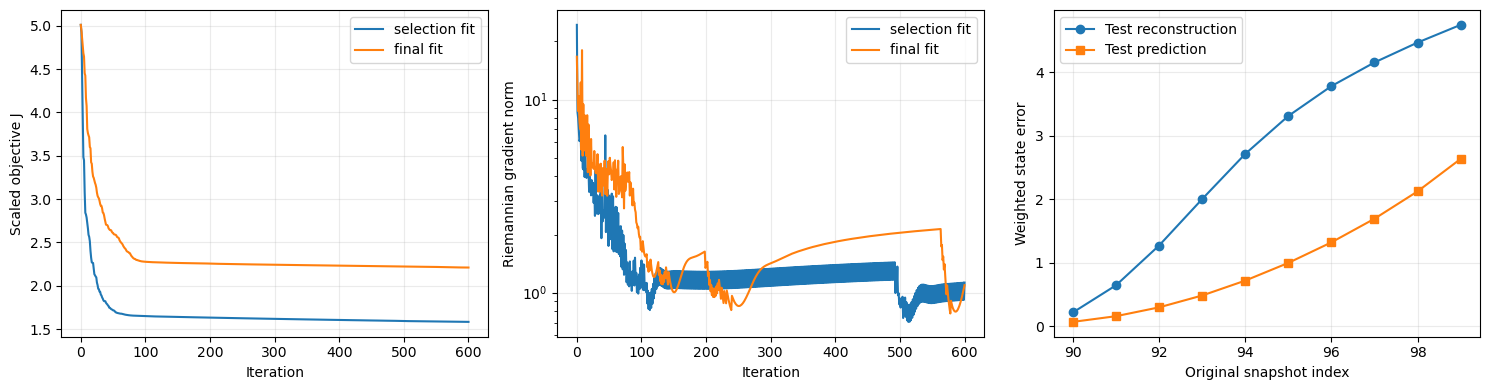

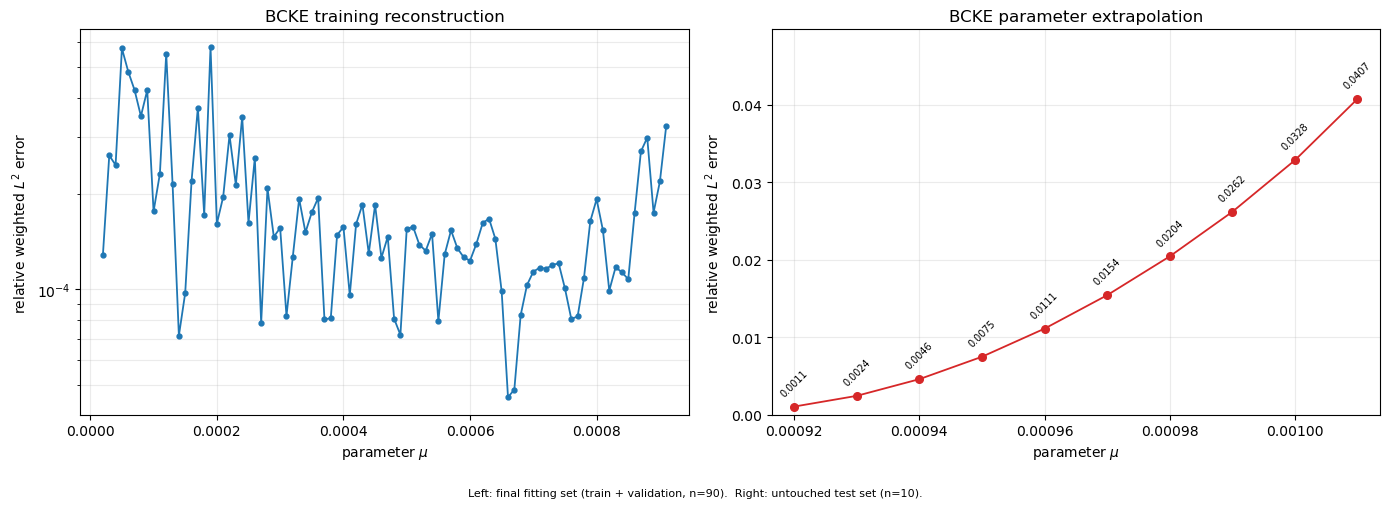

Saved to: D:\代码\bcke_decoder_aware_hybrid_outputs\run_20261021_142929_918m6huf
Final optimizer status: iteration limit (not a stationarity certificate)
Cell 2 uses reconstruction on all fitting snapshots.
Forecast: varying-M DMD linear a + direct local-polynomial nonlinear z.


d:\Anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
d:\Anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
d:\Anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
d:\Anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
d:\Anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
d:\Anaconda3\Lib\site-packages\sklearn\linear_model\_ridge.py:255: UserWarning: Singular matrix in solving dual problem.

dimension      12.000000
fit_samples    90.000000
best_alpha      0.010000
best_gamma     10.000000
cv_mse          2.622455
cv_folds        5.000000
Name: POD+RBF reference, dtype: float64

variant                                     previous PPMD fitting-set reconstruction
linear_dimension                                                                   8
nonlinear_dimension                                                                4
total_dimension                                                                   12
fit_samples                                                                       90
preprocessing_scope                fitting snapshots only; raw PCA residual; no S...
test_states_enter_preprocessing                                                False
residual_neighbors                                                                15
diffusion_k                                                                       22
diffusion_epsilon                                                              100.0
diffusion_alpha                                                                  1.6
lifting_cv_folds                                                 

source_notebook                                           PPMD_reconstruction_only_two_splines.ipynb
source_cell                                                                                        4
variant                                            direct parameter-to-high-dimensional nonlinear...
preprocessing_scope                                                                         fit_only
preprocessing_samples                                                                             90
test_states_enter_preprocessing                                                                False
forecast_steps                                                                                    10
linear_prediction                                         recursive polynomial KRR followed by PCHIP
nonlinear_prediction                                   direct parameter-to-high-dimensional residual
coordinate_interpolation                                                                   

,trend_degree,trend_alpha,residual_alpha,residual_gamma,walk_forward_highdim_relative_l2,walk_forward_highdim_relative_l2_std
0,3,300,0.00001,7.8,1.406562,0.606677


relative_weighted_L2           absolute_weighted_L2          
                                mean       max                 mean       max
method  region                                                               
BCKE    fitting             0.000180  0.000577             0.011582  0.037010
        test                0.016229  0.040737             1.049474  2.635268
POD+RBF fitting             0.016561  0.045565             1.065201  2.910154
        test                0.080250  0.148437             5.188928  9.602325
PPMD    fitting             0.000003  0.000012             0.000164  0.000777
        test                0.017615  0.049604             1.139159  3.208855

method,BCKE,POD+RBF,PPMD
snapshot_index,,,
90,0.001059,0.022618,0.000506
91,0.002444,0.030474,0.001549
92,0.004596,0.040706,0.003399
93,0.007484,0.053433,0.006290
94,0.011111,0.068318,0.010361
95,0.015423,0.084613,0.015609
96,0.020430,0.101542,0.022004
97,0.026176,0.118271,0.029503
98,0.032830,0.134083,0.037328


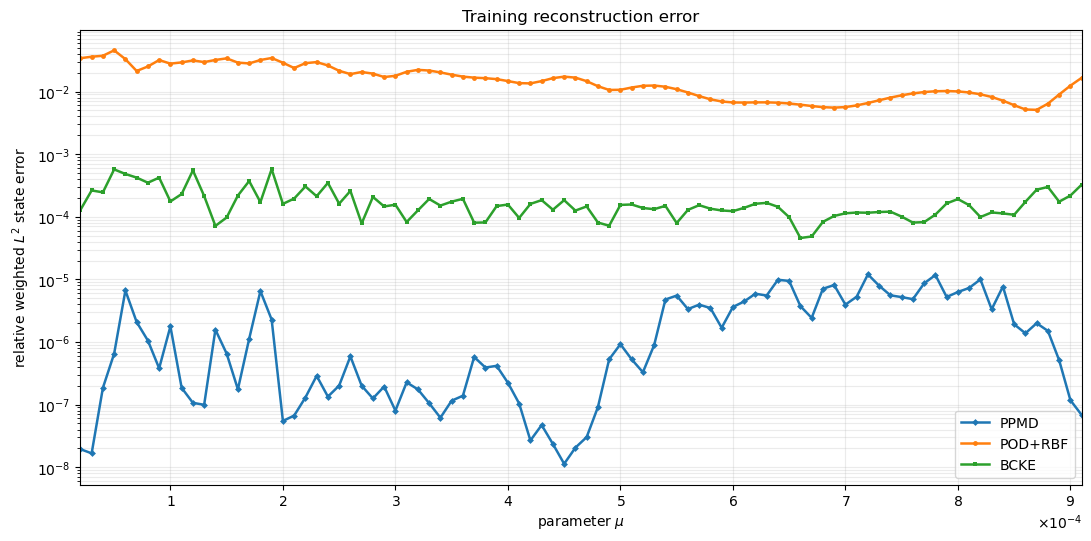

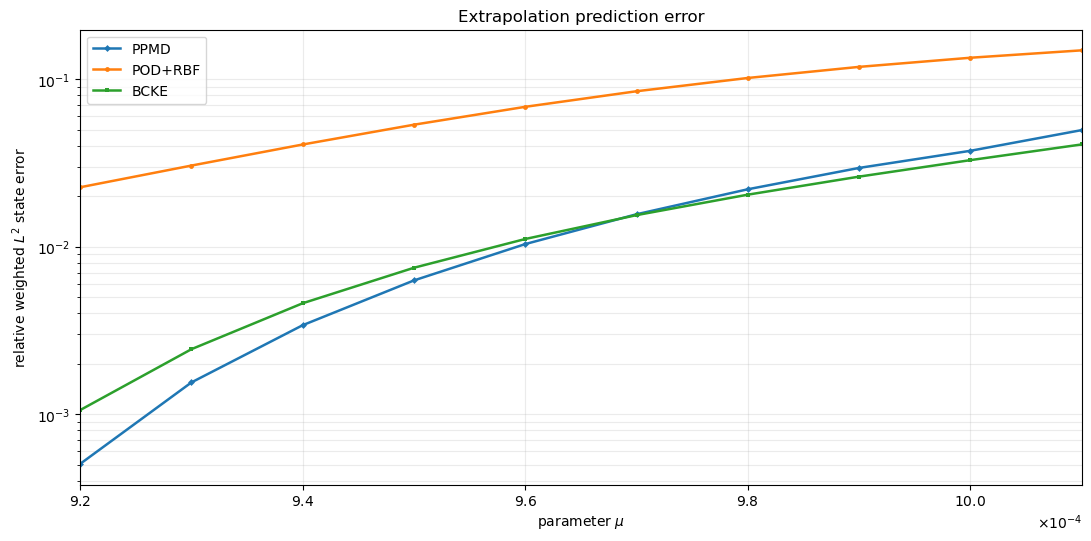

PPMD uses source Cell 4: 8+4 dimensions, linear recursive KRR + PCHIP, direct nonlinear residual prediction.
Comparison figures: training reconstruction and extrapolation prediction, both on log error axes.
Comparison rows and error norms are shared; PPMD preprocessing uses fitting states only.
The final ten test states were viewed in earlier experiments; treat this comparison as exploratory.


In [2]:
# Cell 2: cylinder BCKE experiment with full-sample reconstruction.
# Run Cell 1 before this cell. Results use the full_sample_ prefix.
# Run Cell 1 once; after changing settings, rerun only this cell.
# PyTorch supplies matrix operations and automatic differentiation, NOT a neural network.

# ============================================================================
# A. DATA AND EXPERIMENT PROTOCOL
# ============================================================================
FULL_SAMPLE_DATA_SOURCE = "ppmd"                # "ppmd", "npz", or "synthetic"
FULL_SAMPLE_PPMD_MODULE_DIRECTORY = Path(r"D:\代码")  # folder containing Diffusion.py
FULL_SAMPLE_STATE_COMPONENT = "u"              # same u-only state as the previous notebook; "uv" uses both
FULL_SAMPLE_NPZ_DATA_PATH = Path("bcke_data.npz")  # keys: states (N,Nh), parameters (N,q); optional weights, case_ids
FULL_SAMPLE_WEIGHTS_PATH = None                # .npy diagonal mass weights or full SPD W; None uses identity
FULL_SAMPLE_PARAMETER_FILE = None              # optional .npy array of TRUE input parameters in snapshot order

# Legacy viscosity grid from the old notebook, NOT uniformly spaced Reynolds numbers.
# Replace this with the actual labels used in your simulation, or set PARAMETER_FILE.
# For a genuinely regenerated Re=50,100,...,5000 dataset in that order, use:
# PARAMETER_VALUES = np.arange(50.0, 5000.0 + 50.0, 50.0)
FULL_SAMPLE_PARAMETER_VALUES = np.linspace(0.2e-4, 10.1e-4, 100)
FULL_SAMPLE_CASE_IDS = None                    # optional physical-case labels; all times of a case stay together

FULL_SAMPLE_N_TOTAL = 100                      # complete parameter cases, not spatial degrees of freedom
FULL_SAMPLE_N_REPR_TRAIN = 80
FULL_SAMPLE_N_FINAL_FIT = 90                   # 80 train + 10 validation + 10 untouched test
FULL_SAMPLE_SPLIT_MODE = "ordered"             # file order; "random" gives seeded case-wise interpolation split
FULL_SAMPLE_REFIT_ON_TRAIN_VALIDATION = True

FULL_SAMPLE_QUICK_TEST = False                  # True is a pipeline check, NOT a converged publication run
FULL_SAMPLE_QUICK_ITERATIONS = 30
FULL_SAMPLE_FULL_ITERATIONS = 600
FULL_SAMPLE_TORCH_THREADS = 1                  # small dense sample-space systems often benefit from one thread

# ============================================================================
# B. RECONSTRUCTION: CORE BCKE PARAMETERS (notation follows the LaTeX)
# ============================================================================
full_sample_reconstruction_cfg = BCKEFullSampleConfig(
    p=7, d=5, max_total_dimension=12,
    k_start=10,
    virtual_fractions=(0.2, 0.4, 0.6, 0.8),
    lambda_phi=5e-3,                # coordinate-map ridge, lambda_Phi
    lambda_lambda=8e-5,             # residual-map ridge, lambda_Lambda
    sigma_phi_factor=1,           # times the fixed residual distance quantile
    sigma_lambda_factor=0.5,        # times the initial coordinate distance quantile
    eta_a=1.0, alpha_x=1.0, alpha_z=1.0, beta_f=1.0, beta_b=1.0,
    omega_delta=0.01,
    gamma_diff=0.0,                 # 0: core BCKE; >0: the separate BCKE-D extension
    allow_ablation=True,           # only enable for explicitly labelled zero-weight comparisons
    distance_quantile=0.7,
    affinity_factors=(1.0, 1.0, 1.0, 1.0),  # epsilon_X, epsilon_hatZ, epsilon_V, epsilon_LambdaV
    bandwidth_fallback=0.5,
    eps_scale=1e-12,
    degree_safe=1e-14,
    bandwidth_degree_floor=1e-8,
    bandwidth_growth=1.2,
    max_bandwidth_expansions=200,
    rank_eigenvalue_rtol=1e-12,
    residual_zero_rtol=0.0,
    armijo_c=1e-4, armijo_rho=0.9, initial_step=1.0,
    grad_tol=1e-7, max_backtracks=1000,
    verbose_every=100,
    diff_chunk_size=64,
    seed=42, device="cpu",          # float64 throughout; CUDA requires a matching PyTorch installation
)

# One candidate per quantity is the default for a manageable first run.
# Expand these lists for the paper's finite-grid validation selection.
# This grid OVERRIDES the corresponding six values in reconstruction_cfg.
full_sample_representation_grid = dict(
    p=(full_sample_reconstruction_cfg.p,),
    d=(full_sample_reconstruction_cfg.d,),
    lambda_phi=(full_sample_reconstruction_cfg.lambda_phi,),
    lambda_lambda=(full_sample_reconstruction_cfg.lambda_lambda,),
    sigma_phi_factor=(full_sample_reconstruction_cfg.sigma_phi_factor,),
    sigma_lambda_factor=(full_sample_reconstruction_cfg.sigma_lambda_factor,),
)

# ============================================================================
# C. PREDICTION: BLOCK PARAMETER KRR + DECODER-AWARE RESIDUAL CORRECTION
# ============================================================================
full_sample_prediction_cfg = PredictionConfig(
    # The old shared Gaussian grid below remains an exact, zero-mean baseline.
    # Each pair is (linear a block, nonlinear z block); a is ignored when p=0.
    block_pairs=(
        (KernelBlockConfig("gaussian", 1.0, 1e-4), KernelBlockConfig("gaussian", 0.5, 1e-2)),
        (KernelBlockConfig("gaussian", 2.0, 1e-4), KernelBlockConfig("matern52", 1.0, 1e-4)),
        (KernelBlockConfig("matern52", 1.0, 1e-4), KernelBlockConfig("matern52", 0.3, 1e-4)),
    ),
    # For multi-parameter anisotropy, add fixed pairs with axis_factors=(...).
    # Values are positive multipliers, one per input column; choose before validation.
    correction_nus=(0.1, 0.5),  # B=0 is always included separately
    correction_max_iterations=30 if FULL_SAMPLE_QUICK_TEST else 200,
    correction_grad_tol=1e-7,
    correction_initial_step=1.0,
    correction_armijo_c=1e-4, correction_armijo_rho=0.8,
    correction_max_backtracks=40, correction_verbose_every=0,
    sigma_factors=(0.5, 1.0, ),
    ridges=(1e-8, 1e-6, ),  # one value also works: ridges=1e-4 or (1e-4,)
    distance_quantile=0.6,
    bandwidth_fallback=1.0,
)
# Every candidate uses [A; hat Z]. Separate a/z kernels are allowed.
# Only B is optimized in the correction; the BCKE decoder stays frozen.
# Joint selection uses full-state validation prediction error.

# Forecast settings for the cylinder experiment.
# All definitions are already in Cell 1; no later cell is required.
FULL_SAMPLE_CELL2_DMD_WINDOW = 7
FULL_SAMPLE_CELL2_DMD_RIDGE = 1e-05
FULL_SAMPLE_CELL2_DMD_VARIATION_RIDGE = 0.008
FULL_SAMPLE_CELL2_DMD_MAX_STEPS = 2000
FULL_SAMPLE_CELL2_DECODER_WINDOW = 3
FULL_SAMPLE_CELL2_DECODER_RIDGE = 1e-05
FULL_SAMPLE_CELL2_DECODER_MAX_HORIZON_STEPS = 10
FULL_SAMPLE_CELL2_POLY_CV_ORIGINS = (80,)
FULL_SAMPLE_CELL2_POLY_CV_HORIZON = 10
FULL_SAMPLE_CELL2_POLY_DEGREES = (3,)
FULL_SAMPLE_CELL2_POLY_WINDOWS = (9,)
FULL_SAMPLE_CELL2_POLY_RIDGES = (4e-05,)
FULL_SAMPLE_CELL2_POLY_TERMINAL_WEIGHT = 0.5

FULL_SAMPLE_CHECK_DIRECTIONAL_DERIVATIVES = True
FULL_SAMPLE_DIRECTIONAL_H = 1e-6
FULL_SAMPLE_DIRECTIONAL_TOLERANCE = 5e-4
FULL_SAMPLE_SAVE_OUTPUTS = True
FULL_SAMPLE_OUTPUT_ROOT = Path.cwd()/"bcke_decoder_aware_hybrid_outputs"
FULL_SAMPLE_FIGURE_DPI = 220

# Only the NEW figures use these axis settings; they do not affect fitting.
FULL_SAMPLE_PARAMETER_AXIS = 0  # zero-based input column; a scalar parameter uses 0
FULL_SAMPLE_PARAMETER_AXIS_LABEL = r"parameter $\mu$"  # for Reynolds data: "Reynolds number Re"

# ============================================================================
# D. LOAD DATA AND RUN THE COMPLETE PROTOCOL
# ============================================================================
torch.set_num_threads(FULL_SAMPLE_TORCH_THREADS)
torch.manual_seed(full_sample_reconstruction_cfg.seed)
np.random.seed(full_sample_reconstruction_cfg.seed)
if FULL_SAMPLE_DATA_SOURCE == "ppmd":
    full_sample_fields_all = load_ppmd_states(FULL_SAMPLE_STATE_COMPONENT, FULL_SAMPLE_PPMD_MODULE_DIRECTORY)
    full_sample_mu_full = np.load(FULL_SAMPLE_PARAMETER_FILE, allow_pickle=False) if FULL_SAMPLE_PARAMETER_FILE is not None else FULL_SAMPLE_PARAMETER_VALUES
    full_sample_weight_matrix = None if FULL_SAMPLE_WEIGHTS_PATH is None else np.load(FULL_SAMPLE_WEIGHTS_PATH, allow_pickle=False)
    print("Check: parameter labels must exactly match the order of the loaded snapshots.")
    print("The default labels are the OLD viscosity grid; they do not describe a new uniform-Re dataset.")
elif FULL_SAMPLE_DATA_SOURCE == "npz":
    with np.load(FULL_SAMPLE_NPZ_DATA_PATH, allow_pickle=False) as full_sample_dataset:
        full_sample_fields_all, full_sample_mu_full = full_sample_dataset["states"], full_sample_dataset["parameters"]
        full_sample_weight_matrix = full_sample_dataset["weights"] if "weights" in full_sample_dataset else None
        FULL_SAMPLE_CASE_IDS = full_sample_dataset["case_ids"] if "case_ids" in full_sample_dataset else FULL_SAMPLE_CASE_IDS
    if FULL_SAMPLE_WEIGHTS_PATH is not None:
        full_sample_weight_matrix = np.load(FULL_SAMPLE_WEIGHTS_PATH, allow_pickle=False)
elif FULL_SAMPLE_DATA_SOURCE == "synthetic":
    # Explicit lightweight smoke-test configuration; no CFD data is read.
    full_sample_fields_all, full_sample_mu_full, full_sample_weight_matrix = synthetic_bcke_data(n=24, nh=14, seed=full_sample_reconstruction_cfg.seed)
    FULL_SAMPLE_N_TOTAL, FULL_SAMPLE_N_REPR_TRAIN, FULL_SAMPLE_N_FINAL_FIT = 24, 16, 20
    FULL_SAMPLE_CELL2_POLY_CV_ORIGINS, FULL_SAMPLE_CELL2_POLY_CV_HORIZON = (16,), 4
    full_sample_reconstruction_cfg = replace(full_sample_reconstruction_cfg, p=2, d=2, max_total_dimension=4, k_start=3)
    full_sample_representation_grid = dict(p=(2,), d=(2,), lambda_phi=(full_sample_reconstruction_cfg.lambda_phi,),
        lambda_lambda=(full_sample_reconstruction_cfg.lambda_lambda,),
        sigma_phi_factor=(full_sample_reconstruction_cfg.sigma_phi_factor,),
        sigma_lambda_factor=(full_sample_reconstruction_cfg.sigma_lambda_factor,))
    FULL_SAMPLE_CASE_IDS = None
    print("SYNTHETIC SMOKE TEST: 24 samples, p=2, d=2; not cylinder-flow results.")
else:
    raise ValueError("Unknown DATA_SOURCE.")

full_sample_mu_full = parameter_array(full_sample_mu_full)
FULL_SAMPLE_MAX_ITERATIONS = FULL_SAMPLE_QUICK_ITERATIONS if FULL_SAMPLE_QUICK_TEST else FULL_SAMPLE_FULL_ITERATIONS
print("States:", full_sample_fields_all.shape, "parameters:", full_sample_mu_full.shape)
print("W:", "identity (unweighted Euclidean state norm)" if full_sample_weight_matrix is None else full_sample_weight_matrix.shape)
print("Quick test:", FULL_SAMPLE_QUICK_TEST, "maximum BCKE iterations:", FULL_SAMPLE_MAX_ITERATIONS)
display(pd.Series(asdict(full_sample_reconstruction_cfg), name="BCKE construction rules"))
display(pd.Series(asdict(full_sample_prediction_cfg), name="block KRR and decoder-aware correction"))

full_sample_results = run_bcke_experiment_full_sample(
    full_sample_fields_all, full_sample_mu_full, full_sample_weight_matrix, full_sample_reconstruction_cfg, full_sample_representation_grid, full_sample_prediction_cfg,
    n_train=FULL_SAMPLE_N_REPR_TRAIN, n_final=FULL_SAMPLE_N_FINAL_FIT, n_total=FULL_SAMPLE_N_TOTAL, split_mode=FULL_SAMPLE_SPLIT_MODE,
    refit=FULL_SAMPLE_REFIT_ON_TRAIN_VALIDATION, max_iterations=FULL_SAMPLE_MAX_ITERATIONS,
    audit=FULL_SAMPLE_CHECK_DIRECTIONAL_DERIVATIVES, audit_h=FULL_SAMPLE_DIRECTIONAL_H,
    audit_tolerance=FULL_SAMPLE_DIRECTIONAL_TOLERANCE, case_ids=FULL_SAMPLE_CASE_IDS,
)

# ============================================================================
# E. FINAL FORECAST: VARYING-M DMD a + LOCAL POLYNOMIAL z
# ============================================================================
# full_sample_results holds the kernel prediction baseline.
# full_sample_cell2_results holds the final DMD and local-polynomial forecast.
add_bcke_relative_errors(full_sample_results, full_sample_fields_all)
full_sample_cell2_begin = time.perf_counter()
full_sample_cell2_linear_predictor = LinearCoordinateVaryingM(
    full_sample_results["predictor"], window=FULL_SAMPLE_CELL2_DMD_WINDOW,
    ridge=FULL_SAMPLE_CELL2_DMD_RIDGE, variation_ridge=FULL_SAMPLE_CELL2_DMD_VARIATION_RIDGE,
    max_steps=FULL_SAMPLE_CELL2_DMD_MAX_STEPS,
)
full_sample_cell2_decoder_predictor = LocalLatentDecoderContinuation(
    full_sample_cell2_linear_predictor, window=FULL_SAMPLE_CELL2_DECODER_WINDOW,
    ridge=FULL_SAMPLE_CELL2_DECODER_RIDGE,
    max_horizon_steps=FULL_SAMPLE_CELL2_DECODER_MAX_HORIZON_STEPS,
)
full_sample_cell2_predictor = DirectPolynomialZContinuation(
    full_sample_cell2_decoder_predictor, mode="local",
    origins=FULL_SAMPLE_CELL2_POLY_CV_ORIGINS, horizon=FULL_SAMPLE_CELL2_POLY_CV_HORIZON,
    degrees=FULL_SAMPLE_CELL2_POLY_DEGREES, windows=FULL_SAMPLE_CELL2_POLY_WINDOWS,
    ridges=FULL_SAMPLE_CELL2_POLY_RIDGES, terminal_weight=FULL_SAMPLE_CELL2_POLY_TERMINAL_WEIGHT,
)
full_sample_cell2_setup_seconds = time.perf_counter()-full_sample_cell2_begin
full_sample_cell2_begin = time.perf_counter()
full_sample_cell2_prediction_all = full_sample_cell2_predictor.predict(full_sample_results["parameters"])
full_sample_cell2_prediction_seconds = time.perf_counter()-full_sample_cell2_begin

# Copy mutable reports so the later comparison cells retain their base results.
full_sample_cell2_results = dict(full_sample_results)
full_sample_cell2_results["predictor"] = full_sample_cell2_predictor
full_sample_cell2_results["prediction_all"] = full_sample_cell2_prediction_all
full_sample_cell2_results["per_case_errors"] = full_sample_results["per_case_errors"].copy()
full_sample_cell2_results["per_case_errors"]["prediction_weighted_error"] = np.sqrt(np.maximum(
    weighted_norm_sq_rows(full_sample_fields_all-full_sample_cell2_prediction_all, full_sample_results["problem"].W), 0.0))
add_bcke_relative_errors(full_sample_cell2_results, full_sample_fields_all)
full_sample_cell2_results["metrics"] = full_sample_results["metrics"].copy()
full_sample_cell2_before_refit = ((full_sample_cell2_results["metrics"]["stage"] != "final")
                      & (full_sample_cell2_results["metrics"]["mode"] == "parameter-only prediction"))
full_sample_cell2_results["metrics"].loc[full_sample_cell2_before_refit, "mode"] = "base KRR parameter-only prediction"
for full_sample_cell2_split, full_sample_cell2_ids in (("final fitting set", full_sample_results["final_fit_indices"]),
                              ("test (untouched)", full_sample_results["test_indices"])):
    full_sample_cell2_metric_mask = ((full_sample_cell2_results["metrics"]["stage"] == "final")
                         & (full_sample_cell2_results["metrics"]["split"] == full_sample_cell2_split)
                         & (full_sample_cell2_results["metrics"]["mode"] == "parameter-only prediction"))
    full_sample_cell2_metric = state_error(
        full_sample_fields_all[full_sample_cell2_ids], full_sample_cell2_prediction_all[full_sample_cell2_ids],
        full_sample_results["problem"].mean, full_sample_results["problem"].W)
    for full_sample_cell2_key, full_sample_cell2_value in full_sample_cell2_metric.items():
        full_sample_cell2_results["metrics"].loc[full_sample_cell2_metric_mask, full_sample_cell2_key] = full_sample_cell2_value
    full_sample_cell2_results["metrics"].loc[full_sample_cell2_metric_mask, "mode"] = "DMD a + local polynomial z"
full_sample_cell2_results["protocol"] = dict(full_sample_results["protocol"])
full_sample_cell2_results["protocol"]["final_parameter_predictor"] = full_sample_cell2_predictor.summary()
full_sample_cell2_results["timings"] = dict(full_sample_results["timings"])
full_sample_cell2_results["timings"]["base_prediction_all_seconds"] = full_sample_results["timings"]["prediction_all_seconds"]
full_sample_cell2_results["timings"]["local_polynomial_setup_seconds"] = full_sample_cell2_setup_seconds
full_sample_cell2_results["timings"]["prediction_all_seconds"] = full_sample_cell2_prediction_seconds
full_sample_cell2_results["timings"]["total_seconds"] += full_sample_cell2_setup_seconds+full_sample_cell2_prediction_seconds

display(full_sample_cell2_results["representation_candidates"])
display(full_sample_cell2_results["prediction_candidates"])
display(full_sample_cell2_results["derivative_audit"])
display(full_sample_cell2_results["prediction_derivative_audit"])
display(pd.Series(full_sample_cell2_predictor.summary(), name="final DMD + local polynomial predictor"))
display(full_sample_cell2_predictor.cv_results)
display(pd.Series(full_sample_cell2_results["problem"].summary(), name="final BCKE fit"))
display(pd.DataFrame(full_sample_cell2_results["problem"].bandwidth_report).T)
display(full_sample_cell2_results["metrics"])
display(full_sample_cell2_results["per_case_errors"].query("original_split == 'test'"))
display(pd.Series(full_sample_cell2_results["timings"], name="wall-clock times (seconds)"))

full_sample_output_directory = None
if FULL_SAMPLE_SAVE_OUTPUTS:
    # Reuse the original report writer for the representation and base map,
    # then add the complete active DMD/local-polynomial model components.
    full_sample_cell2_export_results = dict(full_sample_cell2_results)
    full_sample_cell2_export_results["predictor"] = full_sample_results["predictor"]
    full_sample_output_directory = save_bcke_results(full_sample_cell2_export_results, FULL_SAMPLE_OUTPUT_ROOT)
    (full_sample_output_directory/"parameter_model.npz").rename(full_sample_output_directory/"base_parameter_model.npz")
    with np.load(full_sample_output_directory/"base_parameter_model.npz", allow_pickle=False) as full_sample_cell2_archive:
        full_sample_cell2_model_arrays = {full_sample_key: full_sample_cell2_archive[full_sample_key].copy() for full_sample_key in full_sample_cell2_archive.files}
    full_sample_cell2_model_arrays.update(
        model_format=np.array("bcke_varying_m_local_poly_v1"),
        linear_G0=full_sample_cell2_linear_predictor.G0,
        linear_G1=full_sample_cell2_linear_predictor.G1,
        linear_c0=full_sample_cell2_linear_predictor.c0,
        linear_a_reference=full_sample_cell2_linear_predictor.a_reference,
        linear_anchor_shift=full_sample_cell2_linear_predictor.anchor_shift,
        linear_n_pairs=full_sample_cell2_linear_predictor.n_pairs,
        linear_max_steps=full_sample_cell2_linear_predictor.max_steps,
        mu_min=full_sample_cell2_linear_predictor.mu_min,
        mu_boundary=full_sample_cell2_linear_predictor.mu_boundary,
        grid_step=full_sample_cell2_linear_predictor.grid_step,
        decoder_J=full_sample_cell2_decoder_predictor.J,
        decoder_z_boundary=full_sample_cell2_decoder_predictor.z_boundary,
        decoder_residual_boundary=full_sample_cell2_decoder_predictor.residual_boundary,
        decoder_max_horizon_steps=full_sample_cell2_decoder_predictor.max_horizon_steps,
        polynomial_coefficients=full_sample_cell2_predictor.z_model.coefficients,
        polynomial_degree=full_sample_cell2_predictor.z_model.degree,
        polynomial_mu_scale=full_sample_cell2_predictor.z_model.mu_scale,
        polynomial_anchor_shift=full_sample_cell2_predictor.anchor_shift,
    )
    np.savez_compressed(full_sample_output_directory/"parameter_model.npz", **full_sample_cell2_model_arrays)
    full_sample_cell2_predictor.cv_results.to_csv(full_sample_output_directory/"local_polynomial_cv.csv", index=False)
    full_sample_cell2_metadata_path = full_sample_output_directory/"settings_and_summary.json"
    full_sample_cell2_metadata = json.loads(full_sample_cell2_metadata_path.read_text(encoding="utf-8"))
    full_sample_cell2_metadata["base_predictor"] = full_sample_cell2_metadata["selected_predictor"]
    full_sample_cell2_metadata["selected_predictor"] = full_sample_cell2_predictor.summary()
    full_sample_cell2_metadata["linear_extrapolator"] = full_sample_cell2_linear_predictor.summary()
    full_sample_cell2_metadata["nonlinear_decoder"] = full_sample_cell2_decoder_predictor.summary()
    full_sample_cell2_metadata["model_format"] = "bcke_varying_m_local_poly_v1"
    full_sample_cell2_metadata["note"] = (
        "Cell 2 final prediction uses varying-M DMD a and direct local-polynomial z. "
        "The fitted interval retains the base map. The original representation and "
        "base KRR selection tables are retained. Local-polynomial CV freezes the "
        "representation and uses only known fitting coordinates. "
        "The test block has previously been viewed; comparisons are exploratory.")
    full_sample_cell2_metadata_path.write_text(json.dumps(full_sample_cell2_metadata, indent=2, ensure_ascii=False),
                                  encoding="utf-8")

# Plot fitting diagnostics, reconstruction errors, and prediction errors.
plot_bcke_results(full_sample_cell2_results, full_sample_output_directory, FULL_SAMPLE_FIGURE_DPI)
plot_bcke_parameter_errors(
    full_sample_cell2_results, full_sample_output_directory, FULL_SAMPLE_FIGURE_DPI,
    parameter_axis=FULL_SAMPLE_PARAMETER_AXIS, parameter_label=FULL_SAMPLE_PARAMETER_AXIS_LABEL,
)
if full_sample_output_directory is not None:
    print("Saved to:", full_sample_output_directory.resolve())
print("Final optimizer status:", full_sample_cell2_results["problem"].status)
print("Cell 2 uses reconstruction on all fitting snapshots.")
print("Forecast: varying-M DMD linear a + direct local-polynomial nonlinear z.")

# Optional parameter-only use after fitting (run only Cells 1 and 2):
# mu_query = np.array([[your_parameter_value]])
# u_query = full_sample_cell2_predictor.predict(mu_query)  # shape (n_queries, n_dofs)
# full_sample_cell2_results["predictor"] is the same active predictor.
# parameter_model.npz stores its complete components in the new format.
# The legacy predict_saved_bcke loader supports only base_parameter_model.npz.


# ============================================================================
# F. SAME-DATA COMPARISON: BCKE, POD+RBF, AND PPMD FROM SOURCE CELL 4
# ============================================================================
# PPMD follows the executed source Cell 4: fit PCA and diffusion on the
# fitting prefix; forecast linear coordinates recursively; predict future
# high-dimensional residuals directly from the parameter.
FULL_SAMPLE_COMPARISON_POD_ALPHAS = (1e-8, 1e-6, 1e-4, 1e-2, 1.0)
FULL_SAMPLE_COMPARISON_POD_GAMMAS = (1e-2, 1e-1, 1.0, 10.0, 100.0)
FULL_SAMPLE_COMPARISON_POD_CV_FOLDS = 5
# PPMD reconstruction and parameter prediction both use source Cell 4
# (8 linear coordinates, 4 diffusion coordinates); each fit uses fitting states only.
FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_LINEAR_DIM = 2 if FULL_SAMPLE_DATA_SOURCE == "synthetic" else 8
FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_NONLINEAR_DIM = 2 if FULL_SAMPLE_DATA_SOURCE == "synthetic" else 4
FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_CONFIG = dict(
    residual_neighbors=15,
    diffusion_k=22, diffusion_epsilon=100.0, diffusion_alpha=1.6,
    lifting_grid={
        "poly_features__degree": [2],
        "krr__alpha": [1e-4],
        "krr__degree": [3],
        "krr__coef0": [10],
    },
    lifting_cv_folds=10, n_jobs=-1,
)
if FULL_SAMPLE_DATA_SOURCE == "synthetic":
    FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_CONFIG = dict(
        FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_CONFIG, lifting_cv_folds=5, n_jobs=1)

# Source PPMD Cell 4: 8 linear coordinates and 4 diffusion coordinates.
# The explicit synthetic smoke test retains its smaller 2+2 dimensions.
FULL_SAMPLE_COMPARISON_PPMD_LINEAR_DIM = 2 if FULL_SAMPLE_DATA_SOURCE == "synthetic" else 8
FULL_SAMPLE_COMPARISON_PPMD_NONLINEAR_DIM = 2 if FULL_SAMPLE_DATA_SOURCE == "synthetic" else 4
FULL_SAMPLE_COMPARISON_PPMD_CONFIG = dict(
    residual_neighbors=15,
    diffusion_k=22, diffusion_epsilon=100.0, diffusion_alpha=1.6,
    lifting_grid={
        "poly_features__degree": [2],
        "krr__alpha": [1e-4],
        "krr__degree": [3],
        "krr__coef0": [10],
    },
    lifting_cv_folds=10,
    # (last forecast step, polynomial degree, alpha, coef0); linear branch only.
    linear_schedule=(
        (3, 4, 4e-1, 55), (5, 3, 1e-2, 3), (7, 3, 8e-2, 10),
        (8, 3, 8e-2, 32000), (9, 4, 7, 22), (10, 3, 1e-6, 10),
    ),
    nonlinear_grid={
        "trend_degree": [3], "trend_alpha": [300],
        "residual_alpha": [1e-5], "residual_gamma": [7.8],
    },
    nonlinear_cv_origins=(50, 60, 70, 75, 80),
    nonlinear_cv_horizon=10,
    n_jobs=-1,
)
FULL_SAMPLE_COMPARISON_PPMD_QUERY_PARAMETERS = (
    2.55e-4, 5.05e-4, 7.55e-4, 9.25e-4,
    9.45e-4, 9.65e-4, 9.85e-4, 10.05e-4,
)
if FULL_SAMPLE_DATA_SOURCE == "synthetic":
    # This 24-case check uses fewer neighbors; physical-data defaults above
    # are the exact values from the supplied 100-case script.
    FULL_SAMPLE_COMPARISON_PPMD_CONFIG = dict(FULL_SAMPLE_COMPARISON_PPMD_CONFIG,
        diffusion_k=min(22, FULL_SAMPLE_N_FINAL_FIT-1), n_jobs=1,
        nonlinear_cv_origins=(10, 12, 16), nonlinear_cv_horizon=4)
    FULL_SAMPLE_COMPARISON_PPMD_QUERY_PARAMETERS = ()

full_sample_comparison_mu, full_sample_comparison_fit, full_sample_comparison_test = _validate_ordered_scalar_comparison(
    full_sample_results["parameters"], full_sample_results["final_fit_indices"], full_sample_results["test_indices"])
full_sample_comparison_total_dimension = full_sample_cell2_results["problem"].p+full_sample_cell2_results["problem"].d
if FULL_SAMPLE_COMPARISON_PPMD_LINEAR_DIM+FULL_SAMPLE_COMPARISON_PPMD_NONLINEAR_DIM != full_sample_comparison_total_dimension:
    raise ValueError("Set the two PPMD dimensions to the BCKE total dimension for a fair comparison.")
if FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_LINEAR_DIM+FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_NONLINEAR_DIM != full_sample_comparison_total_dimension:
    raise ValueError("PPMD reconstruction dimensions must also match the BCKE total dimension.")

full_sample_pod_rbf_prediction_all, full_sample_pod_rbf_reference_info = fit_pod_rbf_reference(
    full_sample_fields_all, full_sample_comparison_mu, full_sample_comparison_fit, full_sample_comparison_total_dimension,
    full_sample_cell2_results["problem"].W, alphas=FULL_SAMPLE_COMPARISON_POD_ALPHAS,
    gammas=FULL_SAMPLE_COMPARISON_POD_GAMMAS, cv_folds=FULL_SAMPLE_COMPARISON_POD_CV_FOLDS,
    seed=full_sample_reconstruction_cfg.seed,
)
full_sample_pod_rbf_reconstruction_fit = full_sample_pod_rbf_reference_info.pop("fitting_reconstruction")
full_sample_ppmd_prediction_all, full_sample_ppmd_reference_info, full_sample_ppmd_query_model = fit_ppmd_reference(
    full_sample_fields_all, full_sample_comparison_mu, full_sample_comparison_fit,
    linear_dimension=FULL_SAMPLE_COMPARISON_PPMD_LINEAR_DIM,
    nonlinear_dimension=FULL_SAMPLE_COMPARISON_PPMD_NONLINEAR_DIM,
    seed=full_sample_reconstruction_cfg.seed, return_model=True,
    **FULL_SAMPLE_COMPARISON_PPMD_CONFIG,
)
# Queries use linear PCHIP; fitting-interval residuals use diffusion lifting,
# and future residuals use the direct parameter model from source Cell 4.
if FULL_SAMPLE_COMPARISON_PPMD_QUERY_PARAMETERS:
    full_sample_ppmd_query_parameters = parameter_array(FULL_SAMPLE_COMPARISON_PPMD_QUERY_PARAMETERS)
    full_sample_ppmd_query_predictions = predict_ppmd_cell4(
        full_sample_ppmd_query_parameters, full_sample_ppmd_query_model)
else:
    full_sample_ppmd_query_parameters = np.empty((0, 1), dtype=np.float64)
    full_sample_ppmd_query_predictions = np.empty((0, full_sample_fields_all.shape[1]), dtype=np.float64)
full_sample_ppmd_reconstruction_fit, full_sample_ppmd_reconstruction_info = fit_ppmd_previous_reconstruction_reference(
    full_sample_fields_all, full_sample_comparison_mu, full_sample_comparison_fit,
    linear_dimension=FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_LINEAR_DIM,
    nonlinear_dimension=FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_NONLINEAR_DIM,
    seed=full_sample_reconstruction_cfg.seed,
    **FULL_SAMPLE_COMPARISON_PPMD_RECONSTRUCTION_CONFIG,
)
full_sample_ppmd_reference_info["reconstruction_reference"] = full_sample_ppmd_reconstruction_info
full_sample_ppmd_reference_info["separate_reconstruction_and_prediction_settings"] = True
full_sample_comparison_predictions = {
    "BCKE": full_sample_cell2_prediction_all,
    "POD+RBF": full_sample_pod_rbf_prediction_all,
    "PPMD": full_sample_ppmd_prediction_all,
}
# Retain the two error regions: known-state reconstruction on the
# fitting prefix and parameter-only prediction on the final test block.
full_sample_comparison_estimates = {full_sample_name: full_sample_estimate.copy()
                        for full_sample_name, full_sample_estimate in full_sample_comparison_predictions.items()}
full_sample_comparison_estimates["BCKE"][full_sample_comparison_fit] = full_sample_cell2_results["reconstruction_all"][full_sample_comparison_fit]
full_sample_comparison_estimates["POD+RBF"][full_sample_comparison_fit] = full_sample_pod_rbf_reconstruction_fit
# Use the previous PPMD reconstruction only on fitting rows.
# Test rows retain the source-Cell-4 parameter prediction.
full_sample_comparison_estimates["PPMD"][full_sample_comparison_fit] = full_sample_ppmd_reconstruction_fit
full_sample_comparison_errors = build_bcke_comparison_table(
    full_sample_fields_all, full_sample_comparison_mu, full_sample_comparison_estimates,
    full_sample_comparison_fit, full_sample_comparison_test, full_sample_cell2_results["problem"].W,
)
full_sample_comparison_errors["evaluation"] = np.where(
    full_sample_comparison_errors.region == "fitting", "training reconstruction", "extrapolation prediction")
full_sample_comparison_test_errors = full_sample_comparison_errors.loc[
    full_sample_comparison_errors.region == "test"
].pivot(index="snapshot_index", columns="method", values="relative_weighted_L2")
full_sample_comparison_summary = full_sample_comparison_errors.groupby(["method", "region"])[
    ["relative_weighted_L2", "absolute_weighted_L2"]
].agg(["mean", "max"])

display(pd.Series(full_sample_pod_rbf_reference_info, name="POD+RBF reference"))
display(pd.Series(full_sample_ppmd_reconstruction_info, name="PPMD previous reconstruction reference"))
display(pd.Series({full_sample_key: full_sample_value for full_sample_key, full_sample_value in full_sample_ppmd_reference_info.items()
                   if full_sample_key != "nonlinear_cv_results"}, name="PPMD source Cell 4 prediction"))
display(pd.DataFrame(full_sample_ppmd_reference_info["nonlinear_cv_results"]))
display(full_sample_comparison_summary)
display(full_sample_comparison_test_errors)
plot_bcke_method_comparison(
    full_sample_comparison_errors, full_sample_comparison_fit, full_sample_comparison_test,
    parameter_label=FULL_SAMPLE_PARAMETER_AXIS_LABEL, output_directory=full_sample_output_directory,
    dpi=FULL_SAMPLE_FIGURE_DPI,
)
if full_sample_output_directory is not None:
    full_sample_comparison_errors.to_csv(full_sample_output_directory/"method_comparison_per_case.csv", index=False)
    full_sample_comparison_summary.to_csv(full_sample_output_directory/"method_comparison_summary.csv")
    pd.DataFrame(full_sample_ppmd_reference_info["nonlinear_cv_results"]).to_csv(
        full_sample_output_directory/"ppmd_direct_highdim_cv.csv", index=False)
    with (full_sample_output_directory/"comparison_reference_settings.json").open("w", encoding="utf-8") as full_sample_comparison_file:
        json.dump(dict(pod_rbf=full_sample_pod_rbf_reference_info, ppmd=full_sample_ppmd_reference_info),
                  full_sample_comparison_file, indent=2, ensure_ascii=False)
    np.savez_compressed(
        full_sample_output_directory/"method_comparison_predictions.npz",
        bcke=full_sample_cell2_prediction_all, pod_rbf=full_sample_pod_rbf_prediction_all,
        ppmd=full_sample_ppmd_prediction_all, parameters=full_sample_comparison_mu,
        ppmd_reconstruction_fit=full_sample_ppmd_reconstruction_fit,
        ppmd_query_parameters=full_sample_ppmd_query_parameters,
        ppmd_query_predictions=full_sample_ppmd_query_predictions,
        bcke_comparison_estimates=full_sample_comparison_estimates["BCKE"],
        pod_rbf_comparison_estimates=full_sample_comparison_estimates["POD+RBF"],
        ppmd_comparison_estimates=full_sample_comparison_estimates["PPMD"],
        final_fit_indices=full_sample_comparison_fit, test_indices=full_sample_comparison_test,
    )
print("PPMD uses source Cell 4: 8+4 dimensions, linear recursive KRR + PCHIP, direct nonlinear residual prediction.")
print("Comparison figures: training reconstruction and extrapolation prediction, both on log error axes.")
print("Comparison rows and error norms are shared; PPMD preprocessing uses fitting states only.")
print("The final ten test states were viewed in earlier experiments; treat this comparison as exploratory.")


In [ ]:
# Cell 3: cylinder fields and VTUs at the paper comparison parameters.
# Run Cells 1 and 2. Rerun this cell to change the field queries.
import meshio

if "full_sample_cell2_results" not in globals():
    raise RuntimeError("Run the cylinder experiment in Cell 2 first.")

CYLINDER_FLOW_DATA_ROOT = Path(r"D:\parametric PMD\Flow around a cylinder")
CYLINDER_FLOW_VTU_FILENAME = "circle-2d-drag_150.vtu"
CYLINDER_FLOW_COMPONENT = FULL_SAMPLE_STATE_COMPONENT
CYLINDER_FLOW_RECONSTRUCTION_INDICES = (38,)  # mu=4.0e-4
CYLINDER_FLOW_QUERY_PARAMETERS = (2.55e-4, 9.65e-4)
CYLINDER_FLOW_EXPORT_ALL_TEST = False
CYLINDER_FLOW_SAVE_VTU = True
CYLINDER_FLOW_FIGURE_DPI = FULL_SAMPLE_FIGURE_DPI
CYLINDER_FLOW_OUTPUT_ROOT = Path.cwd()/"bcke_cylinder_flow_vtu_outputs"

# Evaluate the already fitted parameter predictor before reading query references.
cylinder_flow_query_mu = parameter_array(np.asarray(CYLINDER_FLOW_QUERY_PARAMETERS, dtype=np.float64)[:, None])
cylinder_flow_query_predictions = full_sample_cell2_results["predictor"].predict(cylinder_flow_query_mu)
cylinder_flow_query_paths = [
    resolve_bcke_case_vtu(
        CYLINDER_FLOW_DATA_ROOT, cylinder_flow_parameter, CYLINDER_FLOW_VTU_FILENAME,
        folder_prefix="flow", parameter_scale=1e-4)
    for cylinder_flow_parameter in cylinder_flow_query_mu[:, 0]
]
cylinder_flow_query_reference = np.vstack([
    _bcke_vtu_state(meshio.read(cylinder_flow_path), CYLINDER_FLOW_COMPONENT)
    for cylinder_flow_path in cylinder_flow_query_paths
])
if (cylinder_flow_query_predictions.shape != cylinder_flow_query_reference.shape
        or not np.isfinite(cylinder_flow_query_predictions).all()):
    raise ValueError("Query predictions must match the reference VTU state size and be finite.")

# These appended rows are only a display view. The original fitting data,
# representation, predictor, and result dictionary are retained as supplied.
cylinder_flow_original_states = np.asarray(full_sample_fields_all, dtype=np.float64)
cylinder_flow_original_mu = parameter_array(full_sample_cell2_results["parameters"])
if not np.allclose(
        cylinder_flow_original_mu[np.asarray(CYLINDER_FLOW_RECONSTRUCTION_INDICES), 0],
        4.0e-4, rtol=1e-12, atol=1e-15):
    raise ValueError("The reconstruction row must represent the paper viscosity 4.0e-4.")
cylinder_flow_query_indices = np.arange(
    len(cylinder_flow_original_states),
    len(cylinder_flow_original_states)+len(cylinder_flow_query_mu), dtype=int)
cylinder_flow_display_states = np.vstack((cylinder_flow_original_states, cylinder_flow_query_reference))
cylinder_flow_display_results = dict(full_sample_cell2_results)
cylinder_flow_display_results["parameters"] = np.vstack((cylinder_flow_original_mu, cylinder_flow_query_mu))
cylinder_flow_display_results["test_indices"] = cylinder_flow_query_indices
cylinder_flow_display_results["prediction_all"] = np.vstack((
    full_sample_cell2_results["prediction_all"], cylinder_flow_query_predictions))
cylinder_flow_display_results["reconstruction_all"] = np.vstack((
    full_sample_cell2_results["reconstruction_all"], np.full_like(cylinder_flow_query_reference, np.nan)))

# Use a separate output directory for this paper selection.
cylinder_flow_export = plot_and_export_bcke_case_flow(
    cylinder_flow_display_results, cylinder_flow_display_states,
    data_root=CYLINDER_FLOW_DATA_ROOT, filename=CYLINDER_FLOW_VTU_FILENAME,
    folder_prefix="flow", parameter_scale=1e-4, component=CYLINDER_FLOW_COMPONENT,
    reconstruction_indices=CYLINDER_FLOW_RECONSTRUCTION_INDICES,
    selected_test_indices=cylinder_flow_query_indices, query_parameters=(),
    export_all_test=CYLINDER_FLOW_EXPORT_ALL_TEST, save_vtu=CYLINDER_FLOW_SAVE_VTU,
    output_directory=Path(full_sample_output_directory)/"paper_parameters",
    output_root=CYLINDER_FLOW_OUTPUT_ROOT, dpi=CYLINDER_FLOW_FIGURE_DPI,
)

# Mark independent query references explicitly in the VTU manifest.
cylinder_flow_manifest = cylinder_flow_export["vtu_manifest"].copy()
if len(cylinder_flow_manifest):
    cylinder_flow_manifest["query_index"] = -1
    cylinder_flow_manifest["parameter_region"] = "fitting reconstruction"
    cylinder_flow_fitting_boundary = float(np.max(
        cylinder_flow_original_mu[full_sample_cell2_results["final_fit_indices"], 0]))
    for cylinder_flow_query_number, cylinder_flow_display_index in enumerate(cylinder_flow_query_indices):
        cylinder_flow_mask = ((cylinder_flow_manifest["mode"] == "prediction")
                             & (cylinder_flow_manifest["snapshot_index"] == cylinder_flow_display_index))
        cylinder_flow_manifest.loc[cylinder_flow_mask, "snapshot_index"] = -1
        cylinder_flow_manifest.loc[cylinder_flow_mask, "query_index"] = cylinder_flow_query_number
        cylinder_flow_manifest.loc[cylinder_flow_mask, "parameter_region"] = (
            "interpolation" if cylinder_flow_query_mu[cylinder_flow_query_number, 0] <= cylinder_flow_fitting_boundary
            else "extrapolation")
    cylinder_flow_manifest.to_csv(cylinder_flow_export["output_directory"]/"vtu_manifest.csv", index=False)
    cylinder_flow_export["vtu_manifest"] = cylinder_flow_manifest
    display(cylinder_flow_manifest[["mode", "parameter", "parameter_region", "relative_L2",
                                   "field_vtu", "error_vtu"]])
cylinder_flow_export["prediction_query_parameters"] = cylinder_flow_query_mu[:, 0].copy()
cylinder_flow_export["query_reference_vtus"] = tuple(map(str, cylinder_flow_query_paths))

# All-method fields use the same comparison fits and exact paper queries.
if "full_sample_comparison_estimates" not in globals():
    raise RuntimeError("Run the complete cylinder experiment, including its comparison section, first.")
cylinder_flow_pod_rbf_queries = query_pod_rbf_flow(
    full_sample_fields_all, full_sample_comparison_mu, full_sample_comparison_fit,
    full_sample_comparison_total_dimension, full_sample_cell2_results["problem"].W,
    full_sample_pod_rbf_reference_info, cylinder_flow_query_mu,
    grid_prediction=full_sample_pod_rbf_prediction_all,
)
cylinder_flow_ppmd_queries = predict_ppmd_cell4(
    cylinder_flow_query_mu, full_sample_ppmd_query_model)
cylinder_flow_rec_index = int(CYLINDER_FLOW_RECONSTRUCTION_INDICES[0])
cylinder_flow_rec_parameter = float(cylinder_flow_original_mu[cylinder_flow_rec_index, 0])
cylinder_flow_reconstruction_vtu = resolve_bcke_case_vtu(
    CYLINDER_FLOW_DATA_ROOT, cylinder_flow_rec_parameter, CYLINDER_FLOW_VTU_FILENAME,
    folder_prefix="flow", parameter_scale=1e-4)
cylinder_flow_method_comparison = plot_and_export_flow_method_comparison(
    full_sample_fields_all[cylinder_flow_rec_index],
    {name: estimates[cylinder_flow_rec_index] for name, estimates in full_sample_comparison_estimates.items()},
    cylinder_flow_query_reference,
    {"BCKE": cylinder_flow_query_predictions, "POD+RBF": cylinder_flow_pod_rbf_queries, "PPMD": cylinder_flow_ppmd_queries},
    reconstruction_parameter=cylinder_flow_rec_parameter, query_parameters=cylinder_flow_query_mu,
    reconstruction_vtu=cylinder_flow_reconstruction_vtu, query_vtus=cylinder_flow_query_paths,
    component=CYLINDER_FLOW_COMPONENT, case_name="cylinder",
    dimension=full_sample_comparison_total_dimension,
    output_directory=cylinder_flow_export["output_directory"],
    dpi=CYLINDER_FLOW_FIGURE_DPI, save_vtu=CYLINDER_FLOW_SAVE_VTU,
)


In [ ]:
# Cell 4: independent cylinder prediction debugging with trend + kernel z.
# Run Cells 1 and 2 first. Change settings here and rerun only this cell.
# The fitting representation, linear forecast, and local lifting are reused.

CYLINDER_TREND_KERNEL_CV_ORIGINS = (50,)
CYLINDER_TREND_KERNEL_CV_HORIZON = 20
CYLINDER_TREND_KERNEL_DEGREES = (1,)
CYLINDER_TREND_KERNEL_WINDOWS = (None,)  # None uses a global polynomial trend
CYLINDER_TREND_KERNEL_LENGTHS = (0.17,)  # normalized fitting interval
CYLINDER_TREND_KERNEL_RIDGES = (1e-7,)
CYLINDER_TREND_KERNEL_TREND_RIDGE = 1e-10
CYLINDER_TREND_KERNEL_TERMINAL_WEIGHT = 0.0  # mean CV error; no extra terminal weight
CYLINDER_TREND_KERNEL_SAVE_OUTPUTS = True
CYLINDER_TREND_KERNEL_OUTPUT_ROOT = Path.cwd()/"bcke_cylinder_trend_kernel_z_outputs"
CYLINDER_TREND_KERNEL_FIGURE_DPI = 220

if "run_bcke_trend_kernel_prediction_debug" not in globals():
    raise RuntimeError("Run Cell 1 with the prediction debugging functions first.")
if "full_sample_cell2_results" not in globals() or "full_sample_cell2_decoder_predictor" not in globals():
    raise RuntimeError("Run the cylinder experiment in Cell 2 first.")

cylinder_trend_kernel_debug = run_bcke_trend_kernel_prediction_debug(
    full_sample_cell2_results, full_sample_fields_all,
    full_sample_cell2_decoder_predictor, case_name="Cylinder",
    origins=CYLINDER_TREND_KERNEL_CV_ORIGINS,
    horizon=CYLINDER_TREND_KERNEL_CV_HORIZON,
    degrees=CYLINDER_TREND_KERNEL_DEGREES,
    trend_windows=CYLINDER_TREND_KERNEL_WINDOWS,
    length_scales=CYLINDER_TREND_KERNEL_LENGTHS,
    kernel_ridges=CYLINDER_TREND_KERNEL_RIDGES,
    trend_ridge=CYLINDER_TREND_KERNEL_TREND_RIDGE,
    terminal_weight=CYLINDER_TREND_KERNEL_TERMINAL_WEIGHT,
    save_outputs=CYLINDER_TREND_KERNEL_SAVE_OUTPUTS,
    output_root=CYLINDER_TREND_KERNEL_OUTPUT_ROOT,
    dpi=CYLINDER_TREND_KERNEL_FIGURE_DPI,
)
cylinder_trend_kernel_predictor = cylinder_trend_kernel_debug["predictor"]

# Query only the parameter after fitting:
# u_query = cylinder_trend_kernel_predictor.predict([[your_parameter_value]])
# z_query = cylinder_trend_kernel_predictor.nonlinear_coordinates([[your_parameter_value]])


In [ ]:
# Cell 5: backward-facing step BCKE experiment with full-sample reconstruction.
# Run Cell 1 before this cell. Results use the step_full_sample_ prefix.
# Run Cell 1 once; after changing settings, rerun only this cell.
# PyTorch supplies matrix operations and automatic differentiation, NOT a neural network.

# ============================================================================
# A. DATA AND EXPERIMENT PROTOCOL
# ============================================================================
STEP_FULL_SAMPLE_DATA_SOURCE = "ppmd"                # "ppmd", "npz", or "synthetic"
STEP_FULL_SAMPLE_PPMD_MODULE_DIRECTORY = Path(r"D:\代码")  # folder containing Diffusion.py
STEP_FULL_SAMPLE_DATA_ROOT = Path(r"D:\parametric PMD\backward facing step")
STEP_FULL_SAMPLE_VTU_FILENAME = "backward_facing_step_2d_25.vtu"
STEP_FULL_SAMPLE_STATE_COMPONENT = "u"              # same u-only state as the previous notebook; "uv" uses both
STEP_FULL_SAMPLE_NPZ_DATA_PATH = Path("bcke_step_data.npz")  # keys: states (N,Nh), parameters (N,q); optional weights, case_ids
STEP_FULL_SAMPLE_WEIGHTS_PATH = None                # .npy diagonal mass weights or full SPD W; None uses identity
STEP_FULL_SAMPLE_PARAMETER_FILE = None              # optional .npy array of TRUE input parameters in snapshot order

# Step viscosity grid matches step2e-5, step4e-5, ..., step200e-5.
# Replace this with the actual labels used in your simulation, or set PARAMETER_FILE.
# For a genuinely regenerated Re=50,100,...,5000 dataset in that order, use:
# PARAMETER_VALUES = np.arange(50.0, 5000.0 + 50.0, 50.0)
STEP_FULL_SAMPLE_PARAMETER_VALUES = np.arange(1, 101, dtype=np.float64)*2e-5
STEP_FULL_SAMPLE_CASE_IDS = None                    # optional physical-case labels; all times of a case stay together

STEP_FULL_SAMPLE_N_TOTAL = 100                      # complete parameter cases, not spatial degrees of freedom
STEP_FULL_SAMPLE_N_REPR_TRAIN = 80
STEP_FULL_SAMPLE_N_FINAL_FIT = 90                   # 80 train + 10 validation + 10 untouched test
STEP_FULL_SAMPLE_SPLIT_MODE = "ordered"             # file order; "random" gives seeded case-wise interpolation split
STEP_FULL_SAMPLE_REFIT_ON_TRAIN_VALIDATION = True

STEP_FULL_SAMPLE_QUICK_TEST = False                  # True is a pipeline check, NOT a converged publication run
STEP_FULL_SAMPLE_QUICK_ITERATIONS = 30
STEP_FULL_SAMPLE_FULL_ITERATIONS = 600
STEP_FULL_SAMPLE_TORCH_THREADS = 1                  # small dense sample-space systems often benefit from one thread

# ============================================================================
# B. RECONSTRUCTION: CORE BCKE PARAMETERS (notation follows the LaTeX)
# ============================================================================
step_full_sample_reconstruction_cfg = BCKEFullSampleConfig(
    p=7, d=5, max_total_dimension=12,
    k_start=10,
    virtual_fractions=(0.2, 0.4, 0.6, 0.8),
    lambda_phi=5e-3,                # coordinate-map ridge, lambda_Phi
    lambda_lambda=8e-4,             # residual-map ridge, lambda_Lambda
    sigma_phi_factor=1,           # times the fixed residual distance quantile
    sigma_lambda_factor=0.3,        # times the initial coordinate distance quantile
    eta_a=1.0, alpha_x=1.0, alpha_z=1.0, beta_f=1.0, beta_b=1.0,
    omega_delta=0.01,
    gamma_diff=0.0,                 # 0: core BCKE; >0: the separate BCKE-D extension
    allow_ablation=True,           # only enable for explicitly labelled zero-weight comparisons
    distance_quantile=0.7,
    affinity_factors=(1.0, 1.0, 1.0, 1.0),  # epsilon_X, epsilon_hatZ, epsilon_V, epsilon_LambdaV
    bandwidth_fallback=0.5,
    eps_scale=1e-12,
    degree_safe=1e-14,
    bandwidth_degree_floor=1e-8,
    bandwidth_growth=1.2,
    max_bandwidth_expansions=200,
    rank_eigenvalue_rtol=1e-12,
    residual_zero_rtol=0.0,
    armijo_c=1e-4, armijo_rho=0.9, initial_step=1.0,
    grad_tol=1e-7, max_backtracks=1000,
    verbose_every=100,
    diff_chunk_size=64,
    seed=42, device="cpu",          # float64 throughout; CUDA requires a matching PyTorch installation
)

# One candidate per quantity is the default for a manageable first run.
# Expand these lists for the paper's finite-grid validation selection.
# This grid OVERRIDES the corresponding six values in reconstruction_cfg.
step_full_sample_representation_grid = dict(
    p=(step_full_sample_reconstruction_cfg.p,),
    d=(step_full_sample_reconstruction_cfg.d,),
    lambda_phi=(step_full_sample_reconstruction_cfg.lambda_phi,),
    lambda_lambda=(step_full_sample_reconstruction_cfg.lambda_lambda,),
    sigma_phi_factor=(step_full_sample_reconstruction_cfg.sigma_phi_factor,),
    sigma_lambda_factor=(step_full_sample_reconstruction_cfg.sigma_lambda_factor,),
)

# ============================================================================
# C. PREDICTION: BLOCK PARAMETER KRR + DECODER-AWARE RESIDUAL CORRECTION
# ============================================================================
step_full_sample_prediction_cfg = PredictionConfig(
    # The old shared Gaussian grid below remains an exact, zero-mean baseline.
    # Each pair is (linear a block, nonlinear z block); a is ignored when p=0.
    block_pairs=(
        (KernelBlockConfig("gaussian", 1.0, 1e-4), KernelBlockConfig("gaussian", 0.5, 1e-2)),
        (KernelBlockConfig("gaussian", 2.0, 1e-4), KernelBlockConfig("matern52", 1.0, 1e-4)),
        (KernelBlockConfig("matern52", 1.0, 1e-4), KernelBlockConfig("matern52", 0.3, 1e-4)),
    ),
    # For multi-parameter anisotropy, add fixed pairs with axis_factors=(...).
    # Values are positive multipliers, one per input column; choose before validation.
    correction_nus=(0.1, 0.5),  # B=0 is always included separately
    correction_max_iterations=30 if STEP_FULL_SAMPLE_QUICK_TEST else 200,
    correction_grad_tol=1e-7,
    correction_initial_step=1.0,
    correction_armijo_c=1e-4, correction_armijo_rho=0.8,
    correction_max_backtracks=40, correction_verbose_every=0,
    sigma_factors=(0.5, 1.0, ),
    ridges=(1e-8, 1e-6, ),  # one value also works: ridges=1e-4 or (1e-4,)
    distance_quantile=0.6,
    bandwidth_fallback=1.0,
)
# Every candidate uses [A; hat Z]. Separate a/z kernels are allowed.
# Only B is optimized in the correction; the BCKE decoder stays frozen.
# Joint selection uses full-state validation prediction error.

# Forecast settings for the backward-facing step experiment.
# All definitions are already in Cell 1; no later cell is required.
STEP_FULL_SAMPLE_CELL2_DMD_WINDOW = 60
STEP_FULL_SAMPLE_CELL2_DMD_RIDGE = 1e-07
STEP_FULL_SAMPLE_CELL2_DMD_VARIATION_RIDGE = 0.01
STEP_FULL_SAMPLE_CELL2_DMD_MAX_STEPS = 2000
STEP_FULL_SAMPLE_CELL2_DECODER_WINDOW = 3
STEP_FULL_SAMPLE_CELL2_DECODER_RIDGE = 1e-04
STEP_FULL_SAMPLE_CELL2_DECODER_MAX_HORIZON_STEPS = 10
STEP_FULL_SAMPLE_CELL2_POLY_CV_ORIGINS = (70,)
STEP_FULL_SAMPLE_CELL2_POLY_CV_HORIZON = 10
STEP_FULL_SAMPLE_CELL2_POLY_DEGREES = (3,)
STEP_FULL_SAMPLE_CELL2_POLY_WINDOWS = (15,)
STEP_FULL_SAMPLE_CELL2_POLY_RIDGES = (4e-04,)
STEP_FULL_SAMPLE_CELL2_POLY_TERMINAL_WEIGHT = 0.5

STEP_FULL_SAMPLE_CHECK_DIRECTIONAL_DERIVATIVES = True
STEP_FULL_SAMPLE_DIRECTIONAL_H = 1e-6
STEP_FULL_SAMPLE_DIRECTIONAL_TOLERANCE = 5e-4
STEP_FULL_SAMPLE_SAVE_OUTPUTS = True
STEP_FULL_SAMPLE_OUTPUT_ROOT = Path.cwd()/"bcke_step_full_sample_outputs"
STEP_FULL_SAMPLE_FIGURE_DPI = 220

# Only the NEW figures use these axis settings; they do not affect fitting.
STEP_FULL_SAMPLE_PARAMETER_AXIS = 0  # zero-based input column; a scalar parameter uses 0
STEP_FULL_SAMPLE_PARAMETER_AXIS_LABEL = r"parameter $\mu$"  # for Reynolds data: "Reynolds number Re"

# ============================================================================
# D. LOAD DATA AND RUN THE COMPLETE PROTOCOL
# ============================================================================
torch.set_num_threads(STEP_FULL_SAMPLE_TORCH_THREADS)
torch.manual_seed(step_full_sample_reconstruction_cfg.seed)
np.random.seed(step_full_sample_reconstruction_cfg.seed)
if STEP_FULL_SAMPLE_DATA_SOURCE == "ppmd":
    step_full_sample_fields_all = load_ppmd_step_states(
        STEP_FULL_SAMPLE_STATE_COMPONENT, STEP_FULL_SAMPLE_PPMD_MODULE_DIRECTORY,
        data_root=STEP_FULL_SAMPLE_DATA_ROOT, filename=STEP_FULL_SAMPLE_VTU_FILENAME,
        parameters=(np.load(STEP_FULL_SAMPLE_PARAMETER_FILE, allow_pickle=False)
                    if STEP_FULL_SAMPLE_PARAMETER_FILE is not None
                    else STEP_FULL_SAMPLE_PARAMETER_VALUES),
    )
    step_full_sample_mu_full = np.load(STEP_FULL_SAMPLE_PARAMETER_FILE, allow_pickle=False) if STEP_FULL_SAMPLE_PARAMETER_FILE is not None else STEP_FULL_SAMPLE_PARAMETER_VALUES
    step_full_sample_weight_matrix = None if STEP_FULL_SAMPLE_WEIGHTS_PATH is None else np.load(STEP_FULL_SAMPLE_WEIGHTS_PATH, allow_pickle=False)
    print("Check: parameter labels must exactly match the order of the loaded snapshots.")
    print("Step viscosity labels: 2e-5 to 2e-3, in the exact VTU folder order.")
elif STEP_FULL_SAMPLE_DATA_SOURCE == "npz":
    with np.load(STEP_FULL_SAMPLE_NPZ_DATA_PATH, allow_pickle=False) as step_full_sample_dataset:
        step_full_sample_fields_all, step_full_sample_mu_full = step_full_sample_dataset["states"], step_full_sample_dataset["parameters"]
        step_full_sample_weight_matrix = step_full_sample_dataset["weights"] if "weights" in step_full_sample_dataset else None
        STEP_FULL_SAMPLE_CASE_IDS = step_full_sample_dataset["case_ids"] if "case_ids" in step_full_sample_dataset else STEP_FULL_SAMPLE_CASE_IDS
    if STEP_FULL_SAMPLE_WEIGHTS_PATH is not None:
        step_full_sample_weight_matrix = np.load(STEP_FULL_SAMPLE_WEIGHTS_PATH, allow_pickle=False)
elif STEP_FULL_SAMPLE_DATA_SOURCE == "synthetic":
    # Explicit lightweight smoke-test configuration; no CFD data is read.
    step_full_sample_fields_all, step_full_sample_mu_full, step_full_sample_weight_matrix = synthetic_bcke_data(n=24, nh=14, seed=step_full_sample_reconstruction_cfg.seed)
    STEP_FULL_SAMPLE_N_TOTAL, STEP_FULL_SAMPLE_N_REPR_TRAIN, STEP_FULL_SAMPLE_N_FINAL_FIT = 24, 16, 20
    STEP_FULL_SAMPLE_CELL2_POLY_CV_ORIGINS, STEP_FULL_SAMPLE_CELL2_POLY_CV_HORIZON = (16,), 4
    step_full_sample_reconstruction_cfg = replace(step_full_sample_reconstruction_cfg, p=2, d=2, max_total_dimension=4, k_start=3)
    step_full_sample_representation_grid = dict(p=(2,), d=(2,), lambda_phi=(step_full_sample_reconstruction_cfg.lambda_phi,),
        lambda_lambda=(step_full_sample_reconstruction_cfg.lambda_lambda,),
        sigma_phi_factor=(step_full_sample_reconstruction_cfg.sigma_phi_factor,),
        sigma_lambda_factor=(step_full_sample_reconstruction_cfg.sigma_lambda_factor,))
    STEP_FULL_SAMPLE_CASE_IDS = None
    print("SYNTHETIC SMOKE TEST: 24 samples, p=2, d=2; not physical step-flow results.")
else:
    raise ValueError("Unknown DATA_SOURCE.")

step_full_sample_mu_full = parameter_array(step_full_sample_mu_full)
STEP_FULL_SAMPLE_MAX_ITERATIONS = STEP_FULL_SAMPLE_QUICK_ITERATIONS if STEP_FULL_SAMPLE_QUICK_TEST else STEP_FULL_SAMPLE_FULL_ITERATIONS
print("States:", step_full_sample_fields_all.shape, "parameters:", step_full_sample_mu_full.shape)
print("W:", "identity (unweighted Euclidean state norm)" if step_full_sample_weight_matrix is None else step_full_sample_weight_matrix.shape)
print("Quick test:", STEP_FULL_SAMPLE_QUICK_TEST, "maximum BCKE iterations:", STEP_FULL_SAMPLE_MAX_ITERATIONS)
display(pd.Series(asdict(step_full_sample_reconstruction_cfg), name="BCKE construction rules"))
display(pd.Series(asdict(step_full_sample_prediction_cfg), name="block KRR and decoder-aware correction"))

step_full_sample_results = run_bcke_experiment_full_sample(
    step_full_sample_fields_all, step_full_sample_mu_full, step_full_sample_weight_matrix, step_full_sample_reconstruction_cfg, step_full_sample_representation_grid, step_full_sample_prediction_cfg,
    n_train=STEP_FULL_SAMPLE_N_REPR_TRAIN, n_final=STEP_FULL_SAMPLE_N_FINAL_FIT, n_total=STEP_FULL_SAMPLE_N_TOTAL, split_mode=STEP_FULL_SAMPLE_SPLIT_MODE,
    refit=STEP_FULL_SAMPLE_REFIT_ON_TRAIN_VALIDATION, max_iterations=STEP_FULL_SAMPLE_MAX_ITERATIONS,
    audit=STEP_FULL_SAMPLE_CHECK_DIRECTIONAL_DERIVATIVES, audit_h=STEP_FULL_SAMPLE_DIRECTIONAL_H,
    audit_tolerance=STEP_FULL_SAMPLE_DIRECTIONAL_TOLERANCE, case_ids=STEP_FULL_SAMPLE_CASE_IDS,
)

# ============================================================================
# E. FINAL FORECAST: VARYING-M DMD a + LOCAL POLYNOMIAL z
# ============================================================================
# step_full_sample_results holds the kernel prediction baseline.
# step_full_sample_cell2_results holds the final DMD and local-polynomial forecast.
add_bcke_relative_errors(step_full_sample_results, step_full_sample_fields_all)
step_full_sample_cell2_begin = time.perf_counter()
step_full_sample_cell2_linear_predictor = LinearCoordinateVaryingM(
    step_full_sample_results["predictor"], window=STEP_FULL_SAMPLE_CELL2_DMD_WINDOW,
    ridge=STEP_FULL_SAMPLE_CELL2_DMD_RIDGE, variation_ridge=STEP_FULL_SAMPLE_CELL2_DMD_VARIATION_RIDGE,
    max_steps=STEP_FULL_SAMPLE_CELL2_DMD_MAX_STEPS,
)
step_full_sample_cell2_decoder_predictor = LocalLatentDecoderContinuation(
    step_full_sample_cell2_linear_predictor, window=STEP_FULL_SAMPLE_CELL2_DECODER_WINDOW,
    ridge=STEP_FULL_SAMPLE_CELL2_DECODER_RIDGE,
    max_horizon_steps=STEP_FULL_SAMPLE_CELL2_DECODER_MAX_HORIZON_STEPS,
)
step_full_sample_cell2_predictor = DirectPolynomialZContinuation(
    step_full_sample_cell2_decoder_predictor, mode="local",
    origins=STEP_FULL_SAMPLE_CELL2_POLY_CV_ORIGINS, horizon=STEP_FULL_SAMPLE_CELL2_POLY_CV_HORIZON,
    degrees=STEP_FULL_SAMPLE_CELL2_POLY_DEGREES, windows=STEP_FULL_SAMPLE_CELL2_POLY_WINDOWS,
    ridges=STEP_FULL_SAMPLE_CELL2_POLY_RIDGES, terminal_weight=STEP_FULL_SAMPLE_CELL2_POLY_TERMINAL_WEIGHT,
)
step_full_sample_cell2_setup_seconds = time.perf_counter()-step_full_sample_cell2_begin
step_full_sample_cell2_begin = time.perf_counter()
step_full_sample_cell2_prediction_all = step_full_sample_cell2_predictor.predict(step_full_sample_results["parameters"])
step_full_sample_cell2_prediction_seconds = time.perf_counter()-step_full_sample_cell2_begin

# Copy mutable reports so the later comparison cells retain their base results.
step_full_sample_cell2_results = dict(step_full_sample_results)
step_full_sample_cell2_results["predictor"] = step_full_sample_cell2_predictor
step_full_sample_cell2_results["prediction_all"] = step_full_sample_cell2_prediction_all
step_full_sample_cell2_results["per_case_errors"] = step_full_sample_results["per_case_errors"].copy()
step_full_sample_cell2_results["per_case_errors"]["prediction_weighted_error"] = np.sqrt(np.maximum(
    weighted_norm_sq_rows(step_full_sample_fields_all-step_full_sample_cell2_prediction_all, step_full_sample_results["problem"].W), 0.0))
add_bcke_relative_errors(step_full_sample_cell2_results, step_full_sample_fields_all)
step_full_sample_cell2_results["metrics"] = step_full_sample_results["metrics"].copy()
step_full_sample_cell2_before_refit = ((step_full_sample_cell2_results["metrics"]["stage"] != "final")
                      & (step_full_sample_cell2_results["metrics"]["mode"] == "parameter-only prediction"))
step_full_sample_cell2_results["metrics"].loc[step_full_sample_cell2_before_refit, "mode"] = "base KRR parameter-only prediction"
for step_full_sample_cell2_split, step_full_sample_cell2_ids in (("final fitting set", step_full_sample_results["final_fit_indices"]),
                              ("test (untouched)", step_full_sample_results["test_indices"])):
    step_full_sample_cell2_metric_mask = ((step_full_sample_cell2_results["metrics"]["stage"] == "final")
                         & (step_full_sample_cell2_results["metrics"]["split"] == step_full_sample_cell2_split)
                         & (step_full_sample_cell2_results["metrics"]["mode"] == "parameter-only prediction"))
    step_full_sample_cell2_metric = state_error(
        step_full_sample_fields_all[step_full_sample_cell2_ids], step_full_sample_cell2_prediction_all[step_full_sample_cell2_ids],
        step_full_sample_results["problem"].mean, step_full_sample_results["problem"].W)
    for step_full_sample_cell2_key, step_full_sample_cell2_value in step_full_sample_cell2_metric.items():
        step_full_sample_cell2_results["metrics"].loc[step_full_sample_cell2_metric_mask, step_full_sample_cell2_key] = step_full_sample_cell2_value
    step_full_sample_cell2_results["metrics"].loc[step_full_sample_cell2_metric_mask, "mode"] = "DMD a + local polynomial z"
step_full_sample_cell2_results["protocol"] = dict(step_full_sample_results["protocol"])
step_full_sample_cell2_results["protocol"]["final_parameter_predictor"] = step_full_sample_cell2_predictor.summary()
step_full_sample_cell2_results["timings"] = dict(step_full_sample_results["timings"])
step_full_sample_cell2_results["timings"]["base_prediction_all_seconds"] = step_full_sample_results["timings"]["prediction_all_seconds"]
step_full_sample_cell2_results["timings"]["local_polynomial_setup_seconds"] = step_full_sample_cell2_setup_seconds
step_full_sample_cell2_results["timings"]["prediction_all_seconds"] = step_full_sample_cell2_prediction_seconds
step_full_sample_cell2_results["timings"]["total_seconds"] += step_full_sample_cell2_setup_seconds+step_full_sample_cell2_prediction_seconds

display(step_full_sample_cell2_results["representation_candidates"])
display(step_full_sample_cell2_results["prediction_candidates"])
display(step_full_sample_cell2_results["derivative_audit"])
display(step_full_sample_cell2_results["prediction_derivative_audit"])
display(pd.Series(step_full_sample_cell2_predictor.summary(), name="final DMD + local polynomial predictor"))
display(step_full_sample_cell2_predictor.cv_results)
display(pd.Series(step_full_sample_cell2_results["problem"].summary(), name="final BCKE fit"))
display(pd.DataFrame(step_full_sample_cell2_results["problem"].bandwidth_report).T)
display(step_full_sample_cell2_results["metrics"])
display(step_full_sample_cell2_results["per_case_errors"].query("original_split == 'test'"))
display(pd.Series(step_full_sample_cell2_results["timings"], name="wall-clock times (seconds)"))

step_full_sample_output_directory = None
if STEP_FULL_SAMPLE_SAVE_OUTPUTS:
    # Reuse the original report writer for the representation and base map,
    # then add the complete active DMD/local-polynomial model components.
    step_full_sample_cell2_export_results = dict(step_full_sample_cell2_results)
    step_full_sample_cell2_export_results["predictor"] = step_full_sample_results["predictor"]
    step_full_sample_output_directory = save_bcke_results(step_full_sample_cell2_export_results, STEP_FULL_SAMPLE_OUTPUT_ROOT)
    (step_full_sample_output_directory/"parameter_model.npz").rename(step_full_sample_output_directory/"base_parameter_model.npz")
    with np.load(step_full_sample_output_directory/"base_parameter_model.npz", allow_pickle=False) as step_full_sample_cell2_archive:
        step_full_sample_cell2_model_arrays = {step_full_sample_key: step_full_sample_cell2_archive[step_full_sample_key].copy() for step_full_sample_key in step_full_sample_cell2_archive.files}
    step_full_sample_cell2_model_arrays.update(
        model_format=np.array("bcke_varying_m_local_poly_v1"),
        linear_G0=step_full_sample_cell2_linear_predictor.G0,
        linear_G1=step_full_sample_cell2_linear_predictor.G1,
        linear_c0=step_full_sample_cell2_linear_predictor.c0,
        linear_a_reference=step_full_sample_cell2_linear_predictor.a_reference,
        linear_anchor_shift=step_full_sample_cell2_linear_predictor.anchor_shift,
        linear_n_pairs=step_full_sample_cell2_linear_predictor.n_pairs,
        linear_max_steps=step_full_sample_cell2_linear_predictor.max_steps,
        mu_min=step_full_sample_cell2_linear_predictor.mu_min,
        mu_boundary=step_full_sample_cell2_linear_predictor.mu_boundary,
        grid_step=step_full_sample_cell2_linear_predictor.grid_step,
        decoder_J=step_full_sample_cell2_decoder_predictor.J,
        decoder_z_boundary=step_full_sample_cell2_decoder_predictor.z_boundary,
        decoder_residual_boundary=step_full_sample_cell2_decoder_predictor.residual_boundary,
        decoder_max_horizon_steps=step_full_sample_cell2_decoder_predictor.max_horizon_steps,
        polynomial_coefficients=step_full_sample_cell2_predictor.z_model.coefficients,
        polynomial_degree=step_full_sample_cell2_predictor.z_model.degree,
        polynomial_mu_scale=step_full_sample_cell2_predictor.z_model.mu_scale,
        polynomial_anchor_shift=step_full_sample_cell2_predictor.anchor_shift,
    )
    np.savez_compressed(step_full_sample_output_directory/"parameter_model.npz", **step_full_sample_cell2_model_arrays)
    step_full_sample_cell2_predictor.cv_results.to_csv(step_full_sample_output_directory/"local_polynomial_cv.csv", index=False)
    step_full_sample_cell2_metadata_path = step_full_sample_output_directory/"settings_and_summary.json"
    step_full_sample_cell2_metadata = json.loads(step_full_sample_cell2_metadata_path.read_text(encoding="utf-8"))
    step_full_sample_cell2_metadata["base_predictor"] = step_full_sample_cell2_metadata["selected_predictor"]
    step_full_sample_cell2_metadata["selected_predictor"] = step_full_sample_cell2_predictor.summary()
    step_full_sample_cell2_metadata["linear_extrapolator"] = step_full_sample_cell2_linear_predictor.summary()
    step_full_sample_cell2_metadata["nonlinear_decoder"] = step_full_sample_cell2_decoder_predictor.summary()
    step_full_sample_cell2_metadata["model_format"] = "bcke_varying_m_local_poly_v1"
    step_full_sample_cell2_metadata["note"] = (
        "Cell 5 final prediction uses varying-M DMD a and direct local-polynomial z. "
        "The fitted interval retains the base map. The original representation and "
        "base KRR selection tables are retained. Local-polynomial CV freezes the "
        "representation and uses only known fitting coordinates. "
        "The test block has previously been viewed; comparisons are exploratory.")
    step_full_sample_cell2_metadata_path.write_text(json.dumps(step_full_sample_cell2_metadata, indent=2, ensure_ascii=False),
                                  encoding="utf-8")

# Plot fitting diagnostics, reconstruction errors, and prediction errors.
plot_bcke_results(step_full_sample_cell2_results, step_full_sample_output_directory, STEP_FULL_SAMPLE_FIGURE_DPI)
plot_bcke_parameter_errors(
    step_full_sample_cell2_results, step_full_sample_output_directory, STEP_FULL_SAMPLE_FIGURE_DPI,
    parameter_axis=STEP_FULL_SAMPLE_PARAMETER_AXIS, parameter_label=STEP_FULL_SAMPLE_PARAMETER_AXIS_LABEL,
)
if step_full_sample_output_directory is not None:
    print("Saved to:", step_full_sample_output_directory.resolve())
print("Final optimizer status:", step_full_sample_cell2_results["problem"].status)
print("Cell 5: backward-facing step; reconstruction on all fitting snapshots.")
print("Forecast: varying-M DMD linear a + direct local-polynomial nonlinear z.")

# Optional parameter-only use after fitting (run only Cells 1 and 2):
# mu_query = np.array([[your_parameter_value]])
# u_query = step_full_sample_cell2_predictor.predict(mu_query)  # shape (n_queries, n_dofs)
# step_full_sample_cell2_results["predictor"] is the same active predictor.
# parameter_model.npz stores its complete components in the new format.
# The legacy predict_saved_bcke loader supports only base_parameter_model.npz.


# ============================================================================
# F. SAME-DATA COMPARISON: BCKE, POD+RBF, AND PPMD FROM SOURCE CELL 4
# ============================================================================
# These parameters match the actual fourth cell of
# PPMD_reconstruction_only_two_splines.ipynb, including its direct high-dimensional
# nonlinear forecast. All three methods use the first 90 cases for fitting.
STEP_FULL_SAMPLE_COMPARISON_POD_ALPHAS = (1e-8, 1e-6, 1e-4, 1e-2, 1.0)
STEP_FULL_SAMPLE_COMPARISON_POD_GAMMAS = (1e-2, 1e-1, 1.0, 10.0, 100.0)
STEP_FULL_SAMPLE_COMPARISON_POD_CV_FOLDS = 5
STEP_FULL_SAMPLE_COMPARISON_PPMD_LINEAR_DIM = 2 if STEP_FULL_SAMPLE_DATA_SOURCE == "synthetic" else 8
STEP_FULL_SAMPLE_COMPARISON_PPMD_NONLINEAR_DIM = 2 if STEP_FULL_SAMPLE_DATA_SOURCE == "synthetic" else 4
STEP_FULL_SAMPLE_COMPARISON_PPMD_CONFIG = dict(
    residual_neighbors=15,
    diffusion_k=22, diffusion_epsilon=100.0, diffusion_alpha=1.6,
    lifting_grid={
        "poly_features__degree": [2],
        "krr__alpha": [1e-4],
        "krr__degree": [3],
        "krr__coef0": [10],
    },
    lifting_cv_folds=10,
    # Each row is (last forecast step, polynomial degree, alpha, coef0).
    linear_schedule=(
        (3, 4, 4e-1, 55),
        (5, 3, 1e-2, 3),
        (7, 3, 8e-2, 10),
        (8, 3, 8e-2, 32000),
        (9, 4, 7, 22),
        (10, 3, 1e-6, 10),
    ),
    nonlinear_grid={
        "trend_degree": [3],
        "trend_alpha": [300],
        "residual_alpha": [1e-5],
        "residual_gamma": [7.8],
    },
    nonlinear_cv_origins=(50, 60, 70, 75, 80),
    nonlinear_cv_horizon=10,
    n_jobs=-1,
)
if STEP_FULL_SAMPLE_DATA_SOURCE == "synthetic":
    # Only the explicit 24-case pipeline test uses shorter CV prefixes.
    STEP_FULL_SAMPLE_COMPARISON_PPMD_CONFIG = dict(STEP_FULL_SAMPLE_COMPARISON_PPMD_CONFIG,
        nonlinear_cv_origins=(10, 12, 16), nonlinear_cv_horizon=4,
        lifting_cv_folds=5, n_jobs=1)

step_full_sample_comparison_mu, step_full_sample_comparison_fit, step_full_sample_comparison_test = _validate_ordered_scalar_comparison(
    step_full_sample_results["parameters"], step_full_sample_results["final_fit_indices"], step_full_sample_results["test_indices"])
step_full_sample_comparison_total_dimension = step_full_sample_cell2_results["problem"].p+step_full_sample_cell2_results["problem"].d
if STEP_FULL_SAMPLE_COMPARISON_PPMD_LINEAR_DIM+STEP_FULL_SAMPLE_COMPARISON_PPMD_NONLINEAR_DIM != step_full_sample_comparison_total_dimension:
    raise ValueError("Set the two PPMD dimensions to the BCKE total dimension for a fair comparison.")

step_full_sample_pod_rbf_prediction_all, step_full_sample_pod_rbf_reference_info = fit_pod_rbf_reference(
    step_full_sample_fields_all, step_full_sample_comparison_mu, step_full_sample_comparison_fit, step_full_sample_comparison_total_dimension,
    step_full_sample_cell2_results["problem"].W, alphas=STEP_FULL_SAMPLE_COMPARISON_POD_ALPHAS,
    gammas=STEP_FULL_SAMPLE_COMPARISON_POD_GAMMAS, cv_folds=STEP_FULL_SAMPLE_COMPARISON_POD_CV_FOLDS,
    seed=step_full_sample_reconstruction_cfg.seed,
)
step_full_sample_pod_rbf_reconstruction_fit = step_full_sample_pod_rbf_reference_info.pop("fitting_reconstruction")
step_full_sample_ppmd_prediction_all, step_full_sample_ppmd_reference_info = fit_ppmd_reference(
    step_full_sample_fields_all, step_full_sample_comparison_mu, step_full_sample_comparison_fit,
    linear_dimension=STEP_FULL_SAMPLE_COMPARISON_PPMD_LINEAR_DIM,
    nonlinear_dimension=STEP_FULL_SAMPLE_COMPARISON_PPMD_NONLINEAR_DIM,
    seed=step_full_sample_reconstruction_cfg.seed, **STEP_FULL_SAMPLE_COMPARISON_PPMD_CONFIG,
)
step_full_sample_comparison_predictions = {
    "BCKE": step_full_sample_cell2_prediction_all,
    "POD+RBF": step_full_sample_pod_rbf_prediction_all,
    "PPMD": step_full_sample_ppmd_prediction_all,
}
# Match source Cell 4's two error regions: known-state reconstruction on the
# fitting prefix and parameter-only prediction on the final test block.
step_full_sample_comparison_estimates = {step_full_sample_name: step_full_sample_estimate.copy()
                        for step_full_sample_name, step_full_sample_estimate in step_full_sample_comparison_predictions.items()}
step_full_sample_comparison_estimates["BCKE"][step_full_sample_comparison_fit] = step_full_sample_cell2_results["reconstruction_all"][step_full_sample_comparison_fit]
step_full_sample_comparison_estimates["POD+RBF"][step_full_sample_comparison_fit] = step_full_sample_pod_rbf_reconstruction_fit
# PPMD's fitting rows already use its diffusion-coordinate lifting reconstruction.
step_full_sample_comparison_errors = build_bcke_comparison_table(
    step_full_sample_fields_all, step_full_sample_comparison_mu, step_full_sample_comparison_estimates,
    step_full_sample_comparison_fit, step_full_sample_comparison_test, step_full_sample_cell2_results["problem"].W,
)
step_full_sample_comparison_errors["evaluation"] = np.where(
    step_full_sample_comparison_errors.region == "fitting", "training reconstruction", "extrapolation prediction")
step_full_sample_comparison_test_errors = step_full_sample_comparison_errors.loc[
    step_full_sample_comparison_errors.region == "test"
].pivot(index="snapshot_index", columns="method", values="relative_weighted_L2")
step_full_sample_comparison_summary = step_full_sample_comparison_errors.groupby(["method", "region"])[
    ["relative_weighted_L2", "absolute_weighted_L2"]
].agg(["mean", "max"])

display(pd.Series(step_full_sample_pod_rbf_reference_info, name="POD+RBF reference"))
display(pd.Series({step_full_sample_key: step_full_sample_value for step_full_sample_key, step_full_sample_value in step_full_sample_ppmd_reference_info.items()
                   if step_full_sample_key != "nonlinear_cv_results"}, name="PPMD source Cell 4 reference"))
display(pd.DataFrame(step_full_sample_ppmd_reference_info["nonlinear_cv_results"]))
display(step_full_sample_comparison_summary)
display(step_full_sample_comparison_test_errors)
plot_bcke_method_comparison(
    step_full_sample_comparison_errors, step_full_sample_comparison_fit, step_full_sample_comparison_test,
    parameter_label=STEP_FULL_SAMPLE_PARAMETER_AXIS_LABEL, output_directory=step_full_sample_output_directory,
    dpi=STEP_FULL_SAMPLE_FIGURE_DPI,
)
if step_full_sample_output_directory is not None:
    step_full_sample_comparison_errors.to_csv(step_full_sample_output_directory/"method_comparison_per_case.csv", index=False)
    step_full_sample_comparison_summary.to_csv(step_full_sample_output_directory/"method_comparison_summary.csv")
    pd.DataFrame(step_full_sample_ppmd_reference_info["nonlinear_cv_results"]).to_csv(
        step_full_sample_output_directory/"ppmd_cell4_nonlinear_cv.csv", index=False)
    with (step_full_sample_output_directory/"comparison_reference_settings.json").open("w", encoding="utf-8") as step_full_sample_comparison_file:
        json.dump(dict(pod_rbf=step_full_sample_pod_rbf_reference_info, ppmd=step_full_sample_ppmd_reference_info),
                  step_full_sample_comparison_file, indent=2, ensure_ascii=False)
    np.savez_compressed(
        step_full_sample_output_directory/"method_comparison_predictions.npz",
        bcke=step_full_sample_cell2_prediction_all, pod_rbf=step_full_sample_pod_rbf_prediction_all,
        ppmd=step_full_sample_ppmd_prediction_all, parameters=step_full_sample_comparison_mu,
        bcke_comparison_estimates=step_full_sample_comparison_estimates["BCKE"],
        pod_rbf_comparison_estimates=step_full_sample_comparison_estimates["POD+RBF"],
        ppmd_comparison_estimates=step_full_sample_comparison_estimates["PPMD"],
        final_fit_indices=step_full_sample_comparison_fit, test_indices=step_full_sample_comparison_test,
    )
print("PPMD parameters and nonlinear forecast follow the supplied notebook's fourth cell.")
print("Comparison figures: training reconstruction and extrapolation prediction, both on log error axes.")
print("All three methods use the same fitting indices, test indices, and weighted error definition.")
print("The final ten test states were viewed in earlier experiments; treat this comparison as exploratory.")


In [ ]:
# Cell 6: step fields and VTUs at the paper comparison parameters.
# Run Cells 1 and 5. Rerun this cell to change the field queries.
import meshio

if "step_full_sample_cell2_results" not in globals():
    raise RuntimeError("Run the step experiment in Cell 5 first.")

STEP_FLOW_DATA_ROOT = Path(r"D:\parametric PMD\backward facing step")
STEP_FLOW_VTU_FILENAME = "backward_facing_step_2d_25.vtu"
STEP_FLOW_COMPONENT = STEP_FULL_SAMPLE_STATE_COMPONENT
STEP_FLOW_RECONSTRUCTION_INDICES = (24,)  # mu=5.0e-4
STEP_FLOW_QUERY_PARAMETERS = (1.01e-3, 1.99e-3)
STEP_FLOW_EXPORT_ALL_TEST = False
STEP_FLOW_SAVE_VTU = True
STEP_FLOW_FIGURE_DPI = STEP_FULL_SAMPLE_FIGURE_DPI
STEP_FLOW_OUTPUT_ROOT = Path.cwd()/"bcke_step_flow_vtu_outputs"

# Evaluate the already fitted parameter predictor before reading query references.
step_flow_query_mu = parameter_array(np.asarray(STEP_FLOW_QUERY_PARAMETERS, dtype=np.float64)[:, None])
step_flow_query_predictions = step_full_sample_cell2_results["predictor"].predict(step_flow_query_mu)
step_flow_query_paths = [
    resolve_bcke_case_vtu(
        STEP_FLOW_DATA_ROOT, step_flow_parameter, STEP_FLOW_VTU_FILENAME,
        folder_prefix="step", parameter_scale=1e-5)
    for step_flow_parameter in step_flow_query_mu[:, 0]
]
step_flow_query_reference = np.vstack([
    _bcke_vtu_state(meshio.read(step_flow_path), STEP_FLOW_COMPONENT)
    for step_flow_path in step_flow_query_paths
])
if (step_flow_query_predictions.shape != step_flow_query_reference.shape
        or not np.isfinite(step_flow_query_predictions).all()):
    raise ValueError("Query predictions must match the reference VTU state size and be finite.")

# These appended rows are only a display view. The original fitting data,
# representation, predictor, and result dictionary are retained as supplied.
step_flow_original_states = np.asarray(step_full_sample_fields_all, dtype=np.float64)
step_flow_original_mu = parameter_array(step_full_sample_cell2_results["parameters"])
if not np.allclose(
        step_flow_original_mu[np.asarray(STEP_FLOW_RECONSTRUCTION_INDICES), 0],
        5.0e-4, rtol=1e-12, atol=1e-15):
    raise ValueError("The reconstruction row must represent the paper viscosity 5.0e-4.")
step_flow_query_indices = np.arange(
    len(step_flow_original_states),
    len(step_flow_original_states)+len(step_flow_query_mu), dtype=int)
step_flow_display_states = np.vstack((step_flow_original_states, step_flow_query_reference))
step_flow_display_results = dict(step_full_sample_cell2_results)
step_flow_display_results["parameters"] = np.vstack((step_flow_original_mu, step_flow_query_mu))
step_flow_display_results["test_indices"] = step_flow_query_indices
step_flow_display_results["prediction_all"] = np.vstack((
    step_full_sample_cell2_results["prediction_all"], step_flow_query_predictions))
step_flow_display_results["reconstruction_all"] = np.vstack((
    step_full_sample_cell2_results["reconstruction_all"], np.full_like(step_flow_query_reference, np.nan)))

# Use a separate output directory for this paper selection.
step_flow_export = plot_and_export_bcke_case_flow(
    step_flow_display_results, step_flow_display_states,
    data_root=STEP_FLOW_DATA_ROOT, filename=STEP_FLOW_VTU_FILENAME,
    folder_prefix="step", parameter_scale=1e-5, component=STEP_FLOW_COMPONENT,
    reconstruction_indices=STEP_FLOW_RECONSTRUCTION_INDICES,
    selected_test_indices=step_flow_query_indices, query_parameters=(),
    export_all_test=STEP_FLOW_EXPORT_ALL_TEST, save_vtu=STEP_FLOW_SAVE_VTU,
    output_directory=Path(step_full_sample_output_directory)/"paper_parameters",
    output_root=STEP_FLOW_OUTPUT_ROOT, dpi=STEP_FLOW_FIGURE_DPI,
)

# Mark independent query references explicitly in the VTU manifest.
step_flow_manifest = step_flow_export["vtu_manifest"].copy()
if len(step_flow_manifest):
    step_flow_manifest["query_index"] = -1
    step_flow_manifest["parameter_region"] = "fitting reconstruction"
    step_flow_fitting_boundary = float(np.max(
        step_flow_original_mu[step_full_sample_cell2_results["final_fit_indices"], 0]))
    for step_flow_query_number, step_flow_display_index in enumerate(step_flow_query_indices):
        step_flow_mask = ((step_flow_manifest["mode"] == "prediction")
                             & (step_flow_manifest["snapshot_index"] == step_flow_display_index))
        step_flow_manifest.loc[step_flow_mask, "snapshot_index"] = -1
        step_flow_manifest.loc[step_flow_mask, "query_index"] = step_flow_query_number
        step_flow_manifest.loc[step_flow_mask, "parameter_region"] = (
            "interpolation" if step_flow_query_mu[step_flow_query_number, 0] <= step_flow_fitting_boundary
            else "extrapolation")
    step_flow_manifest.to_csv(step_flow_export["output_directory"]/"vtu_manifest.csv", index=False)
    step_flow_export["vtu_manifest"] = step_flow_manifest
    display(step_flow_manifest[["mode", "parameter", "parameter_region", "relative_L2",
                                   "field_vtu", "error_vtu"]])
step_flow_export["prediction_query_parameters"] = step_flow_query_mu[:, 0].copy()
step_flow_export["query_reference_vtus"] = tuple(map(str, step_flow_query_paths))

# All-method fields use the same comparison fits and exact paper queries.
if "step_full_sample_comparison_estimates" not in globals():
    raise RuntimeError("Run the complete step experiment, including its comparison section, first.")
step_flow_pod_rbf_queries = query_pod_rbf_flow(
    step_full_sample_fields_all, step_full_sample_comparison_mu, step_full_sample_comparison_fit,
    step_full_sample_comparison_total_dimension, step_full_sample_cell2_results["problem"].W,
    step_full_sample_pod_rbf_reference_info, step_flow_query_mu,
    grid_prediction=step_full_sample_pod_rbf_prediction_all,
)
step_flow_ppmd_queries = query_ppmd_cell4_flow(
    step_full_sample_fields_all, step_full_sample_comparison_mu, step_full_sample_comparison_fit,
    step_flow_query_mu, step_full_sample_ppmd_reference_info,
    STEP_FULL_SAMPLE_COMPARISON_PPMD_CONFIG, step_full_sample_ppmd_prediction_all,
    seed=step_full_sample_reconstruction_cfg.seed,
)
step_flow_rec_index = int(STEP_FLOW_RECONSTRUCTION_INDICES[0])
step_flow_rec_parameter = float(step_flow_original_mu[step_flow_rec_index, 0])
step_flow_reconstruction_vtu = resolve_bcke_case_vtu(
    STEP_FLOW_DATA_ROOT, step_flow_rec_parameter, STEP_FLOW_VTU_FILENAME,
    folder_prefix="step", parameter_scale=1e-5)
step_flow_method_comparison = plot_and_export_flow_method_comparison(
    step_full_sample_fields_all[step_flow_rec_index],
    {name: estimates[step_flow_rec_index] for name, estimates in step_full_sample_comparison_estimates.items()},
    step_flow_query_reference,
    {"BCKE": step_flow_query_predictions, "POD+RBF": step_flow_pod_rbf_queries, "PPMD": step_flow_ppmd_queries},
    reconstruction_parameter=step_flow_rec_parameter, query_parameters=step_flow_query_mu,
    reconstruction_vtu=step_flow_reconstruction_vtu, query_vtus=step_flow_query_paths,
    component=STEP_FLOW_COMPONENT, case_name="step",
    dimension=step_full_sample_comparison_total_dimension,
    output_directory=step_flow_export["output_directory"],
    dpi=STEP_FLOW_FIGURE_DPI, save_vtu=STEP_FLOW_SAVE_VTU,
)


In [ ]:
# Cell 7: independent step prediction debugging.
# Run Cells 1 and 5 first. Change settings here and rerun only this cell.

from copy import copy

# Linear prediction settings
STEP_DEBUG_DMD_WINDOW = 60
STEP_DEBUG_DMD_RIDGE = 1e-7
STEP_DEBUG_DMD_VARIATION_RIDGE = 1.1e-2
STEP_DEBUG_DMD_MAX_STEPS = 1000

# Nonlinear prediction settings
STEP_TREND_KERNEL_CV_ORIGINS = (50,)
STEP_TREND_KERNEL_CV_HORIZON = 30
STEP_TREND_KERNEL_DEGREES = (1,)
STEP_TREND_KERNEL_WINDOWS = (None,)
STEP_TREND_KERNEL_LENGTHS = (0.4,)
STEP_TREND_KERNEL_RIDGES = (1e-5,)
STEP_TREND_KERNEL_TREND_RIDGE = 1e-6
STEP_TREND_KERNEL_TERMINAL_WEIGHT = 0.0
STEP_TREND_KERNEL_SAVE_OUTPUTS = True
STEP_TREND_KERNEL_OUTPUT_ROOT = Path.cwd()/"bcke_step_trend_kernel_z_outputs"
STEP_TREND_KERNEL_FIGURE_DPI = 220

if "run_bcke_trend_kernel_prediction_debug" not in globals():
    raise RuntimeError("Run Cell 1 with the prediction debugging functions first.")
if "step_full_sample_cell2_results" not in globals() or "step_full_sample_cell2_decoder_predictor" not in globals():
    raise RuntimeError("Run the step experiment in Cell 5 first.")

# Rebuild the linear predictor so the settings above take effect.
step_debug_linear = LinearCoordinateVaryingM(
    step_full_sample_cell2_decoder_predictor.base,
    window=STEP_DEBUG_DMD_WINDOW,
    ridge=STEP_DEBUG_DMD_RIDGE,
    variation_ridge=STEP_DEBUG_DMD_VARIATION_RIDGE,
    max_steps=STEP_DEBUG_DMD_MAX_STEPS,
)

step_debug_lifting = copy(step_full_sample_cell2_decoder_predictor)
step_debug_lifting.linear = step_debug_linear

step_debug_results = dict(step_full_sample_cell2_results)
step_debug_results["predictor"] = copy(step_full_sample_cell2_results["predictor"])
step_debug_results["predictor"].linear = step_debug_linear
step_debug_results["predictor"].decoder = step_debug_lifting

step_trend_kernel_debug = run_bcke_trend_kernel_prediction_debug(
    step_debug_results, step_full_sample_fields_all,
    step_debug_lifting, case_name="Backward-facing step",
    origins=STEP_TREND_KERNEL_CV_ORIGINS,
    horizon=STEP_TREND_KERNEL_CV_HORIZON,
    degrees=STEP_TREND_KERNEL_DEGREES,
    trend_windows=STEP_TREND_KERNEL_WINDOWS,
    length_scales=STEP_TREND_KERNEL_LENGTHS,
    kernel_ridges=STEP_TREND_KERNEL_RIDGES,
    trend_ridge=STEP_TREND_KERNEL_TREND_RIDGE,
    terminal_weight=STEP_TREND_KERNEL_TERMINAL_WEIGHT,
    save_outputs=STEP_TREND_KERNEL_SAVE_OUTPUTS,
    output_root=STEP_TREND_KERNEL_OUTPUT_ROOT,
    dpi=STEP_TREND_KERNEL_FIGURE_DPI,
)
step_trend_kernel_predictor = step_trend_kernel_debug["predictor"]

# Query only the parameter after fitting:
# u_query = step_trend_kernel_predictor.predict([[your_parameter_value]])
# z_query = step_trend_kernel_predictor.nonlinear_coordinates([[your_parameter_value]])